In [1]:
import torch
import torchvision
from torch import nn, optim
from torch.nn import functional as F
import matplotlib.pyplot as plt
from pylab import rcParams
import numpy as np
import os
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Set up plotting parameters
rcParams['figure.figsize'] = 8, 8
plt.ion()  # Interactive plotting

print("✅ All libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {'CUDA' if torch.cuda.is_available() else 'CPU'}")


✅ All libraries imported successfully!
PyTorch version: 2.15.0+cu132
Using device: CUDA


In [2]:
# Training configuration
BATCH_SIZE = 128        # How many data points to process at once
EPOCHS = 100           # How many times to see the entire dataset
LOG_INTERVAL = 50      # How often to print progress updates

# Model architecture
INPUT_DIM = 28 * 28
NOISE_DIM = 16
GENERATOR_FEATURE_MAPS = 64
DISCRIMINATOR_FEATURE_MAPS = 64

# GAN-specific hyperparameters
LR_G = 4e-4           # Learning rate for Generator
LR_D = 4e-4           # Learning rate for Discriminator
BETA1 = 0.5           # Beta1 for Adam optimizer

# Visualization settings
SAVE_PLT_INTERVAL = 5   # How often to save plots (every 5 epochs)

# Set up device (use GPU if available, otherwise CPU)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f"Batch size: {BATCH_SIZE}")
print(f"Epochs: {EPOCHS}")
print(f"Generator feature maps: {GENERATOR_FEATURE_MAPS}")
print(f"Discriminator feature maps: {DISCRIMINATOR_FEATURE_MAPS}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Device: {device}")


Batch size: 128
Epochs: 100
Generator feature maps: 64
Discriminator feature maps: 64
Generator learning rate: 0.0004
Discriminator learning rate: 0.0004
Device: cuda


In [3]:
train_data = torchvision.datasets.MNIST(
    root='data/',
    train=True,
    download=True,
    transform=torchvision.transforms.ToTensor()
)
test_data = torchvision.datasets.MNIST(
    root='data/',
    train=False,
    download=True,
    transform=torchvision.transforms.ToTensor()
)

print(f"Training data shape: {train_data.data.shape}")
print(f"Test data shape: {test_data.data.shape}")

Training data shape: torch.Size([60000, 28, 28])
Test data shape: torch.Size([10000, 28, 28])


In [4]:
# Set up data loaders
# pin_memory=True speeds up data transfer to GPU (if available)
kwargs = {'num_workers': 4, 'pin_memory': True} if device.type == 'cuda' else {}

train_loader = torch.utils.data.DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

test_loader = torch.utils.data.DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    **kwargs
)

print(f"Batch size: {BATCH_SIZE}")
print(f"Training batches: {len(train_loader)}")
print(f"Test batches: {len(test_loader)}")

Batch size: 128
Training batches: 469
Test batches: 79


In [5]:
class Generator(nn.Module):
    """Generate grayscale MNIST images from random noise using convolutions."""

    def __init__(self, noise_dim, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Unflatten(1, (noise_dim, 1, 1)),

            nn.ConvTranspose2d(noise_dim, feature_maps * 2, kernel_size=7, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps * 2, feature_maps, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps),
            nn.ReLU(),

            nn.ConvTranspose2d(feature_maps, 1, kernel_size=4, stride=2, padding=1),
            nn.Sigmoid(),
        )

    def forward(self, noise):
        """
        Args:
            noise: Random noise of shape (batch_size, noise_dim).

        Returns:
            Images of shape (batch_size, 1, 28, 28) with values in [0, 1].
        """
        return self.net(noise)



In [6]:
class Discriminator(nn.Module):
    """Classify grayscale MNIST images as real or fake using convolutions."""

    def __init__(self, feature_maps):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(1, feature_maps, kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps, feature_maps * 2, kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(feature_maps * 2),
            nn.LeakyReLU(0.2),

            nn.Conv2d(feature_maps * 2, 1, kernel_size=7),
            nn.Flatten(1),
            nn.Sigmoid(),
        )

    def forward(self, data):
        """
        Args:
            data: Images of shape (batch_size, 1, 28, 28).

        Returns:
            Real-data probabilities of shape (batch_size, 1).
        """
        return self.net(data)



In [7]:
# Initialize models
generator = Generator(NOISE_DIM, GENERATOR_FEATURE_MAPS)
discriminator = Discriminator(DISCRIMINATOR_FEATURE_MAPS)

# Move models to device and ensure correct dtype
generator = generator.to(device).float()
discriminator = discriminator.to(device).float()

# Set up optimizers for both networks
# We use different optimizers for Generator and Discriminator
optimizer_G = torch.optim.Adam(generator.parameters(), lr=LR_G, betas=(BETA1, 0.999))
optimizer_D = torch.optim.Adam(discriminator.parameters(), lr=LR_D, betas=(BETA1, 0.999))

# Loss function for GAN training
criterion = nn.BCELoss()  # Binary Cross Entropy Loss

print(f"Generator parameters: {sum(p.numel() for p in generator.parameters()):,}")
print(f"Discriminator parameters: {sum(p.numel() for p in discriminator.parameters()):,}")
print(f"Generator learning rate: {LR_G}")
print(f"Discriminator learning rate: {LR_D}")
print(f"Models moved to device: {device}")
print(f"Models dtype: {next(generator.parameters()).dtype}")

# Let's see what our models look like
print("\nGenerator architecture:")
print(generator)
print("\nDiscriminator architecture:")
print(discriminator)


Generator parameters: 232,833
Discriminator parameters: 138,689
Generator learning rate: 0.0004
Discriminator learning rate: 0.0004
Models moved to device: cuda
Models dtype: torch.float32

Generator architecture:
Generator(
  (net): Sequential(
    (0): Unflatten(dim=1, unflattened_size=(16, 1, 1))
    (1): ConvTranspose2d(16, 128, kernel_size=(7, 7), stride=(1, 1), bias=False)
    (2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (3): ReLU()
    (4): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): ConvTranspose2d(64, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (8): Sigmoid()
  )
)

Discriminator architecture:
Discriminator(
  (net): Sequential(
    (0): Conv2d(1, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (1): LeakyReLU(negative_slope=0.2)
  

In [8]:
# Complete visualization function with validation support
def visualize_training_progress_complete(epoch, train_d_losses, train_g_losses, val_d_losses=None, val_g_losses=None):
    """
    Complete visualization function for GAN training progress with validation support.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        val_d_losses: List of discriminator validation losses (optional)
        val_g_losses: List of generator validation losses (optional)
    """
    # Generate samples
    fake_samples = generate_samples(train_data.shape[0])
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))
    
    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(train_data[:, 0], train_data[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Real Training Data\\n(Moons + Circles)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.6)
    plt.title(f'Generated Samples (Epoch {epoch})')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.grid(True, alpha=0.3)
    
    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(train_data[:2000, 0], train_data[:2000, 1], c='blue', s=1, alpha=0.3, label='Real')
    plt.scatter(fake_samples[:, 0], fake_samples[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Comparison (Real vs Generated)')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.xlim(-2, 3)
    plt.ylim(-1, 1.5)
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > skip_epochs and len(val_g_losses) > skip_epochs:
            plt.plot(epochs_range, val_d_losses[skip_epochs:], 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses[skip_epochs:], 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        if val_d_losses and len(val_d_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_g_losses and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        if val_d_losses and val_g_losses and len(val_d_losses) > 0 and len(val_g_losses) > 0:
            plt.plot(epochs_range, val_d_losses, 'b--', label='Val D Loss', linewidth=2)
            plt.plot(epochs_range, val_g_losses, 'r--', label='Val G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()


In [9]:
# Ensure train_discriminator function is defined (in case cells weren't executed in order)
def train_discriminator(real_data, batch_size):
    """
    Train the Discriminator to distinguish between real and fake data.
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    # Clear gradients
    optimizer_D.zero_grad()
    
    # Ensure data is on correct device and dtype
    real_data = real_data.to(device).float()
    
    # Train on real data
    # Create labels for real data (all should be 1)
    real_labels = torch.ones(batch_size, 1, dtype=torch.float32).to(device)
    
    # Get discriminator predictions on real data
    real_output = discriminator(real_data)
    
    # Compute loss for real data (we want high probability)
    real_loss = criterion(real_output, real_labels)
    
    # Train on fake data
    # Generate fake data using the generator
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (all should be 0)
    fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data.detach())  # detach() prevents gradients flowing to generator
    
    # Compute loss for fake data (we want low probability)
    fake_loss = criterion(fake_output, fake_labels)
    
    # Total discriminator loss
    d_loss = real_loss + fake_loss
    
    # Backpropagate and update discriminator
    d_loss.backward()
    optimizer_D.step()
    
    return d_loss.item()

def evaluate_discriminator(real_data, batch_size):
    """
    Evaluate the Discriminator on validation data (no training).
    
    Args:
        real_data: Batch of real data from our dataset
        batch_size: Size of the batch
    
    Returns:
        d_loss: Discriminator loss for this batch
    """
    with torch.no_grad():
        # Ensure data is on correct device and dtype
        real_data = real_data.to(device).float()
        
        # Evaluate on real data
        real_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        real_output = discriminator(real_data)
        real_loss = criterion(real_output, real_labels)
        
        # Evaluate on fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        fake_labels = torch.zeros(batch_size, 1, device=device, dtype=torch.float32)
        fake_output = discriminator(fake_data)
        fake_loss = criterion(fake_output, fake_labels)
        
        # Total discriminator loss
        d_loss = real_loss + fake_loss
        
    return d_loss.item()

In [10]:
def train_generator(batch_size):
    """
    Train the Generator to create data that fools the Discriminator.
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    # Clear gradients
    optimizer_G.zero_grad()
    
    # Generate fake data
    noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
    fake_data = generator(noise)
    
    # Create labels for fake data (we want discriminator to think it's real)
    fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
    
    # Get discriminator predictions on fake data
    fake_output = discriminator(fake_data)
    
    # Compute generator loss (we want discriminator to output high probability)
    g_loss = criterion(fake_output, fake_labels)
    
    # Backpropagate and update generator
    g_loss.backward()
    optimizer_G.step()
    
    return g_loss.item()

def evaluate_generator(batch_size):
    """
    Evaluate the Generator on validation data (no training).
    
    Args:
        batch_size: Size of the batch
    
    Returns:
        g_loss: Generator loss for this batch
    """
    with torch.no_grad():
        # Generate fake data
        noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
        fake_data = generator(noise)
        
        # Create labels for fake data (we want discriminator to think it's real)
        fake_labels = torch.ones(batch_size, 1, device=device, dtype=torch.float32)
        
        # Get discriminator predictions on fake data
        fake_output = discriminator(fake_data)
        
        # Compute generator loss (we want discriminator to output high probability)
        g_loss = criterion(fake_output, fake_labels)
        
    return g_loss.item()


In [11]:
def train_epoch_with_validation(epoch):
    """
    Train both Generator and Discriminator for one epoch with validation.
    
    Args:
        epoch: Current epoch number
    
    Returns:
        avg_d_loss: Average discriminator training loss for this epoch
        avg_g_loss: Average generator training loss for this epoch
        val_d_loss: Average discriminator validation loss
        val_g_loss: Average generator validation loss
    """
    # Set models to training mode
    generator.train()
    discriminator.train()
    
    # Track losses
    d_losses = []
    g_losses = []
    
    for batch_idx, (data, labels) in enumerate(train_loader):
        batch_size = data.size(0)
        data = data.to(device)
        
        # Train Discriminator
        d_loss = train_discriminator(data, batch_size)
        d_losses.append(d_loss)

        # Train Generator
        g_loss = train_generator(batch_size)
        g_losses.append(g_loss)
        
        # Print progress
        if batch_idx % LOG_INTERVAL == 0:
            print('Epoch: {} [{}/{} ({:.0f}%)]\tD_loss: {:.6f}\tG_loss: {:.6f}'.format(
                epoch, batch_idx * len(data), len(train_loader.dataset),
                100. * batch_idx / len(train_loader), d_loss, g_loss))
    
    # Calculate average training losses
    avg_d_loss = sum(d_losses) / len(d_losses)
    avg_g_loss = sum(g_losses) / len(g_losses)
    
    # Evaluate on validation set
    generator.eval()
    discriminator.eval()
    
    val_d_losses = []
    val_g_losses = []
    
    for batch_idx, (data, labels) in enumerate(test_loader):
        batch_size = data.size(0)
        
        # Evaluate Discriminator
        val_d_loss = evaluate_discriminator(data, batch_size)
        val_d_losses.append(val_d_loss)
        
        # Evaluate Generator
        val_g_loss = evaluate_generator(batch_size)
        val_g_losses.append(val_g_loss)
    
    # Calculate average validation losses
    val_d_loss = sum(val_d_losses) / len(val_d_losses)
    val_g_loss = sum(val_g_losses) / len(val_g_losses)
    
    print('====> Epoch: {} Train D_loss: {:.4f}, Train G_loss: {:.4f}'.format(
        epoch, avg_d_loss, avg_g_loss))
    print('====> Epoch: {} Val D_loss: {:.4f}, Val G_loss: {:.4f}'.format(
        epoch, val_d_loss, val_g_loss))
    
    return avg_d_loss, avg_g_loss, val_d_loss, val_g_loss


In [12]:
def generate_samples(num_samples=1000):
    """
    Generate fake samples using the current Generator.
    
    Args:
        num_samples: Number of samples to generate
    
    Returns:
        fake_samples: Flattened images as a numpy array of shape (num_samples, INPUT_DIM)
    """
    generator.eval()  # Set to evaluation mode
    
    with torch.no_grad():  # Don't compute gradients
        # Generate in batches to limit convolutional activation memory.
        samples = []
        for start in range(0, num_samples, BATCH_SIZE):
            batch_size = min(BATCH_SIZE, num_samples - start)
            noise = torch.randn(batch_size, NOISE_DIM, device=device, dtype=torch.float32)
            # Flatten only for PCA and the existing image visualizations.
            samples.append(generator(noise).flatten(1).cpu())
        fake_samples = torch.cat(samples).numpy()
    
    return fake_samples


def pca_fit(data):
    pipeline = Pipeline([
        ('scaling', StandardScaler()),
        ('pca', PCA(n_components=2))
    ])
    pipeline.fit(data)

    return pipeline

In [13]:
# Simplified visualization function without validation
def visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses):
    """
    Visualize the current state of our GAN training with loss plots.
    
    Args:
        epoch: Current epoch number
        train_d_losses: List of discriminator training losses
        train_g_losses: List of generator training losses
        save_plot: Whether to save the plot to disk
    """
    # Generate samples
    generated_samples = generate_samples(2000)
    
    # Create visualization with 2x3 subplots
    plt.figure(figsize=(18, 10))

    train_data_reshaped = np.reshape(train_data.data[:2000], [2000, INPUT_DIM])
    data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
    x_transformed = pca_fit(generated_samples).transform(generated_samples)

    # Original training data
    plt.subplot(2, 3, 1)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
    plt.title('Original Training Data')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Generated samples
    plt.subplot(2, 3, 2)
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
    plt.title('Generated Samples')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.grid(True, alpha=0.3)

    # Overlay comparison
    plt.subplot(2, 3, 3)
    plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
    plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
    plt.title('Overlay Comparison')
    plt.xlabel('X coordinate')
    plt.ylabel('Y coordinate')
    plt.legend()
    plt.grid(True, alpha=0.3)
    
    # Skip first 5 epochs for loss plotting (due to big magnitude)
    skip_epochs = 5
    if len(train_d_losses) > skip_epochs:
        # Discriminator losses (skip first 5 epochs)
        plt.subplot(2, 3, 4)
        epochs_range = range(skip_epochs + 1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title(f'Discriminator Training Progress\n(Skipping first {skip_epochs} epochs)')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Generator losses (skip first 5 epochs)
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title(f'Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        # Combined loss plot (skip first 5 epochs)
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses[skip_epochs:], 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses[skip_epochs:], 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title(f'Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    else:
        # If we don't have enough epochs yet, show all
        plt.subplot(2, 3, 4)
        epochs_range = range(1, len(train_d_losses) + 1)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Discriminator Loss')
        plt.title('Discriminator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 5)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Generator Loss')
        plt.title('Generator Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
        
        plt.subplot(2, 3, 6)
        plt.plot(epochs_range, train_d_losses, 'b-', label='Train D Loss', linewidth=2)
        plt.plot(epochs_range, train_g_losses, 'r-', label='Train G Loss', linewidth=2)
        plt.xlabel('Epoch')
        plt.ylabel('Loss')
        plt.title('Combined Training Progress')
        plt.legend()
        plt.grid(True, alpha=0.3)
    
    plt.tight_layout()
    
    plt.show()

    plt.figure(figsize=(20, 10))

    for i in range(20):
        plt.subplot(4, 5,  i + 1)
        plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
        plt.axis("off")

    plt.tight_layout()
    plt.show()


🎯 Starting GAN training...
📊 Initial state (before training):

📊 Epoch 1/100
----------------------------------------
Epoch: 1 [0/60000 (0%)]	D_loss: 1.559663	G_loss: 1.452845
Epoch: 1 [6400/60000 (11%)]	D_loss: 0.627601	G_loss: 2.404278
Epoch: 1 [12800/60000 (21%)]	D_loss: 0.981283	G_loss: 3.058197
Epoch: 1 [19200/60000 (32%)]	D_loss: 0.806513	G_loss: 1.167129
Epoch: 1 [25600/60000 (43%)]	D_loss: 1.010714	G_loss: 0.512551
Epoch: 1 [32000/60000 (53%)]	D_loss: 1.056381	G_loss: 1.047771
Epoch: 1 [38400/60000 (64%)]	D_loss: 1.018906	G_loss: 1.331512
Epoch: 1 [44800/60000 (75%)]	D_loss: 1.052692	G_loss: 0.727212
Epoch: 1 [51200/60000 (85%)]	D_loss: 0.888602	G_loss: 0.827424
Epoch: 1 [57600/60000 (96%)]	D_loss: 0.915030	G_loss: 0.610170
====> Epoch: 1 Train D_loss: 0.9032, Train G_loss: 1.5064
====> Epoch: 1 Val D_loss: 1.1953, Val G_loss: 1.0122
📈 Epoch 1 Summary:
   Train D Loss: 0.9032, Val D Loss: 1.1953
   Train G Loss: 1.5064, Val G Loss: 1.0122

📊 Epoch 2/100
------------------------

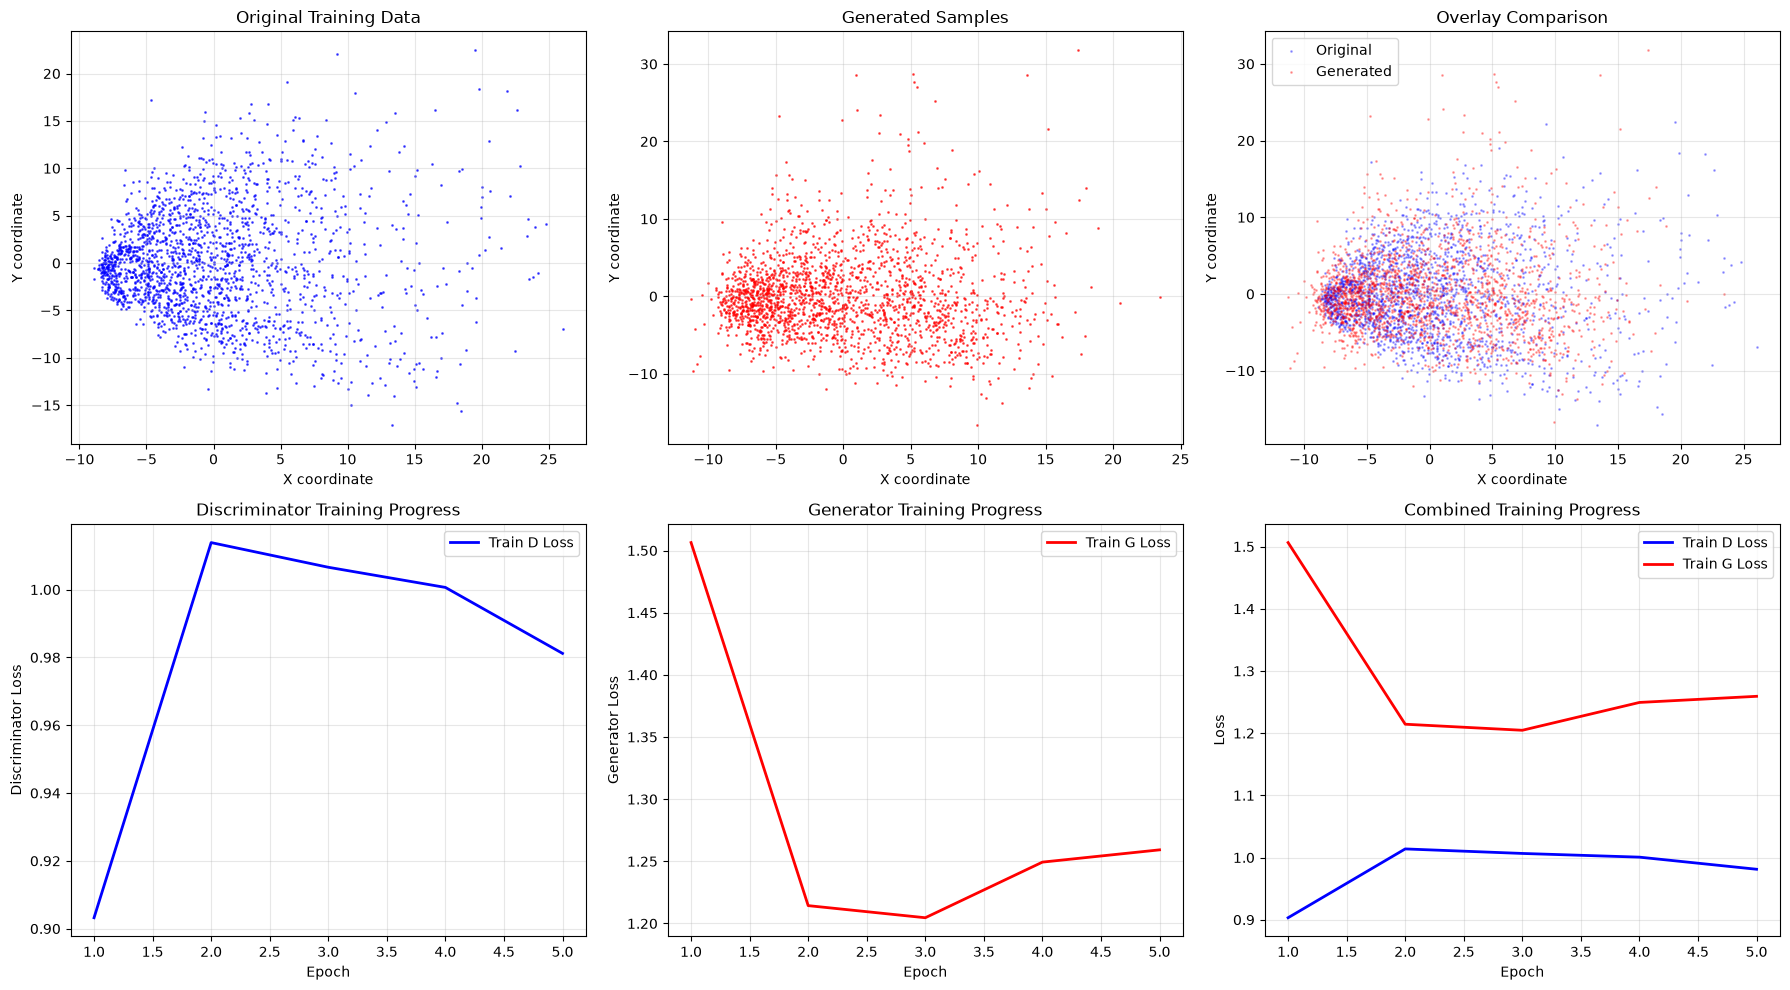

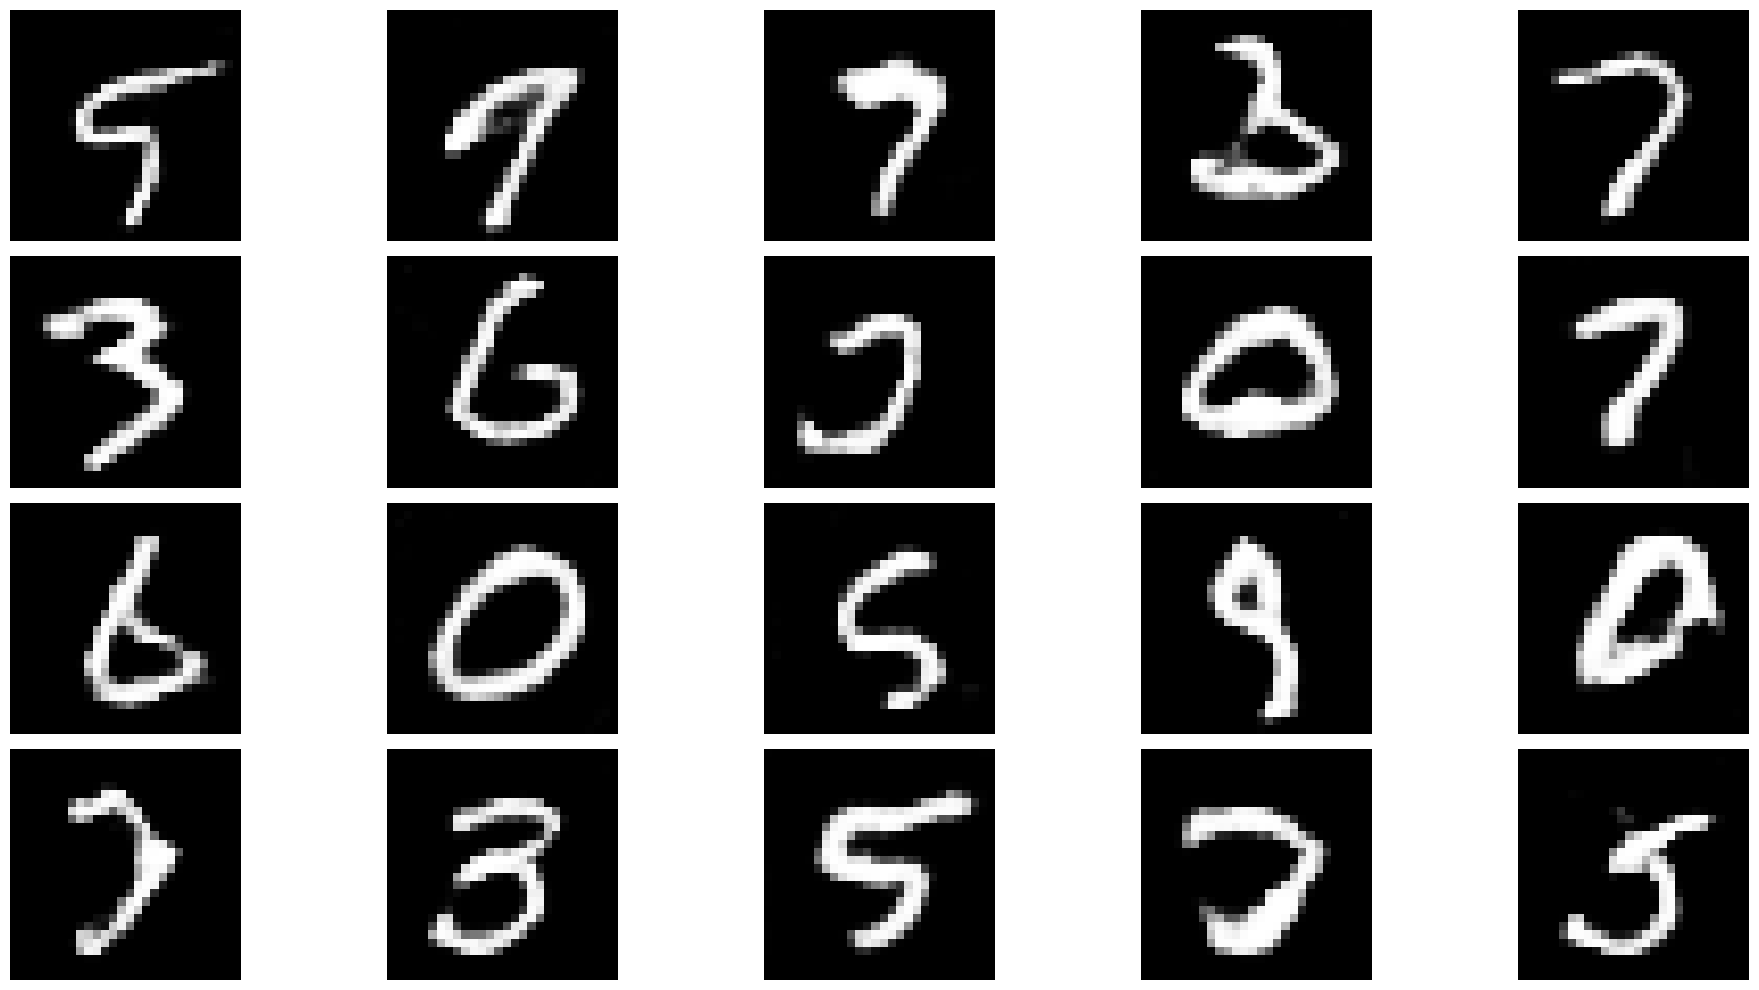

📈 Epoch 5 Summary:
   Train D Loss: 0.9812, Val D Loss: 1.6941
   Train G Loss: 1.2592, Val G Loss: 2.3161

📊 Epoch 6/100
----------------------------------------
Epoch: 6 [0/60000 (0%)]	D_loss: 1.288526	G_loss: 0.701945
Epoch: 6 [6400/60000 (11%)]	D_loss: 0.884189	G_loss: 1.238773
Epoch: 6 [12800/60000 (21%)]	D_loss: 0.950993	G_loss: 1.468532
Epoch: 6 [19200/60000 (32%)]	D_loss: 0.856543	G_loss: 0.812564
Epoch: 6 [25600/60000 (43%)]	D_loss: 0.906237	G_loss: 1.692528
Epoch: 6 [32000/60000 (53%)]	D_loss: 0.874496	G_loss: 1.661732
Epoch: 6 [38400/60000 (64%)]	D_loss: 0.863098	G_loss: 0.913819
Epoch: 6 [44800/60000 (75%)]	D_loss: 0.957804	G_loss: 1.041377
Epoch: 6 [51200/60000 (85%)]	D_loss: 0.915838	G_loss: 1.162810
Epoch: 6 [57600/60000 (96%)]	D_loss: 0.968295	G_loss: 1.004517
====> Epoch: 6 Train D_loss: 0.9696, Train G_loss: 1.2976
====> Epoch: 6 Val D_loss: 1.2242, Val G_loss: 0.6030
📈 Epoch 6 Summary:
   Train D Loss: 0.9696, Val D Loss: 1.2242
   Train G Loss: 1.2976, Val G Loss: 0

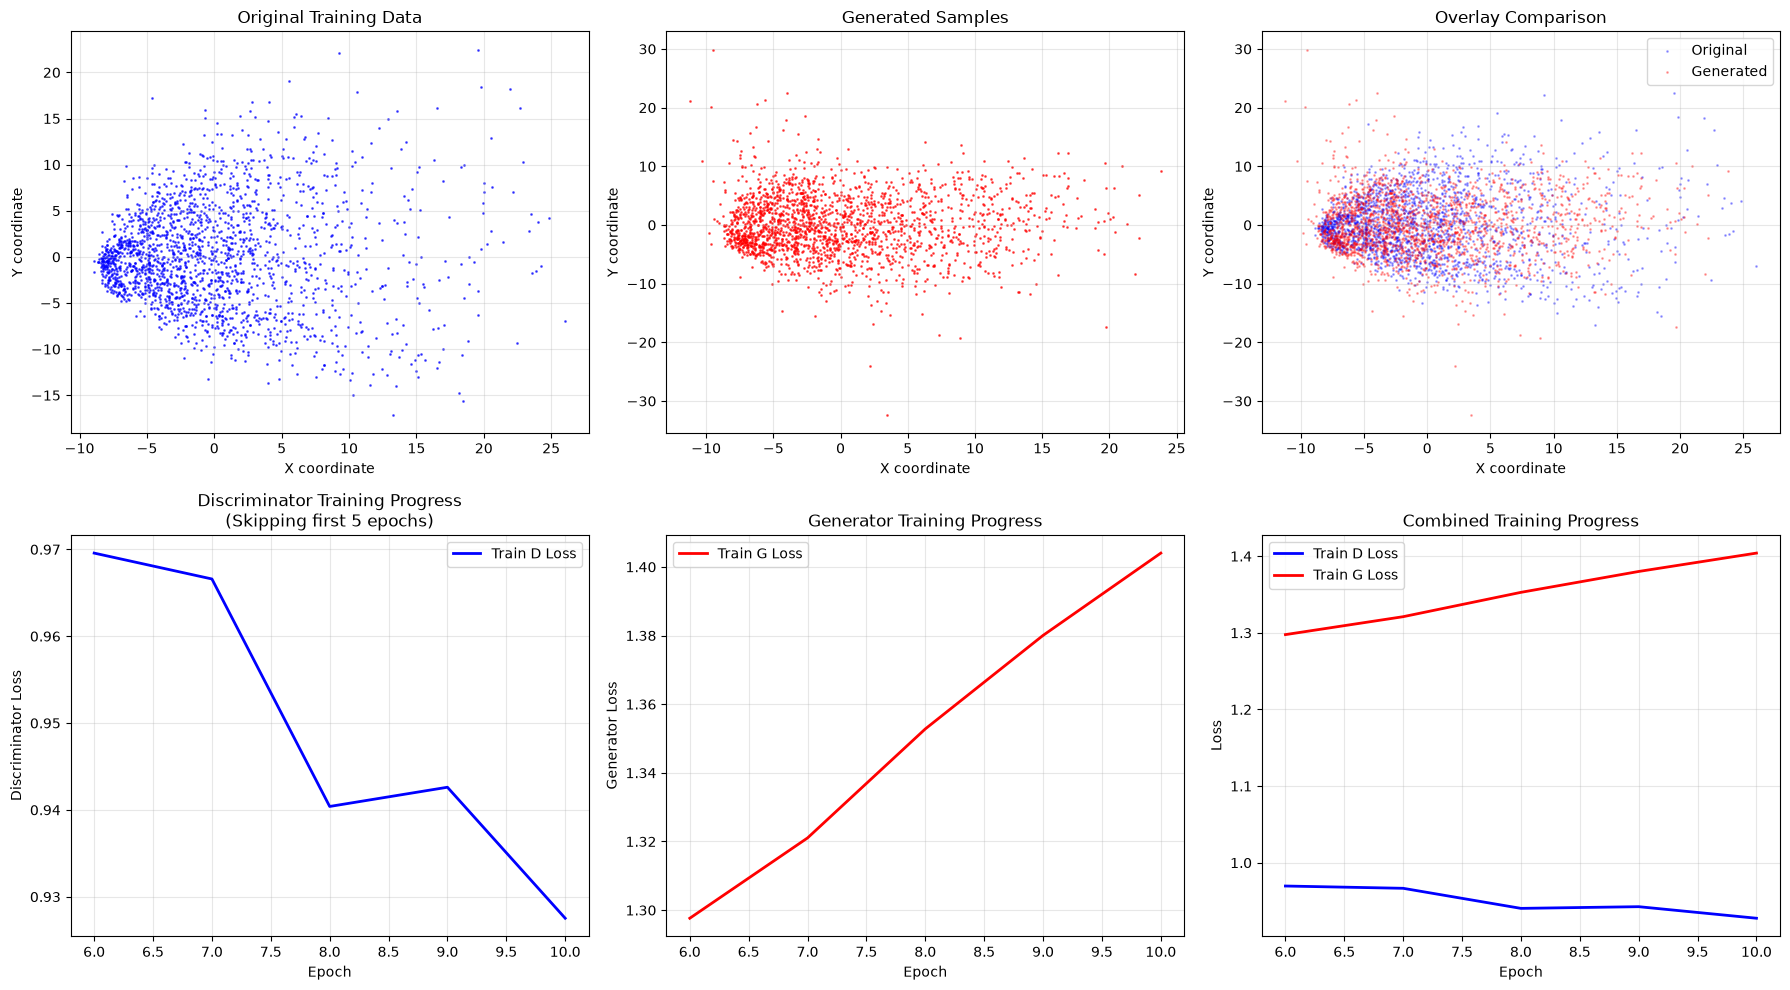

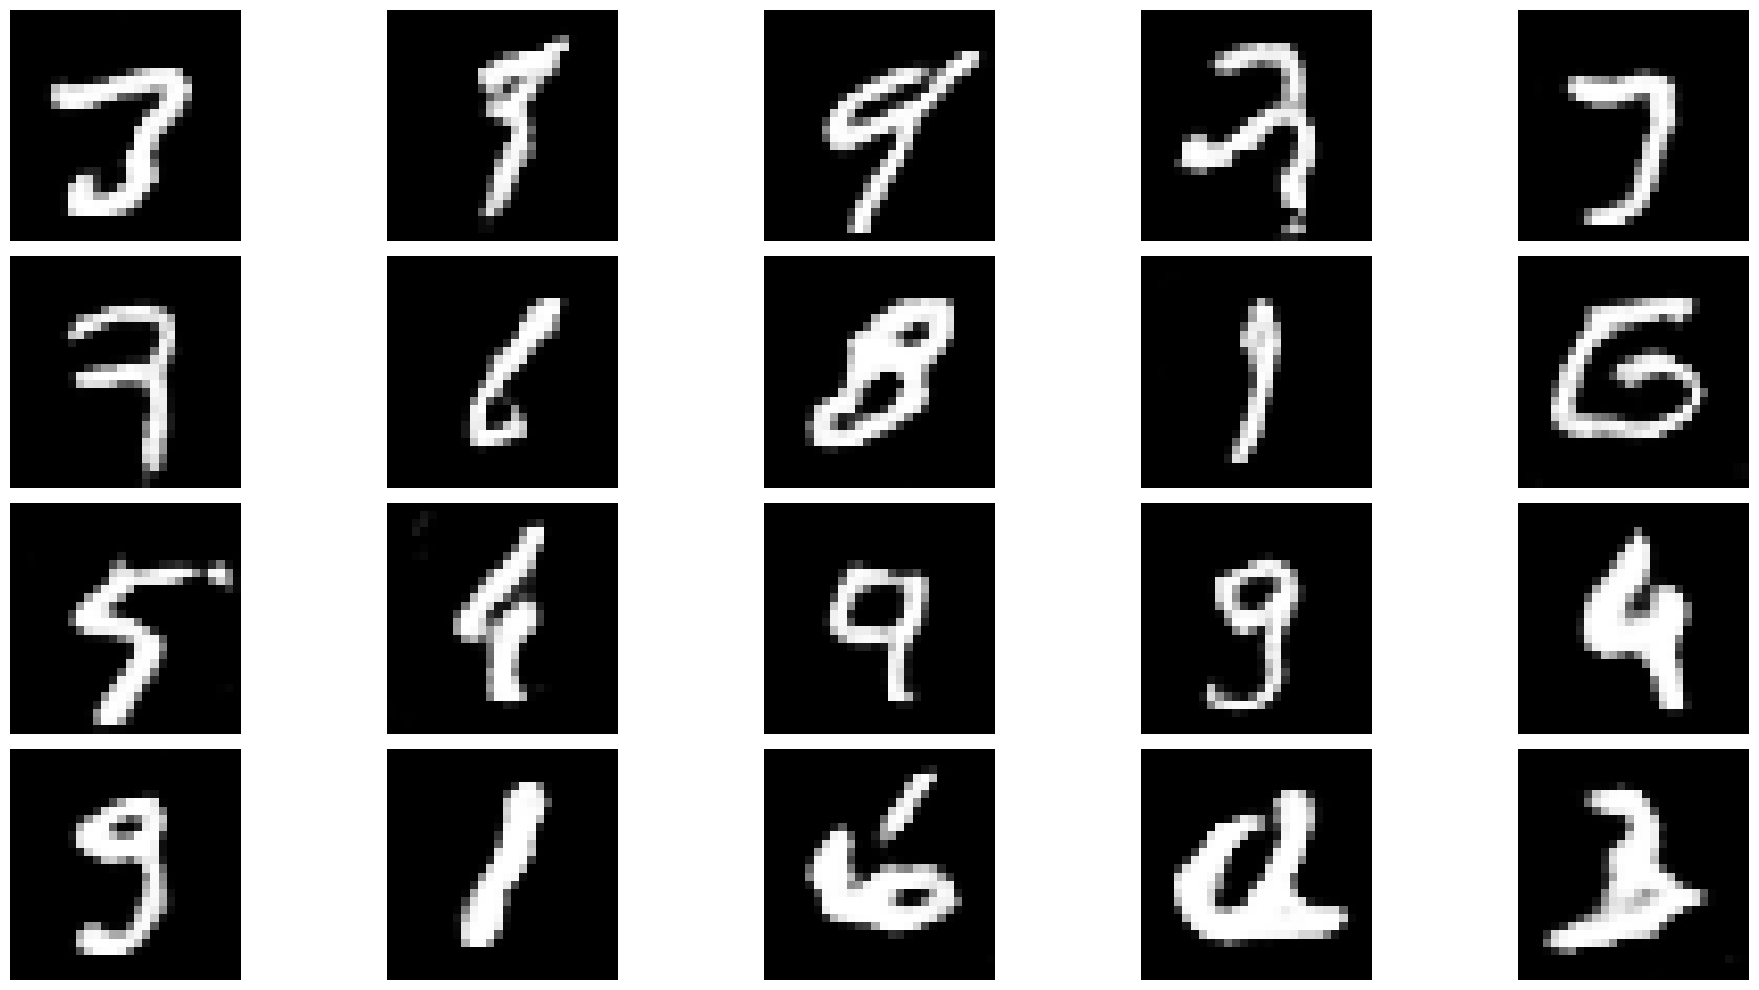

📈 Epoch 10 Summary:
   Train D Loss: 0.9275, Val D Loss: 1.0487
   Train G Loss: 1.4040, Val G Loss: 1.0903

📊 Epoch 11/100
----------------------------------------
Epoch: 11 [0/60000 (0%)]	D_loss: 0.779370	G_loss: 1.629712
Epoch: 11 [6400/60000 (11%)]	D_loss: 0.822198	G_loss: 1.163992
Epoch: 11 [12800/60000 (21%)]	D_loss: 0.916232	G_loss: 0.980375
Epoch: 11 [19200/60000 (32%)]	D_loss: 0.918515	G_loss: 0.935544
Epoch: 11 [25600/60000 (43%)]	D_loss: 1.001009	G_loss: 1.329899
Epoch: 11 [32000/60000 (53%)]	D_loss: 0.806682	G_loss: 1.414214
Epoch: 11 [38400/60000 (64%)]	D_loss: 1.862285	G_loss: 2.196842
Epoch: 11 [44800/60000 (75%)]	D_loss: 1.162207	G_loss: 0.814854
Epoch: 11 [51200/60000 (85%)]	D_loss: 0.893921	G_loss: 1.129147
Epoch: 11 [57600/60000 (96%)]	D_loss: 0.793166	G_loss: 1.761071
====> Epoch: 11 Train D_loss: 0.9153, Train G_loss: 1.4235
====> Epoch: 11 Val D_loss: 1.0380, Val G_loss: 1.1492
📈 Epoch 11 Summary:
   Train D Loss: 0.9153, Val D Loss: 1.0380
   Train G Loss: 1.4235

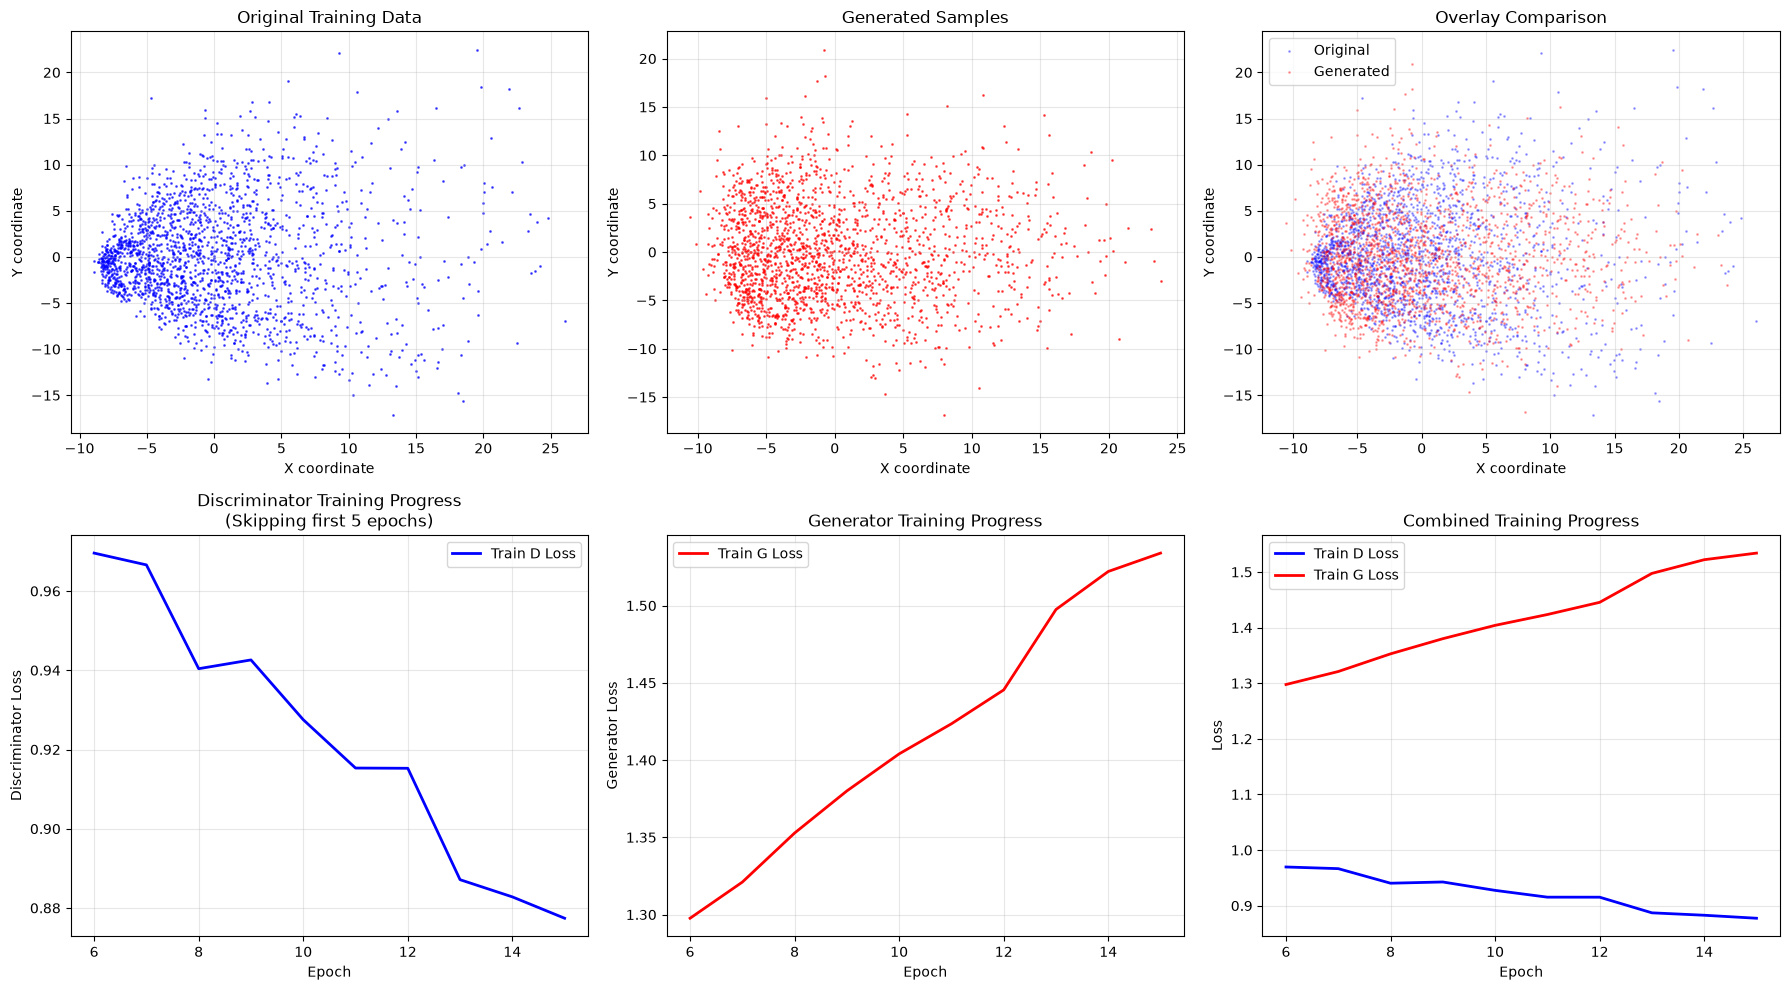

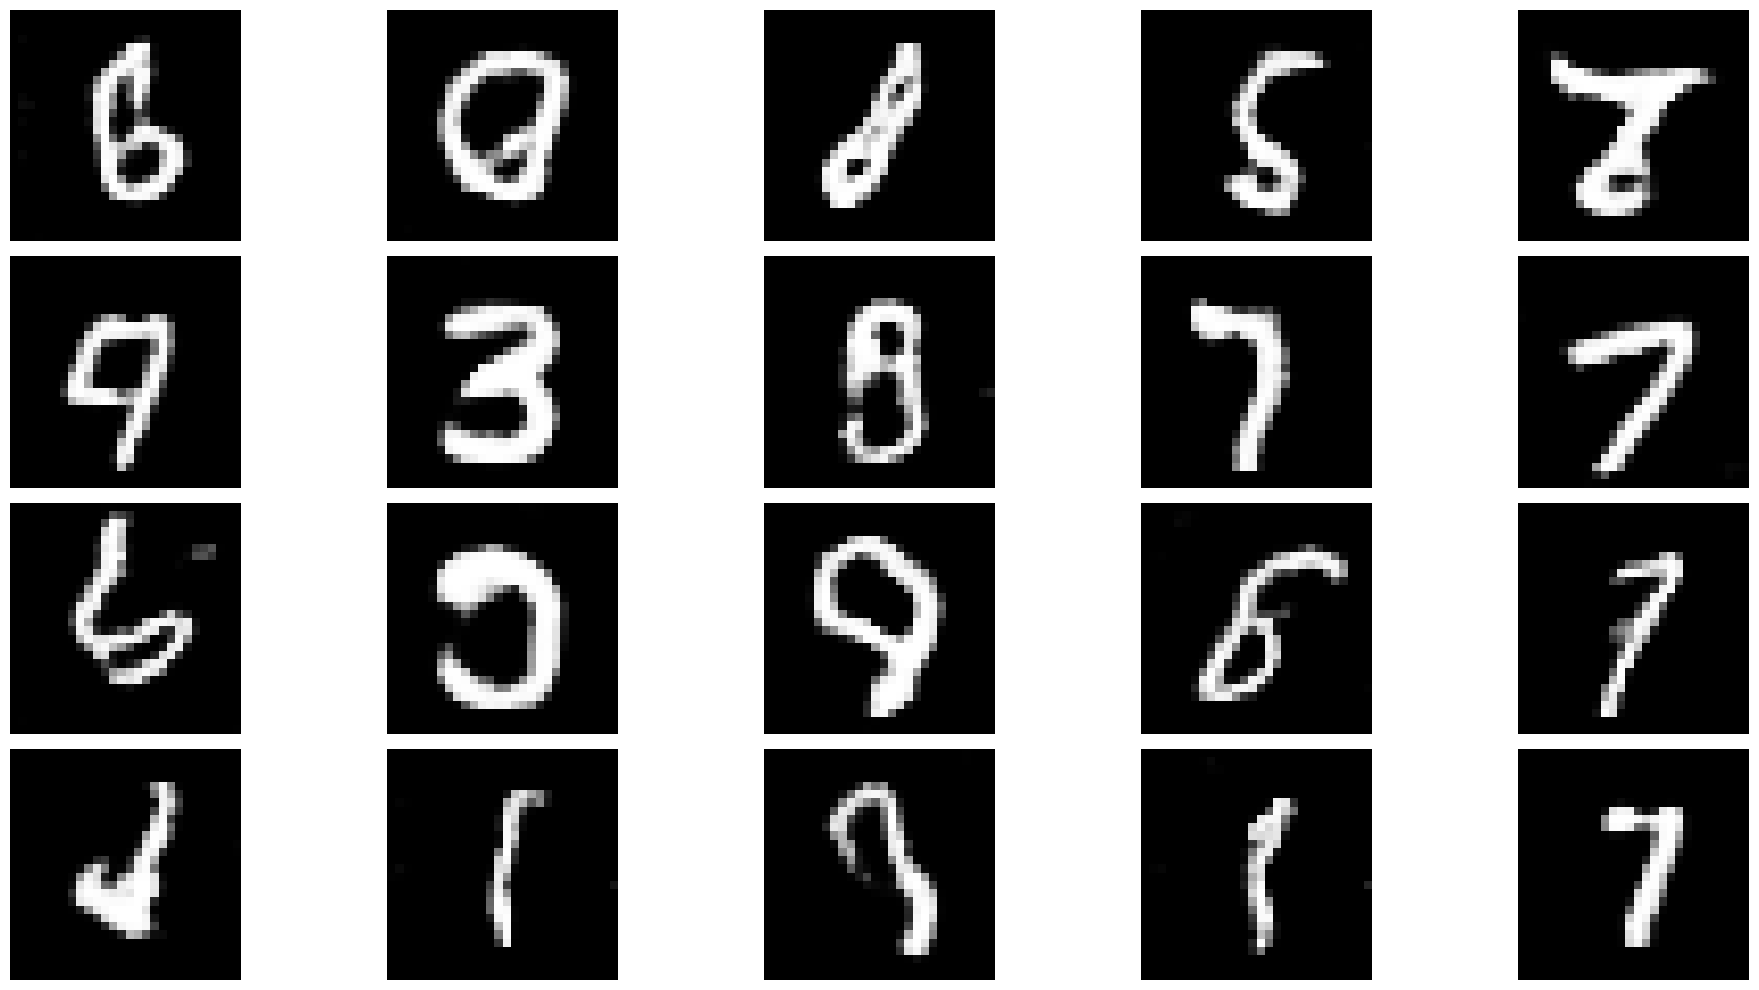

📈 Epoch 15 Summary:
   Train D Loss: 0.8774, Val D Loss: 1.1337
   Train G Loss: 1.5340, Val G Loss: 1.4862

📊 Epoch 16/100
----------------------------------------
Epoch: 16 [0/60000 (0%)]	D_loss: 0.807090	G_loss: 1.087395
Epoch: 16 [6400/60000 (11%)]	D_loss: 0.993301	G_loss: 0.422952
Epoch: 16 [12800/60000 (21%)]	D_loss: 0.898453	G_loss: 1.208171
Epoch: 16 [19200/60000 (32%)]	D_loss: 0.761423	G_loss: 0.876002
Epoch: 16 [25600/60000 (43%)]	D_loss: 1.228133	G_loss: 0.407758
Epoch: 16 [32000/60000 (53%)]	D_loss: 0.838449	G_loss: 1.597517
Epoch: 16 [38400/60000 (64%)]	D_loss: 0.834432	G_loss: 1.283019
Epoch: 16 [44800/60000 (75%)]	D_loss: 0.918696	G_loss: 0.944107
Epoch: 16 [51200/60000 (85%)]	D_loss: 0.615457	G_loss: 0.957276
Epoch: 16 [57600/60000 (96%)]	D_loss: 0.959729	G_loss: 2.092175
====> Epoch: 16 Train D_loss: 0.8555, Train G_loss: 1.5512
====> Epoch: 16 Val D_loss: 1.0821, Val G_loss: 1.4454
📈 Epoch 16 Summary:
   Train D Loss: 0.8555, Val D Loss: 1.0821
   Train G Loss: 1.5512

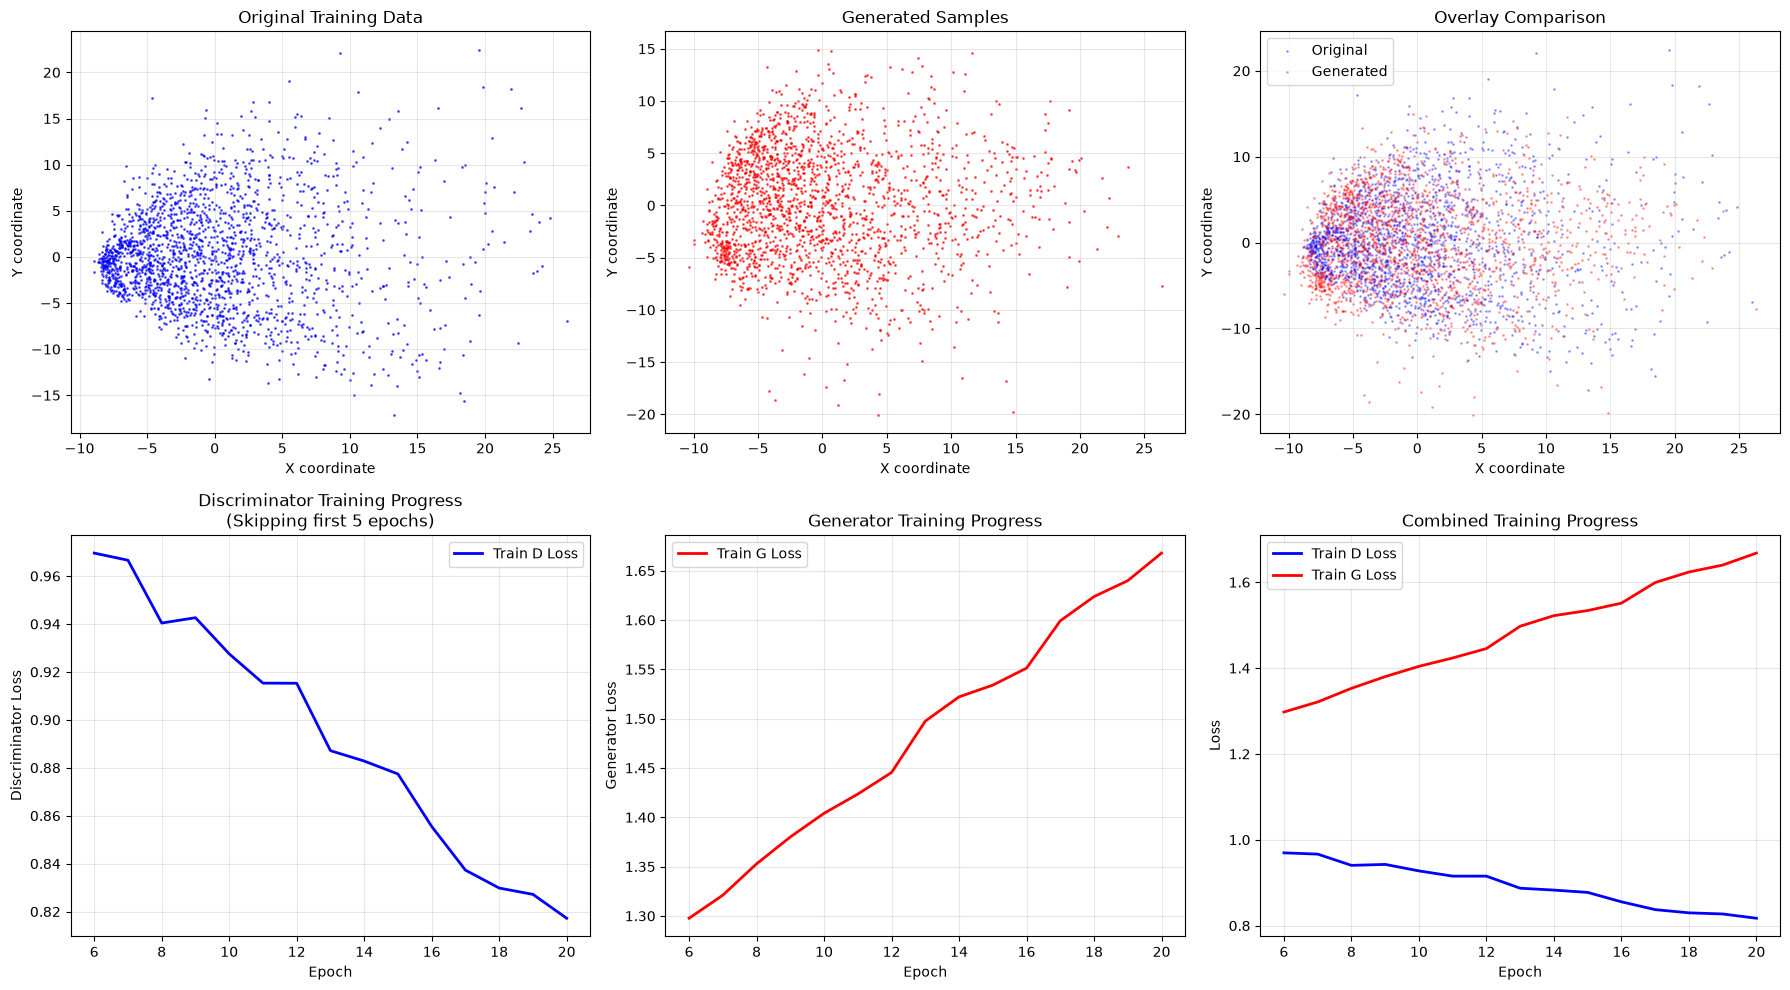

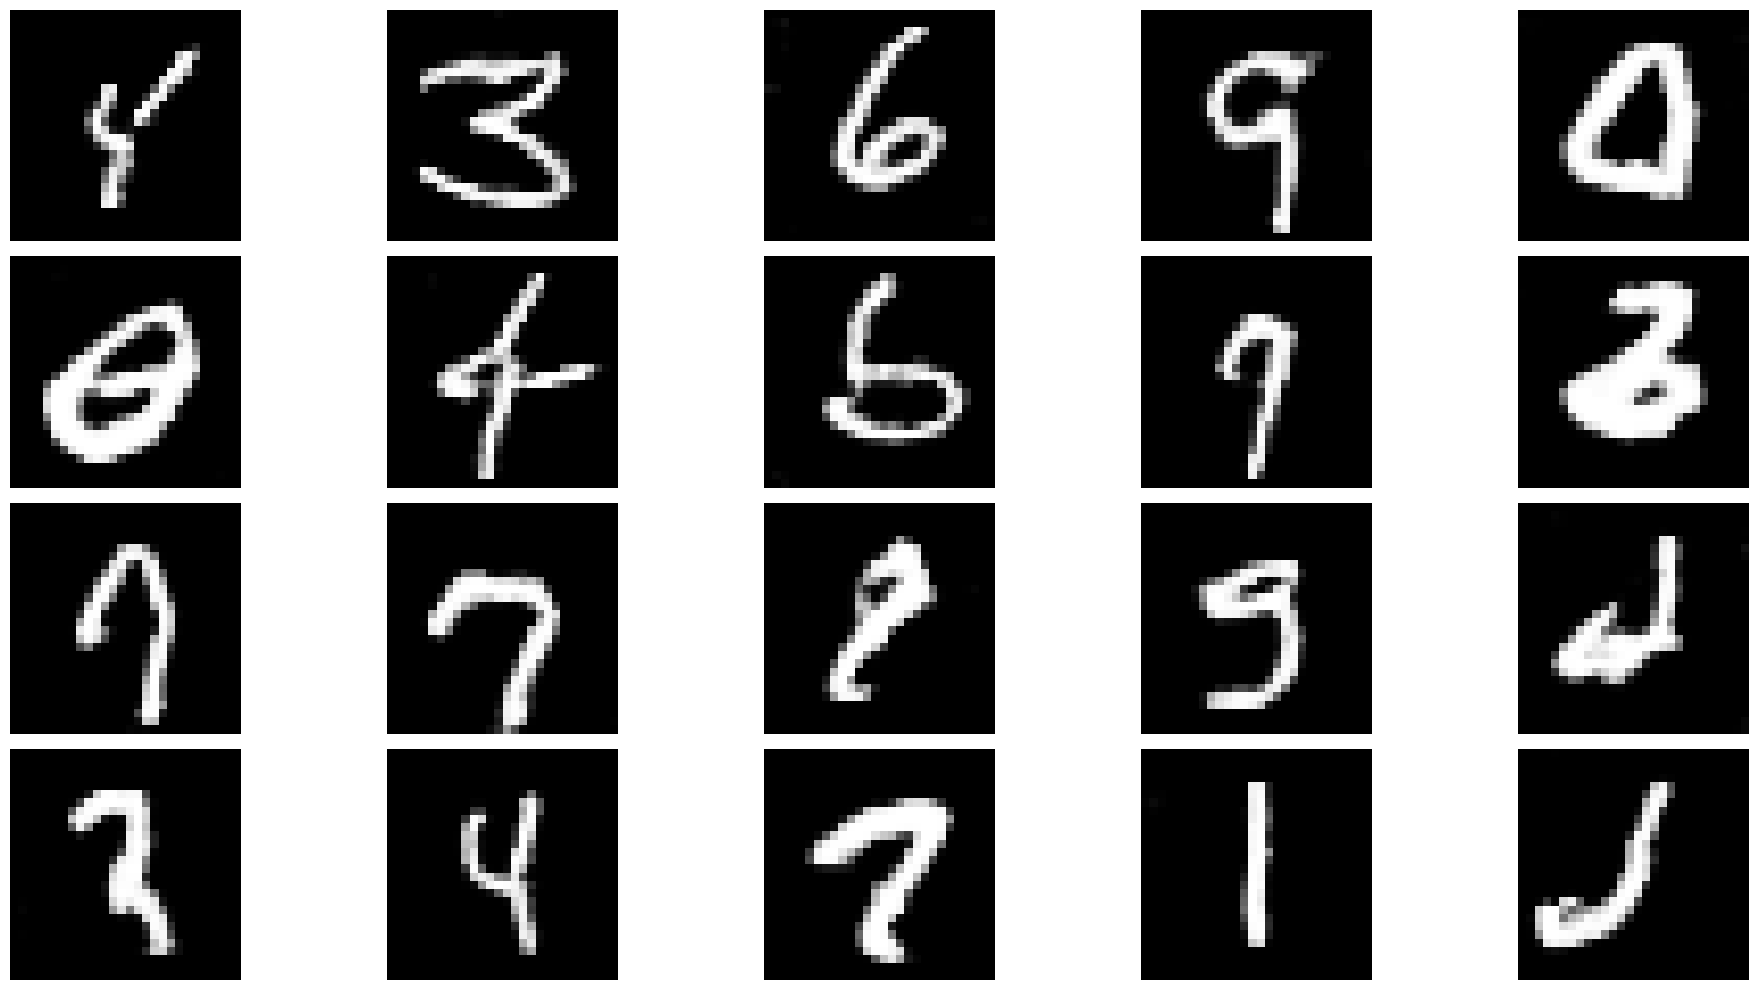

📈 Epoch 20 Summary:
   Train D Loss: 0.8172, Val D Loss: 1.0175
   Train G Loss: 1.6678, Val G Loss: 1.0653

📊 Epoch 21/100
----------------------------------------
Epoch: 21 [0/60000 (0%)]	D_loss: 0.653293	G_loss: 1.867528
Epoch: 21 [6400/60000 (11%)]	D_loss: 0.608258	G_loss: 1.945947
Epoch: 21 [12800/60000 (21%)]	D_loss: 0.776813	G_loss: 1.958909
Epoch: 21 [19200/60000 (32%)]	D_loss: 0.922746	G_loss: 1.833461
Epoch: 21 [25600/60000 (43%)]	D_loss: 0.661988	G_loss: 1.745098
Epoch: 21 [32000/60000 (53%)]	D_loss: 0.846611	G_loss: 1.379101
Epoch: 21 [38400/60000 (64%)]	D_loss: 0.762586	G_loss: 2.504648
Epoch: 21 [44800/60000 (75%)]	D_loss: 0.710960	G_loss: 1.603850
Epoch: 21 [51200/60000 (85%)]	D_loss: 0.757339	G_loss: 1.320109
Epoch: 21 [57600/60000 (96%)]	D_loss: 1.125006	G_loss: 2.887414
====> Epoch: 21 Train D_loss: 0.8032, Train G_loss: 1.6802
====> Epoch: 21 Val D_loss: 1.6305, Val G_loss: 2.6940
📈 Epoch 21 Summary:
   Train D Loss: 0.8032, Val D Loss: 1.6305
   Train G Loss: 1.6802

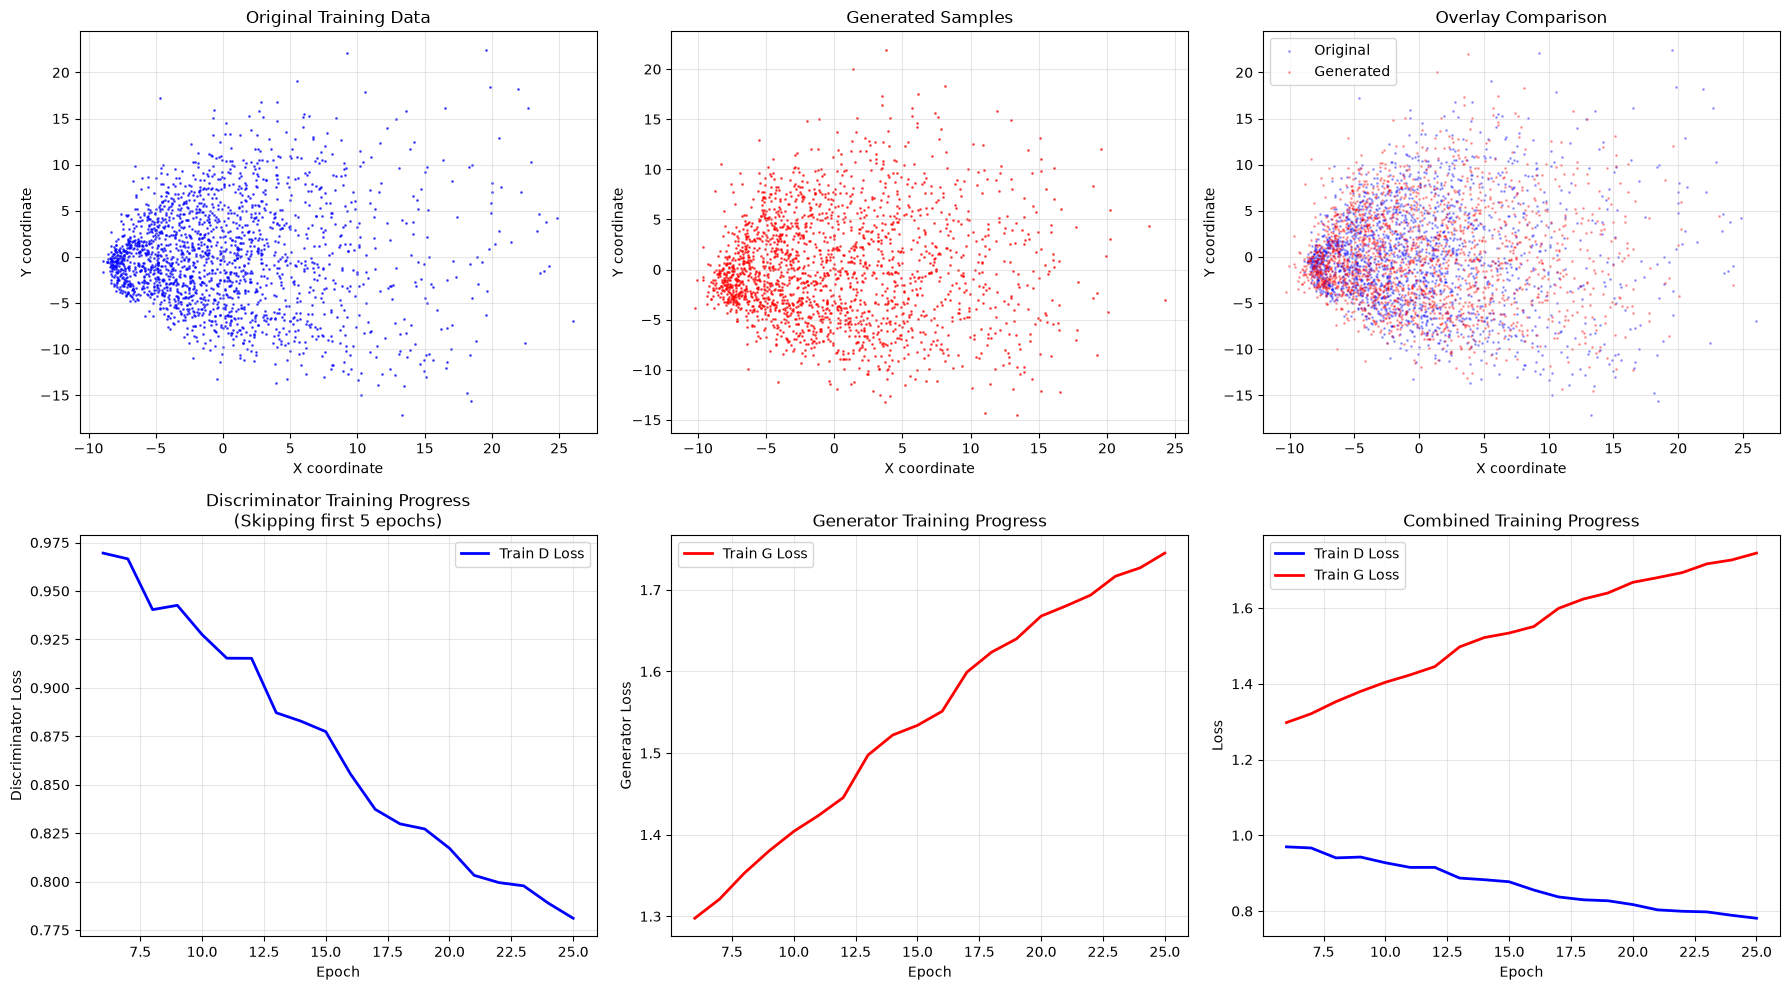

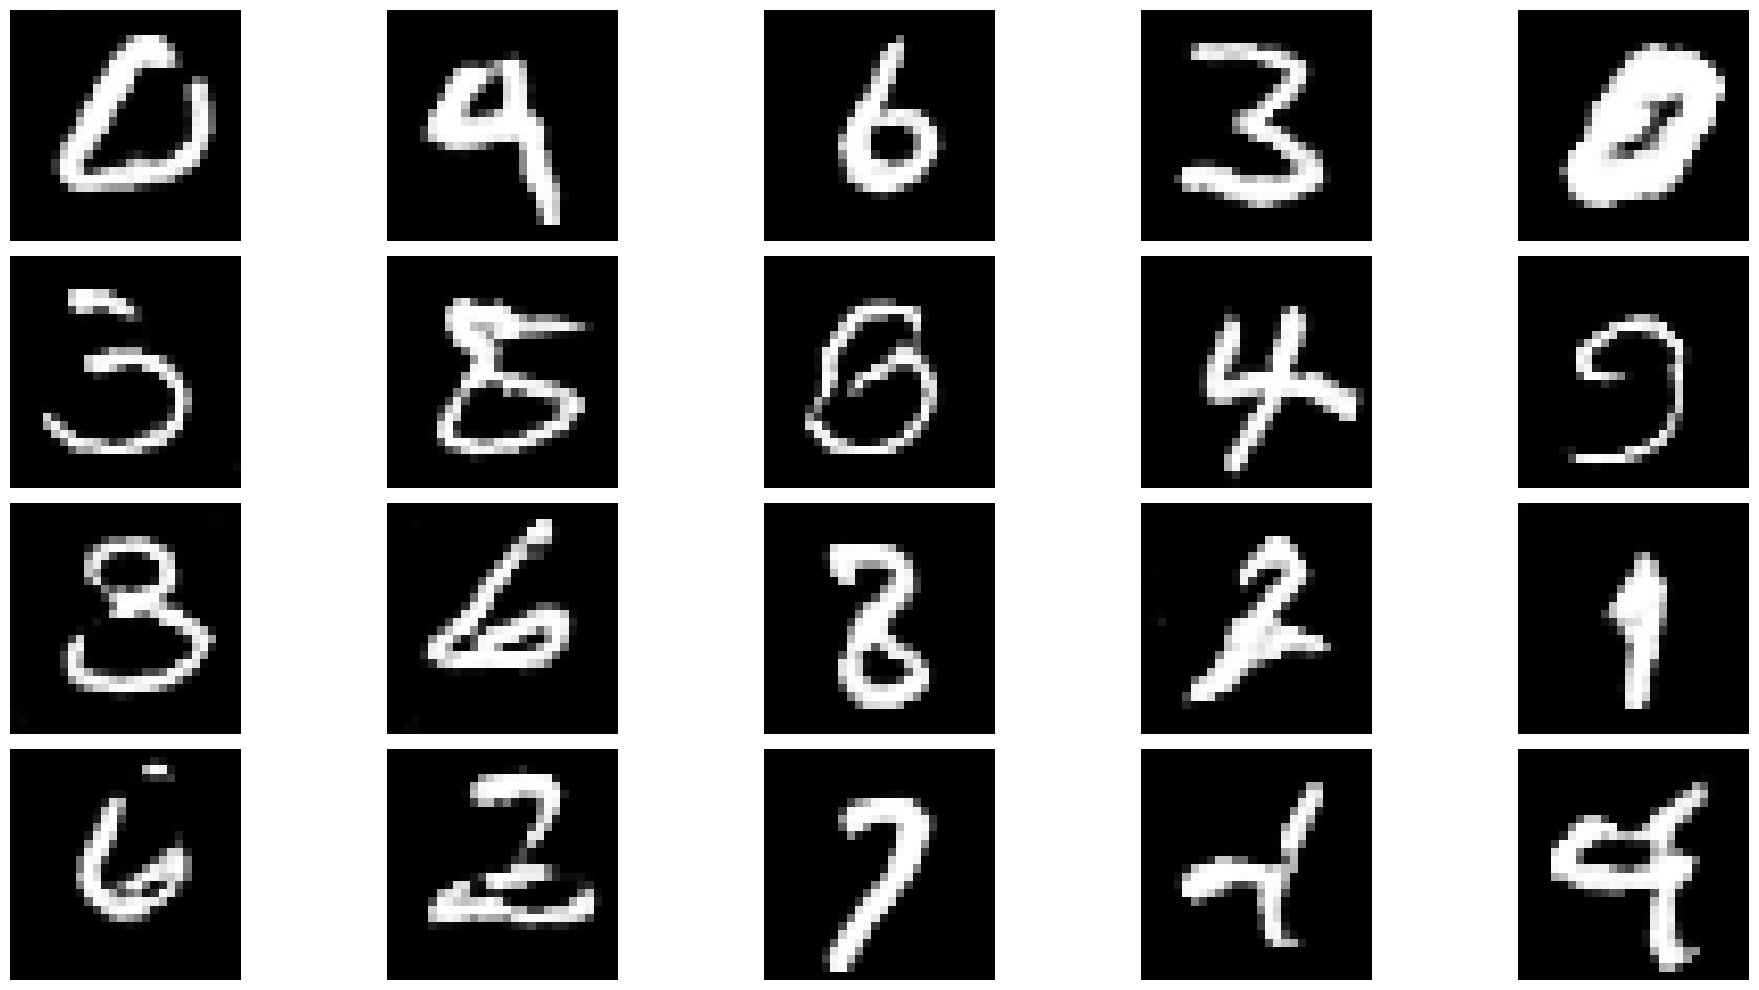

📈 Epoch 25 Summary:
   Train D Loss: 0.7811, Val D Loss: 1.0408
   Train G Loss: 1.7450, Val G Loss: 1.6625

📊 Epoch 26/100
----------------------------------------
Epoch: 26 [0/60000 (0%)]	D_loss: 0.663284	G_loss: 2.119294
Epoch: 26 [6400/60000 (11%)]	D_loss: 0.764177	G_loss: 0.873367
Epoch: 26 [12800/60000 (21%)]	D_loss: 0.705205	G_loss: 2.414924
Epoch: 26 [19200/60000 (32%)]	D_loss: 0.618067	G_loss: 2.144209
Epoch: 26 [25600/60000 (43%)]	D_loss: 0.872543	G_loss: 1.620773
Epoch: 26 [32000/60000 (53%)]	D_loss: 0.694853	G_loss: 1.532013
Epoch: 26 [38400/60000 (64%)]	D_loss: 1.019860	G_loss: 2.488983
Epoch: 26 [44800/60000 (75%)]	D_loss: 0.595102	G_loss: 1.869401
Epoch: 26 [51200/60000 (85%)]	D_loss: 1.445932	G_loss: 2.913044
Epoch: 26 [57600/60000 (96%)]	D_loss: 0.599609	G_loss: 1.762851
====> Epoch: 26 Train D_loss: 0.7778, Train G_loss: 1.7727
====> Epoch: 26 Val D_loss: 1.6179, Val G_loss: 2.7978
📈 Epoch 26 Summary:
   Train D Loss: 0.7778, Val D Loss: 1.6179
   Train G Loss: 1.7727

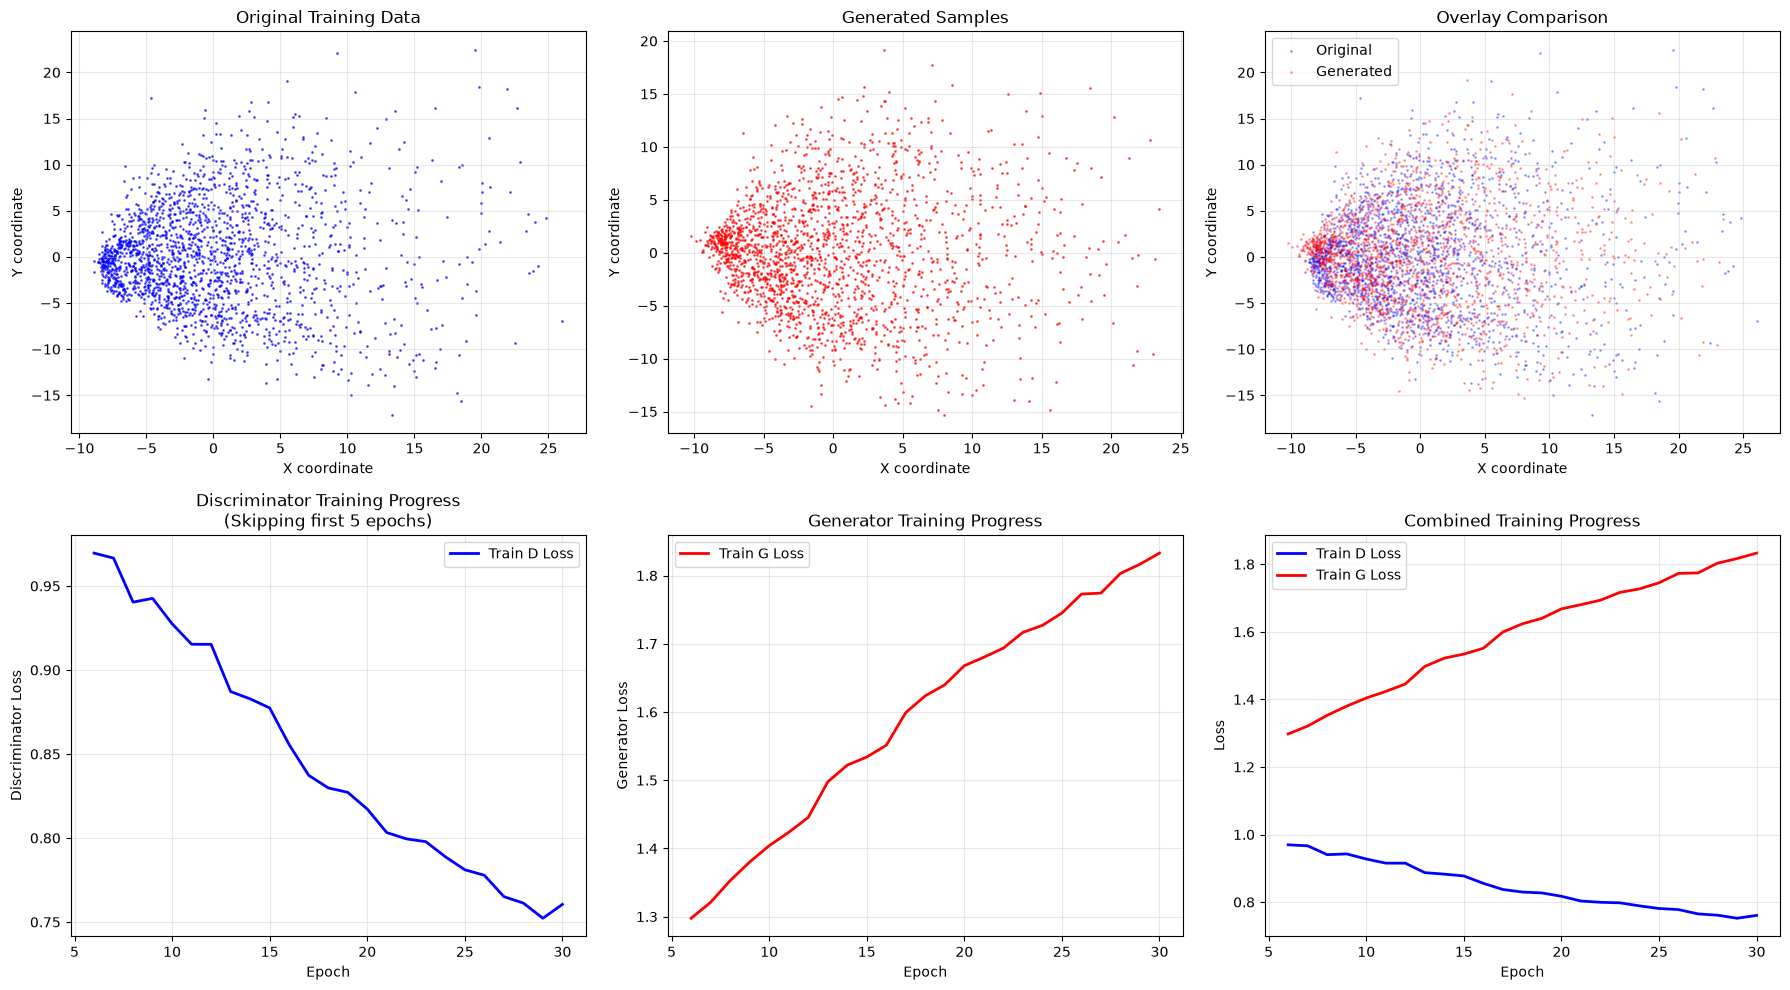

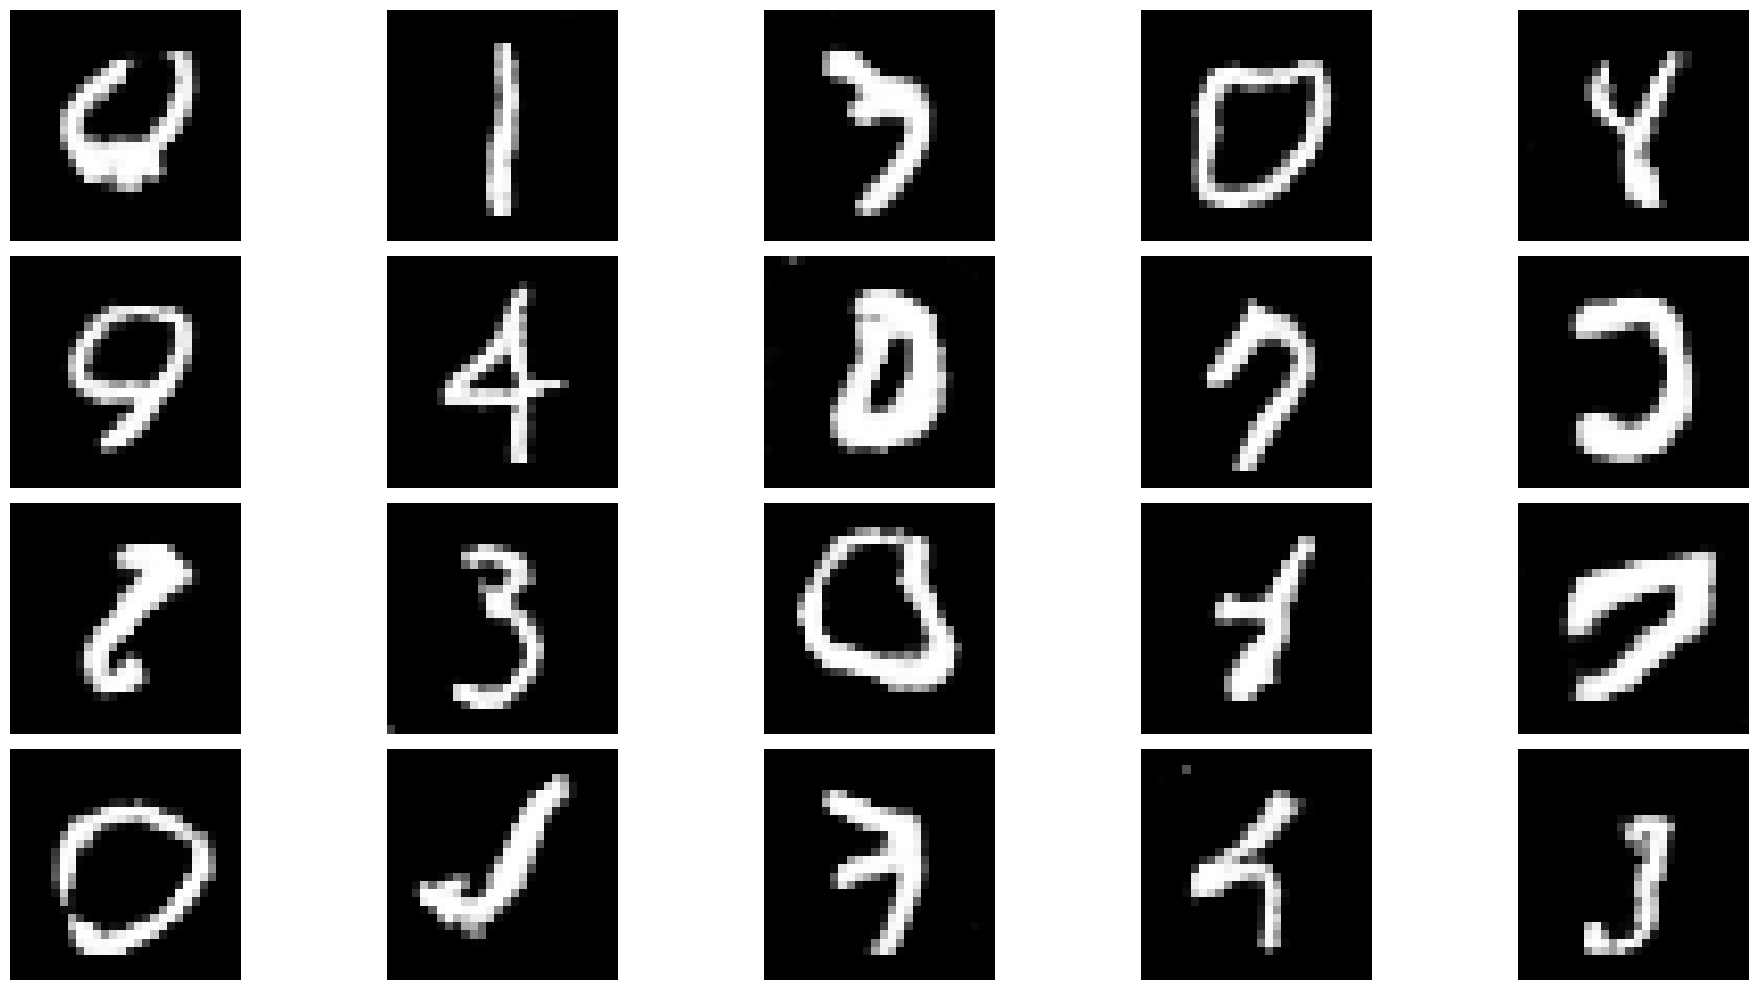

📈 Epoch 30 Summary:
   Train D Loss: 0.7605, Val D Loss: 1.2014
   Train G Loss: 1.8329, Val G Loss: 0.7627

📊 Epoch 31/100
----------------------------------------
Epoch: 31 [0/60000 (0%)]	D_loss: 0.642170	G_loss: 1.054319
Epoch: 31 [6400/60000 (11%)]	D_loss: 0.741982	G_loss: 1.860308
Epoch: 31 [12800/60000 (21%)]	D_loss: 0.633616	G_loss: 1.681817
Epoch: 31 [19200/60000 (32%)]	D_loss: 0.758742	G_loss: 2.403989
Epoch: 31 [25600/60000 (43%)]	D_loss: 0.636919	G_loss: 0.790463
Epoch: 31 [32000/60000 (53%)]	D_loss: 0.636734	G_loss: 1.442059
Epoch: 31 [38400/60000 (64%)]	D_loss: 0.647488	G_loss: 1.828227
Epoch: 31 [44800/60000 (75%)]	D_loss: 0.662489	G_loss: 1.739841
Epoch: 31 [51200/60000 (85%)]	D_loss: 0.860452	G_loss: 1.154968
Epoch: 31 [57600/60000 (96%)]	D_loss: 0.841054	G_loss: 1.337490
====> Epoch: 31 Train D_loss: 0.7574, Train G_loss: 1.8180
====> Epoch: 31 Val D_loss: 1.3956, Val G_loss: 2.4467
📈 Epoch 31 Summary:
   Train D Loss: 0.7574, Val D Loss: 1.3956
   Train G Loss: 1.8180

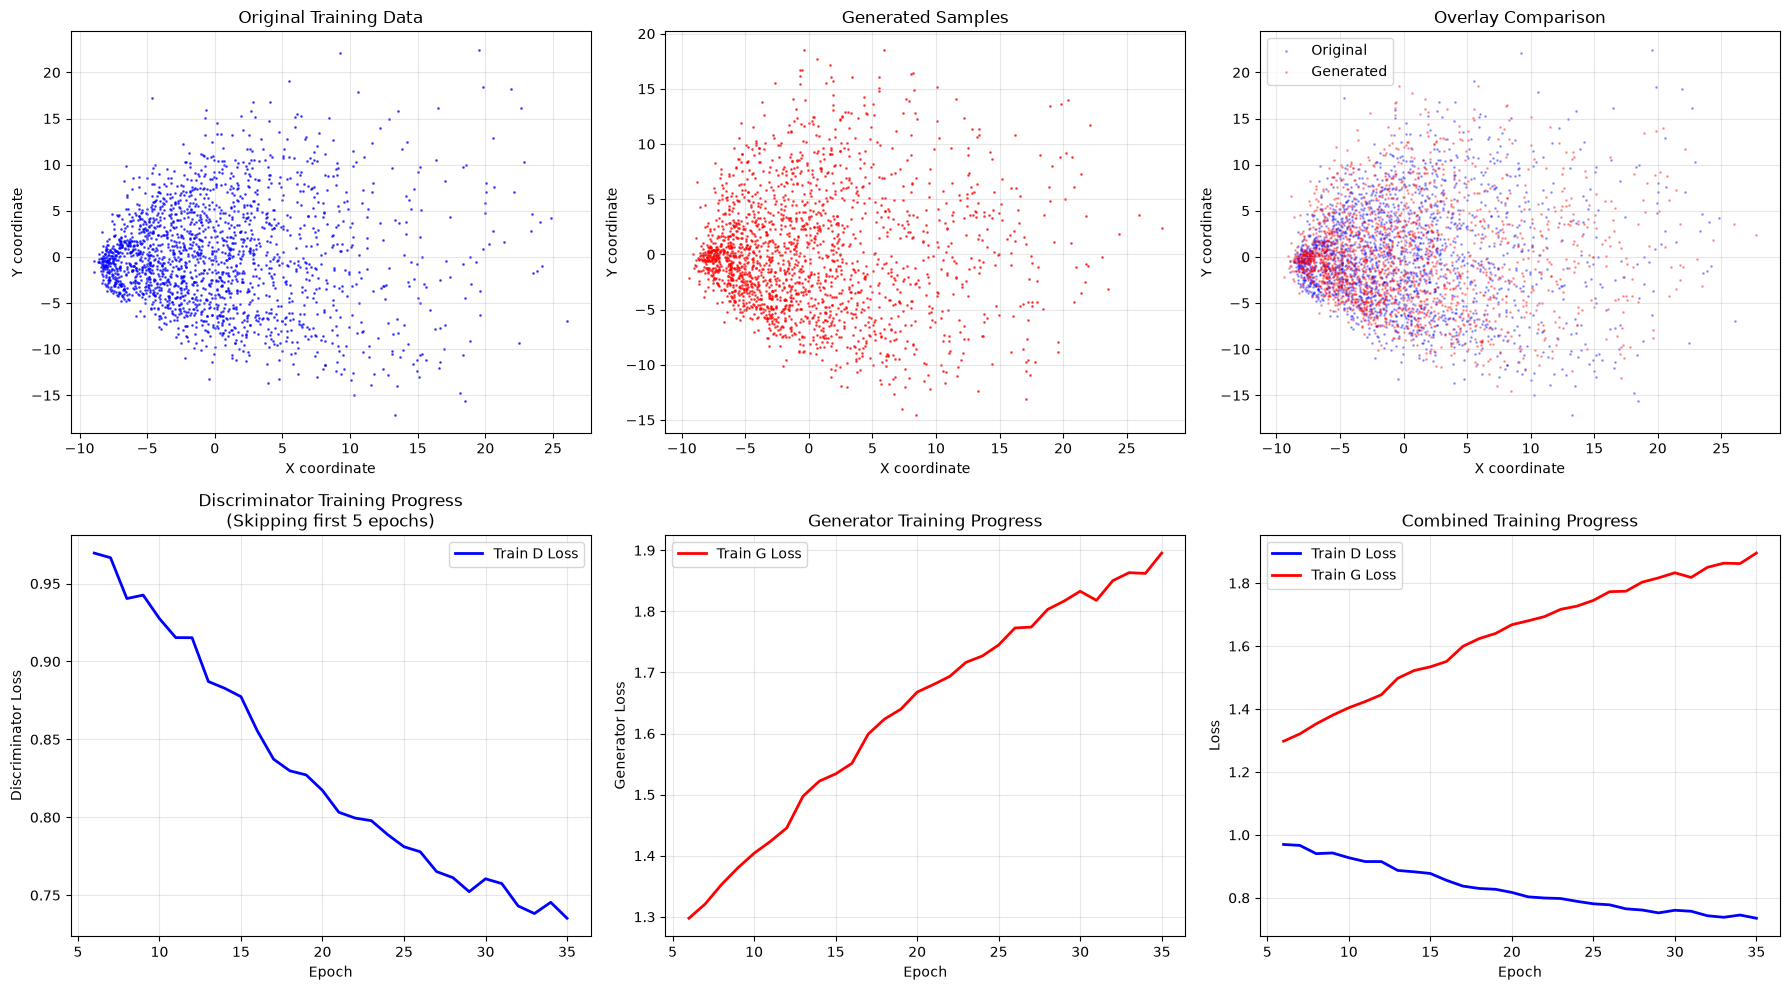

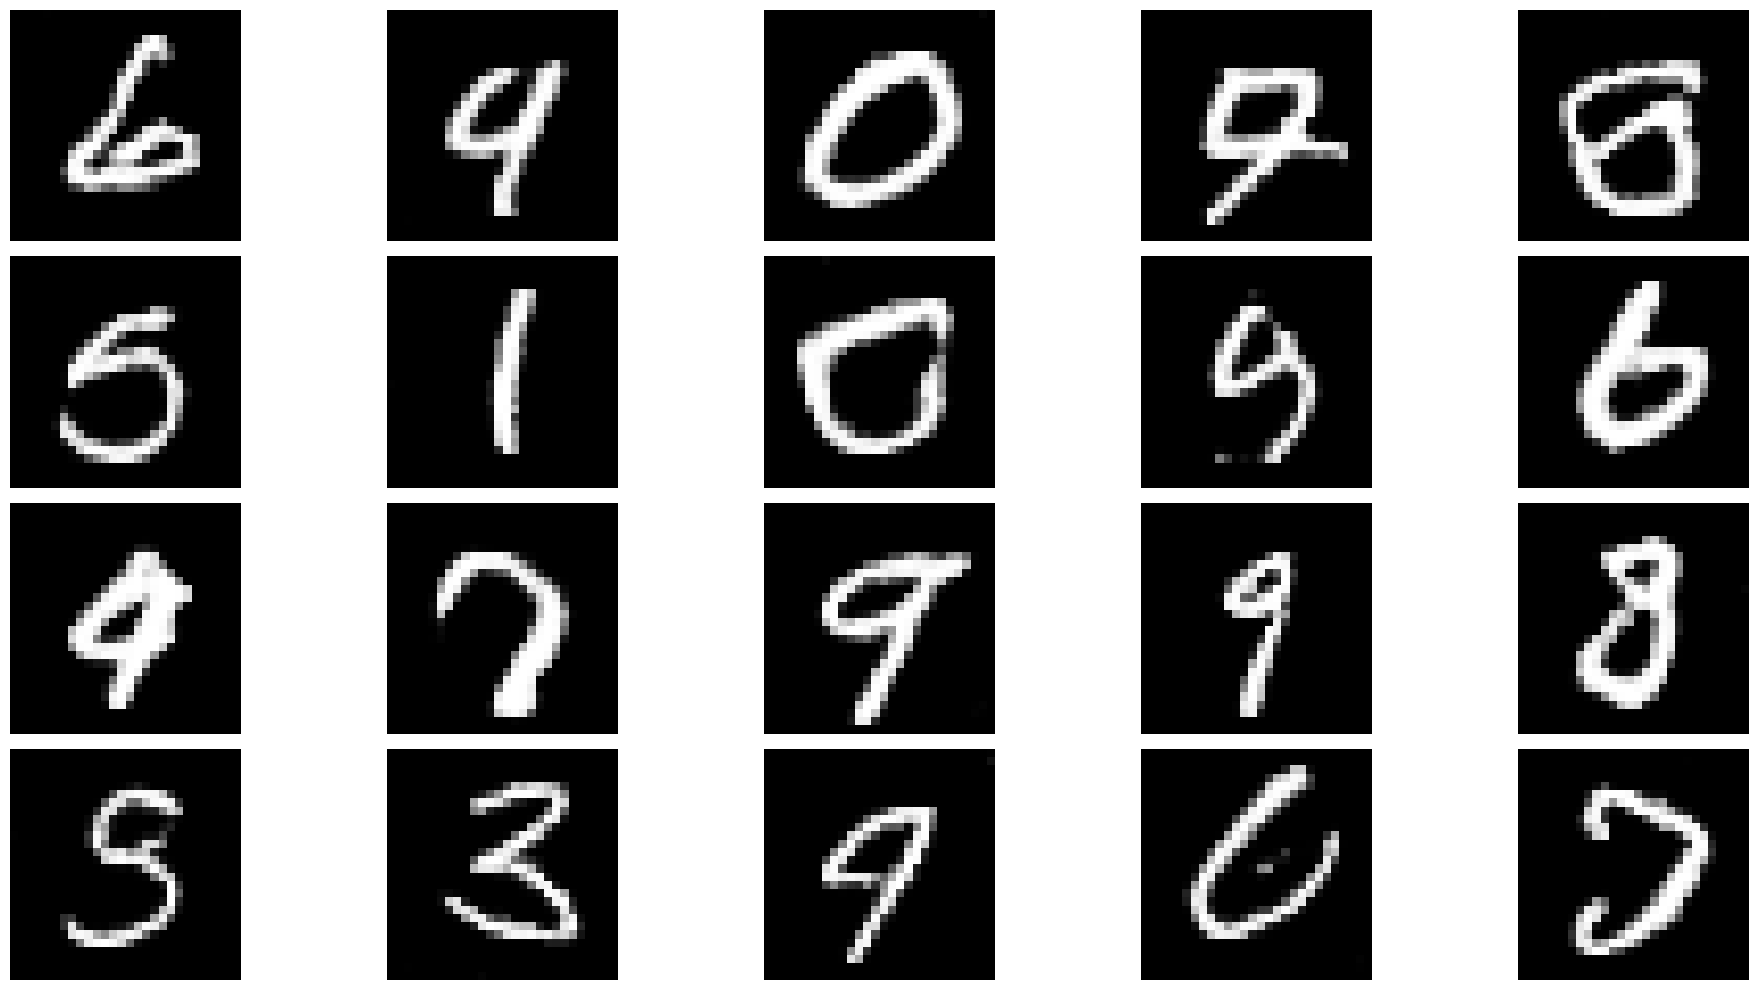

📈 Epoch 35 Summary:
   Train D Loss: 0.7352, Val D Loss: 1.0172
   Train G Loss: 1.8954, Val G Loss: 1.2169

📊 Epoch 36/100
----------------------------------------
Epoch: 36 [0/60000 (0%)]	D_loss: 0.576285	G_loss: 1.847511
Epoch: 36 [6400/60000 (11%)]	D_loss: 0.629890	G_loss: 2.253217
Epoch: 36 [12800/60000 (21%)]	D_loss: 0.916723	G_loss: 2.613564
Epoch: 36 [19200/60000 (32%)]	D_loss: 0.639869	G_loss: 2.638768
Epoch: 36 [25600/60000 (43%)]	D_loss: 1.049118	G_loss: 0.690922
Epoch: 36 [32000/60000 (53%)]	D_loss: 0.603331	G_loss: 2.739842
Epoch: 36 [38400/60000 (64%)]	D_loss: 0.575796	G_loss: 2.195491
Epoch: 36 [44800/60000 (75%)]	D_loss: 0.947160	G_loss: 2.816169
Epoch: 36 [51200/60000 (85%)]	D_loss: 1.124521	G_loss: 3.134973
Epoch: 36 [57600/60000 (96%)]	D_loss: 0.758040	G_loss: 0.738378
====> Epoch: 36 Train D_loss: 0.7442, Train G_loss: 1.8930
====> Epoch: 36 Val D_loss: 2.0803, Val G_loss: 3.5252
📈 Epoch 36 Summary:
   Train D Loss: 0.7442, Val D Loss: 2.0803
   Train G Loss: 1.8930

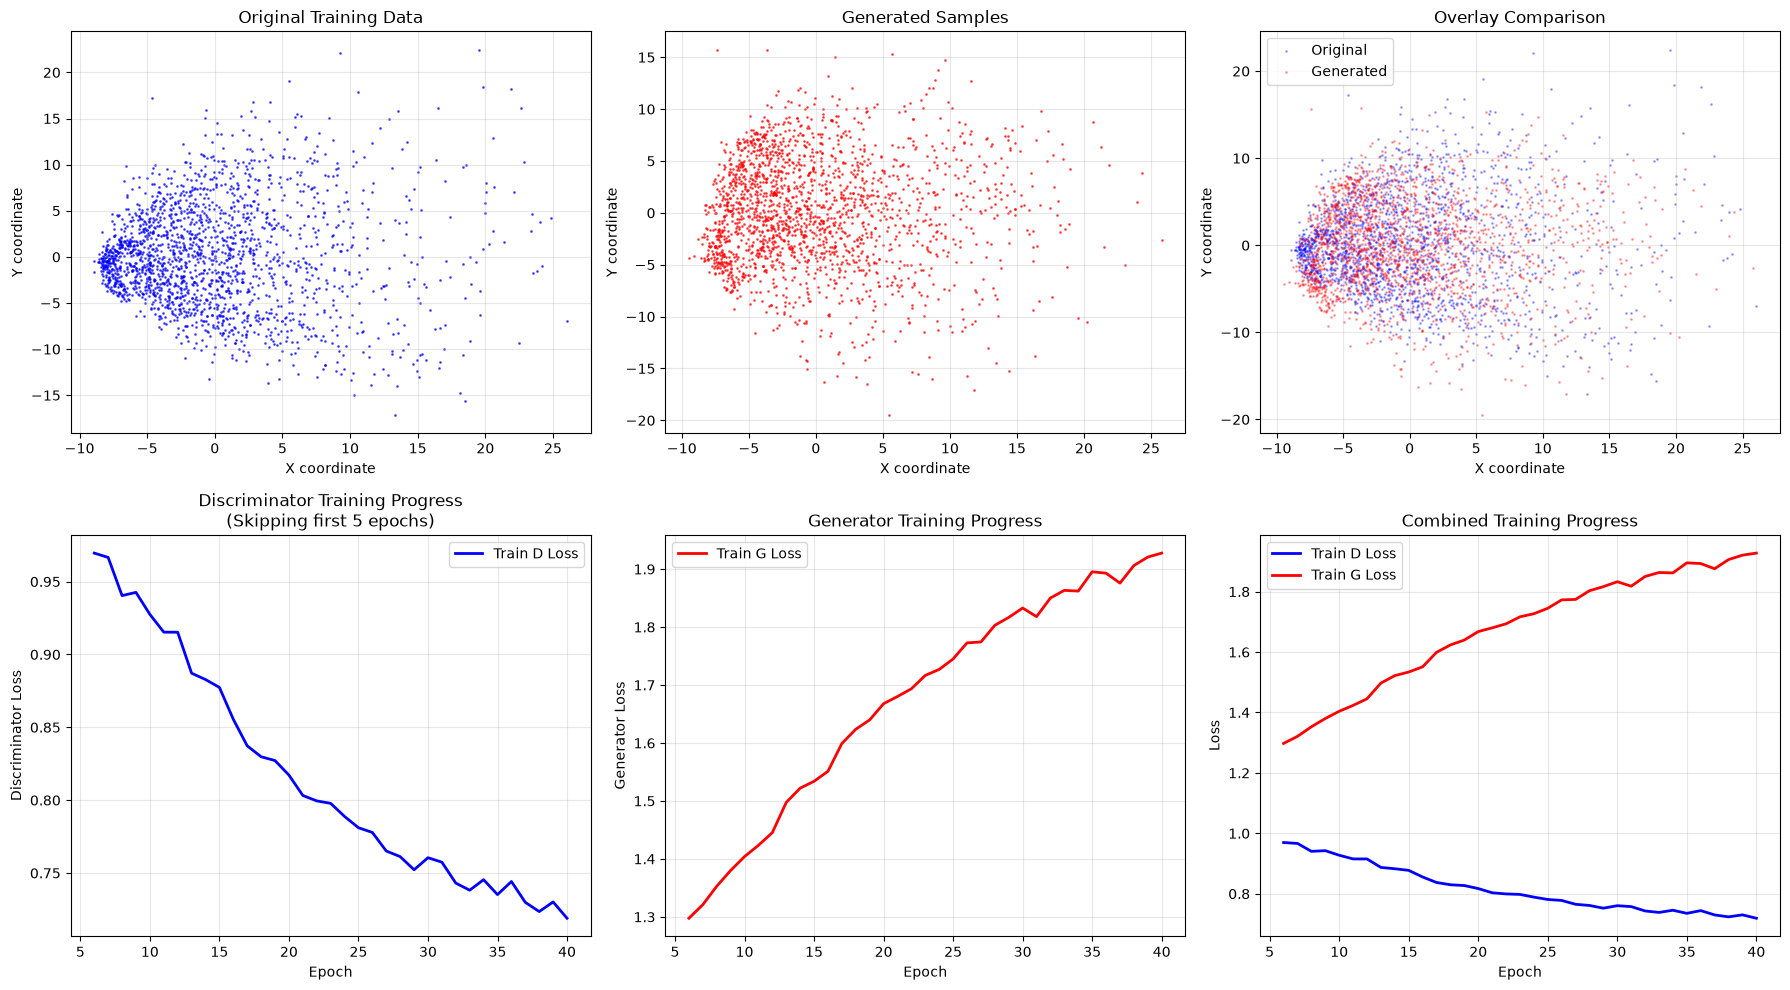

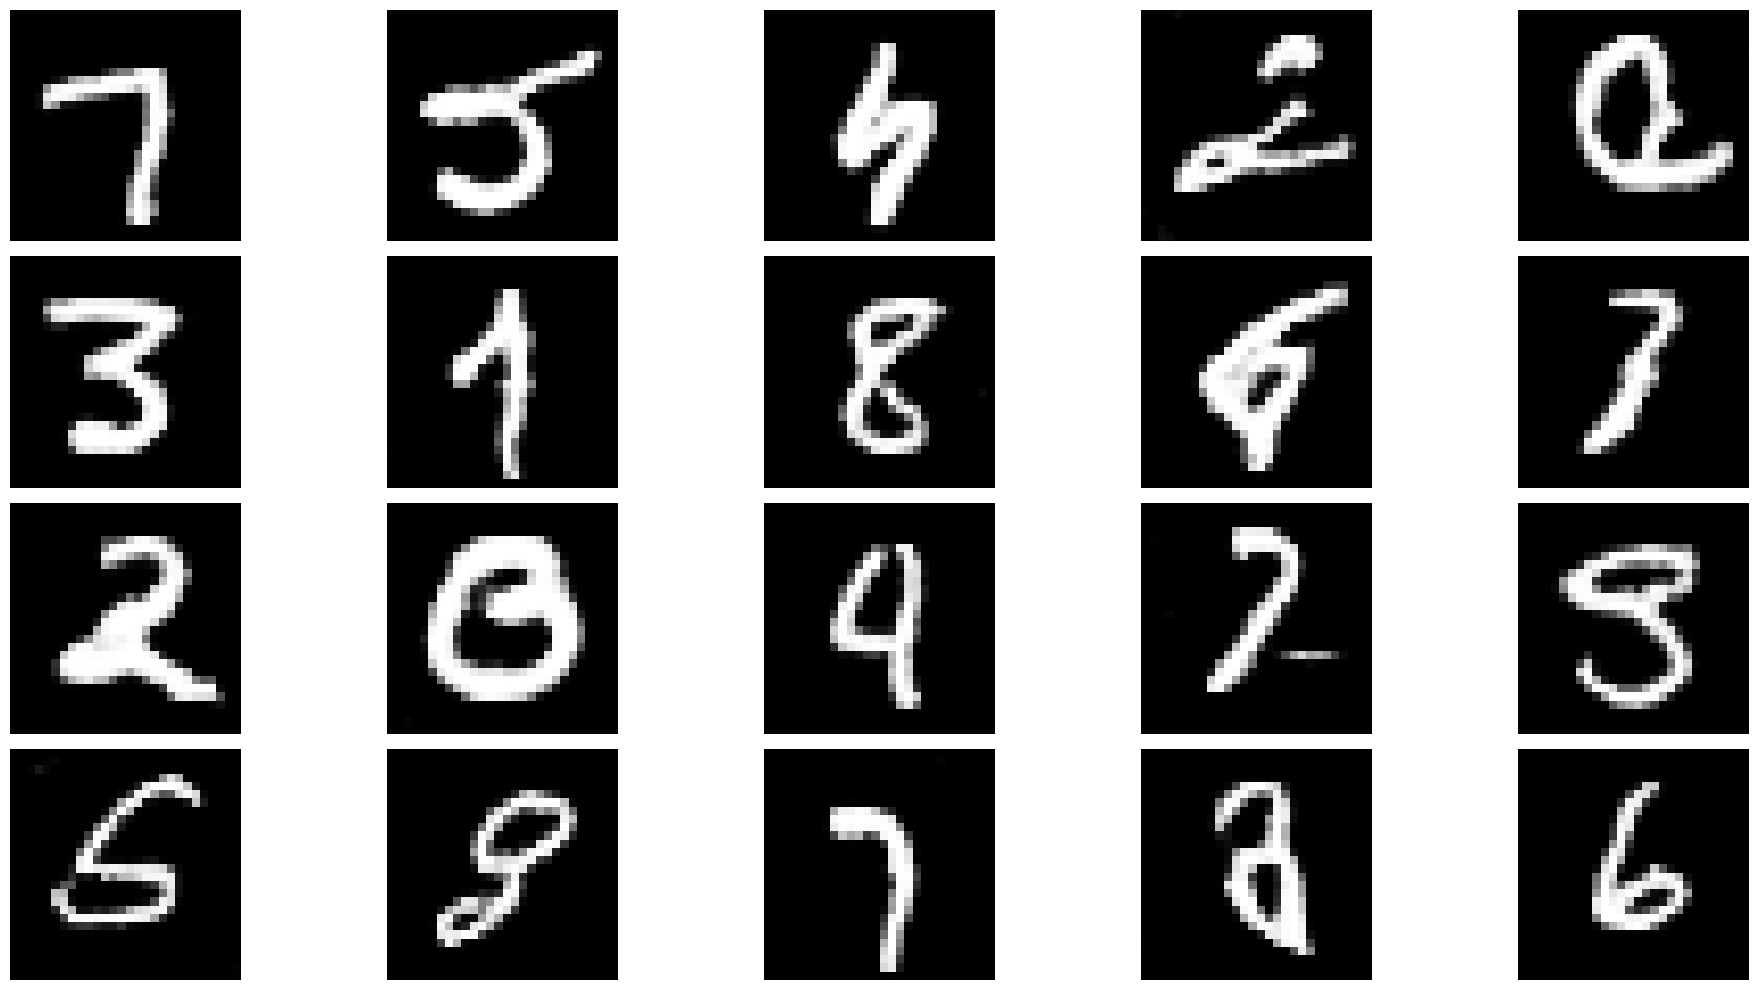

📈 Epoch 40 Summary:
   Train D Loss: 0.7190, Val D Loss: 1.3152
   Train G Loss: 1.9276, Val G Loss: 0.6412

📊 Epoch 41/100
----------------------------------------
Epoch: 41 [0/60000 (0%)]	D_loss: 0.876380	G_loss: 3.048384
Epoch: 41 [6400/60000 (11%)]	D_loss: 0.728358	G_loss: 0.796956
Epoch: 41 [12800/60000 (21%)]	D_loss: 0.623820	G_loss: 1.793716
Epoch: 41 [19200/60000 (32%)]	D_loss: 0.585421	G_loss: 2.699852
Epoch: 41 [25600/60000 (43%)]	D_loss: 0.638155	G_loss: 1.997975
Epoch: 41 [32000/60000 (53%)]	D_loss: 0.696965	G_loss: 0.904723
Epoch: 41 [38400/60000 (64%)]	D_loss: 0.768062	G_loss: 1.339826
Epoch: 41 [44800/60000 (75%)]	D_loss: 1.614571	G_loss: 2.958266
Epoch: 41 [51200/60000 (85%)]	D_loss: 0.612541	G_loss: 2.180831
Epoch: 41 [57600/60000 (96%)]	D_loss: 0.814366	G_loss: 2.427722
====> Epoch: 41 Train D_loss: 0.7143, Train G_loss: 1.9348
====> Epoch: 41 Val D_loss: 1.0362, Val G_loss: 1.3632
📈 Epoch 41 Summary:
   Train D Loss: 0.7143, Val D Loss: 1.0362
   Train G Loss: 1.9348

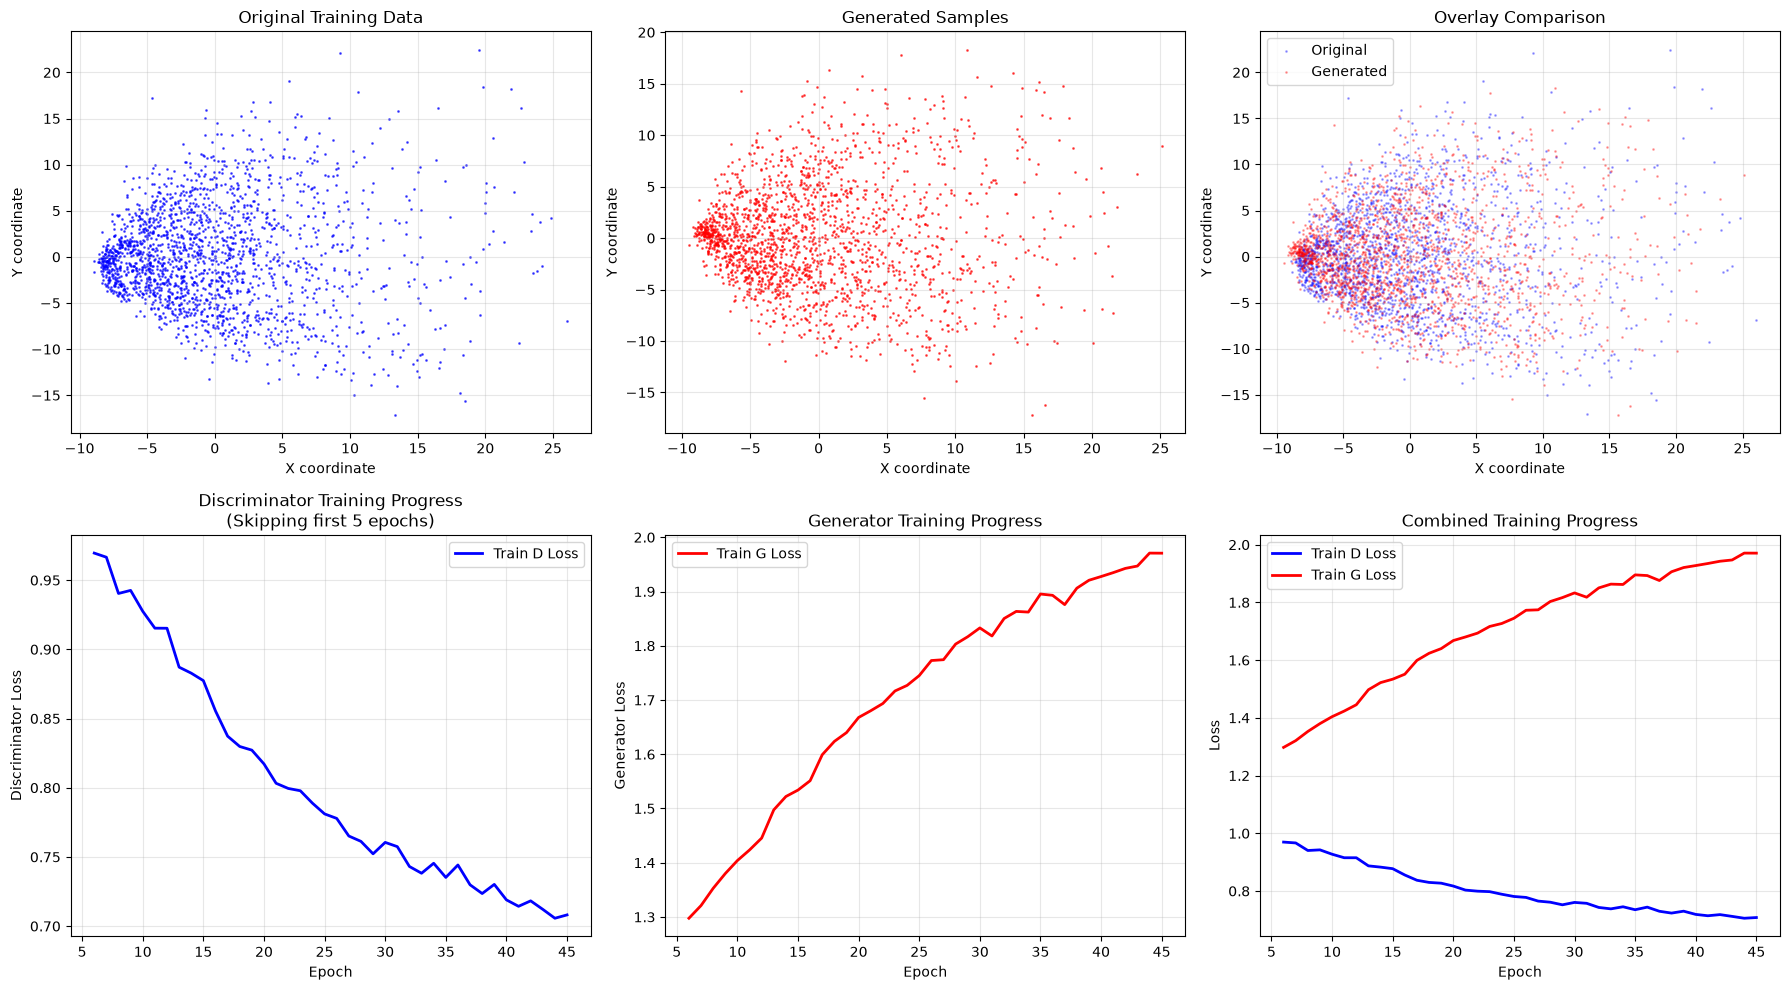

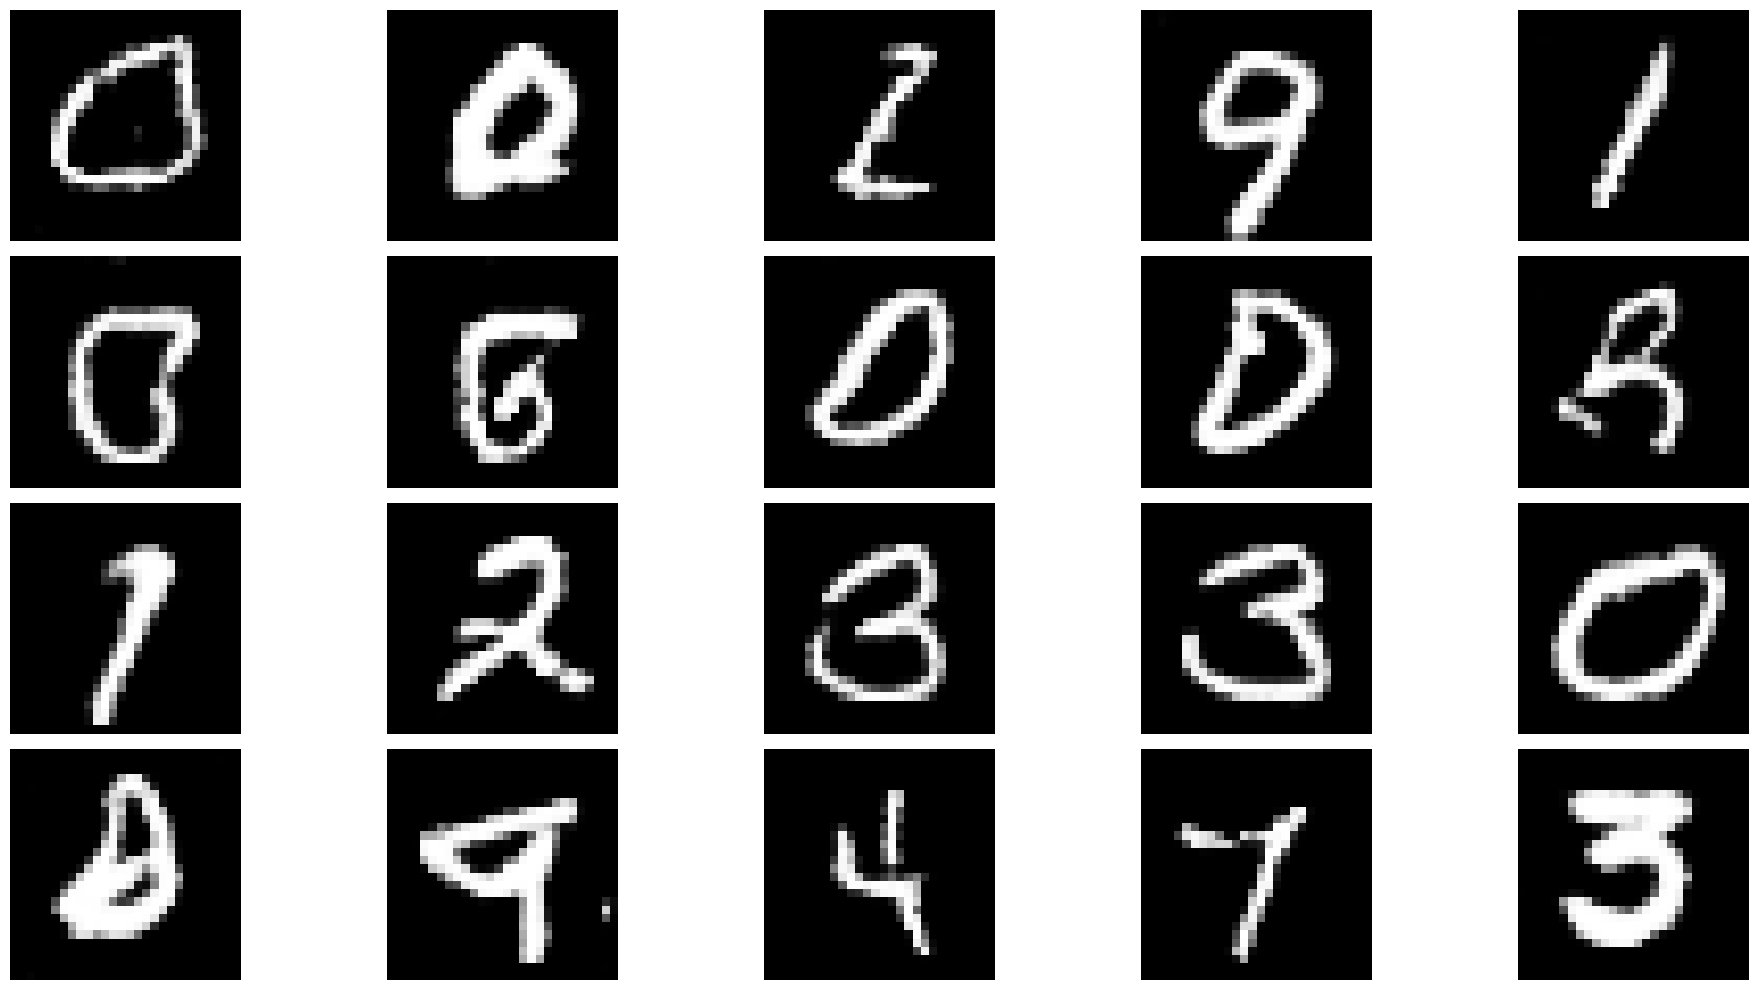

📈 Epoch 45 Summary:
   Train D Loss: 0.7081, Val D Loss: 1.0245
   Train G Loss: 1.9707, Val G Loss: 1.1628

📊 Epoch 46/100
----------------------------------------
Epoch: 46 [0/60000 (0%)]	D_loss: 0.612848	G_loss: 2.277682
Epoch: 46 [6400/60000 (11%)]	D_loss: 0.610754	G_loss: 2.052690
Epoch: 46 [12800/60000 (21%)]	D_loss: 1.026652	G_loss: 3.753592
Epoch: 46 [19200/60000 (32%)]	D_loss: 0.691911	G_loss: 1.579870
Epoch: 46 [25600/60000 (43%)]	D_loss: 0.536734	G_loss: 2.447443
Epoch: 46 [32000/60000 (53%)]	D_loss: 0.621979	G_loss: 2.782955
Epoch: 46 [38400/60000 (64%)]	D_loss: 0.641403	G_loss: 2.402121
Epoch: 46 [44800/60000 (75%)]	D_loss: 0.633058	G_loss: 1.895763
Epoch: 46 [51200/60000 (85%)]	D_loss: 0.677556	G_loss: 3.373455
Epoch: 46 [57600/60000 (96%)]	D_loss: 0.593524	G_loss: 1.478642
====> Epoch: 46 Train D_loss: 0.6940, Train G_loss: 1.9913
====> Epoch: 46 Val D_loss: 1.2117, Val G_loss: 2.0907
📈 Epoch 46 Summary:
   Train D Loss: 0.6940, Val D Loss: 1.2117
   Train G Loss: 1.9913

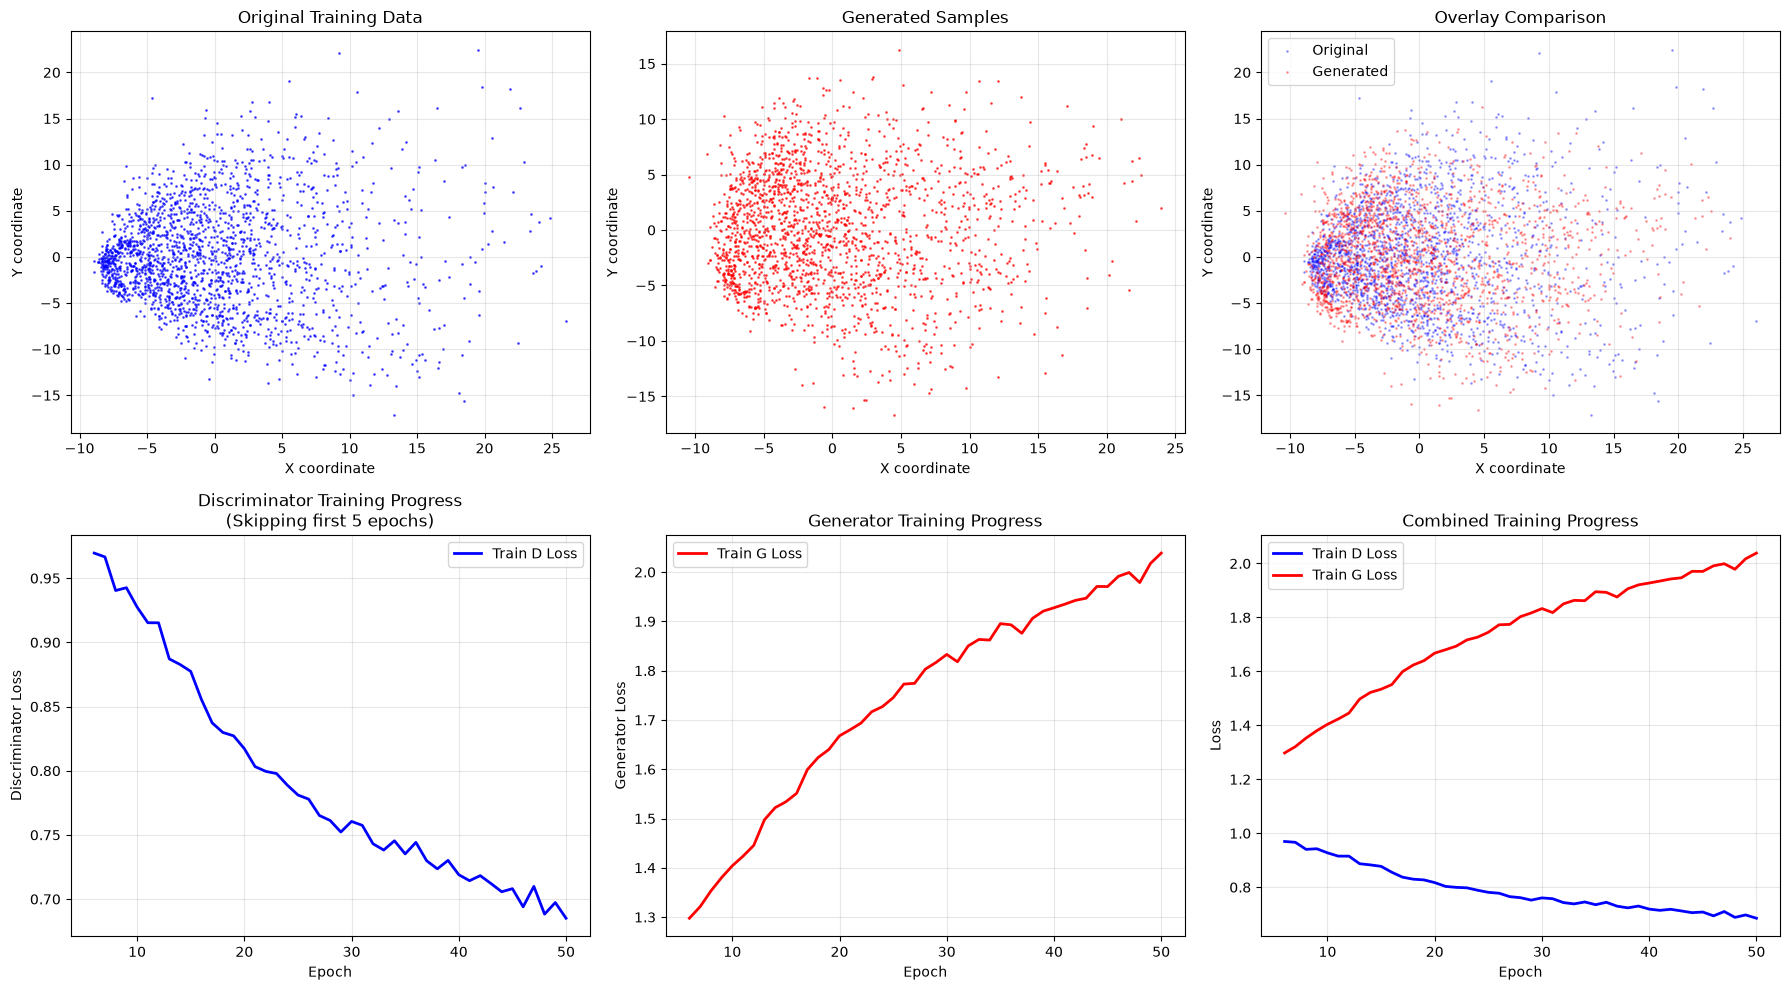

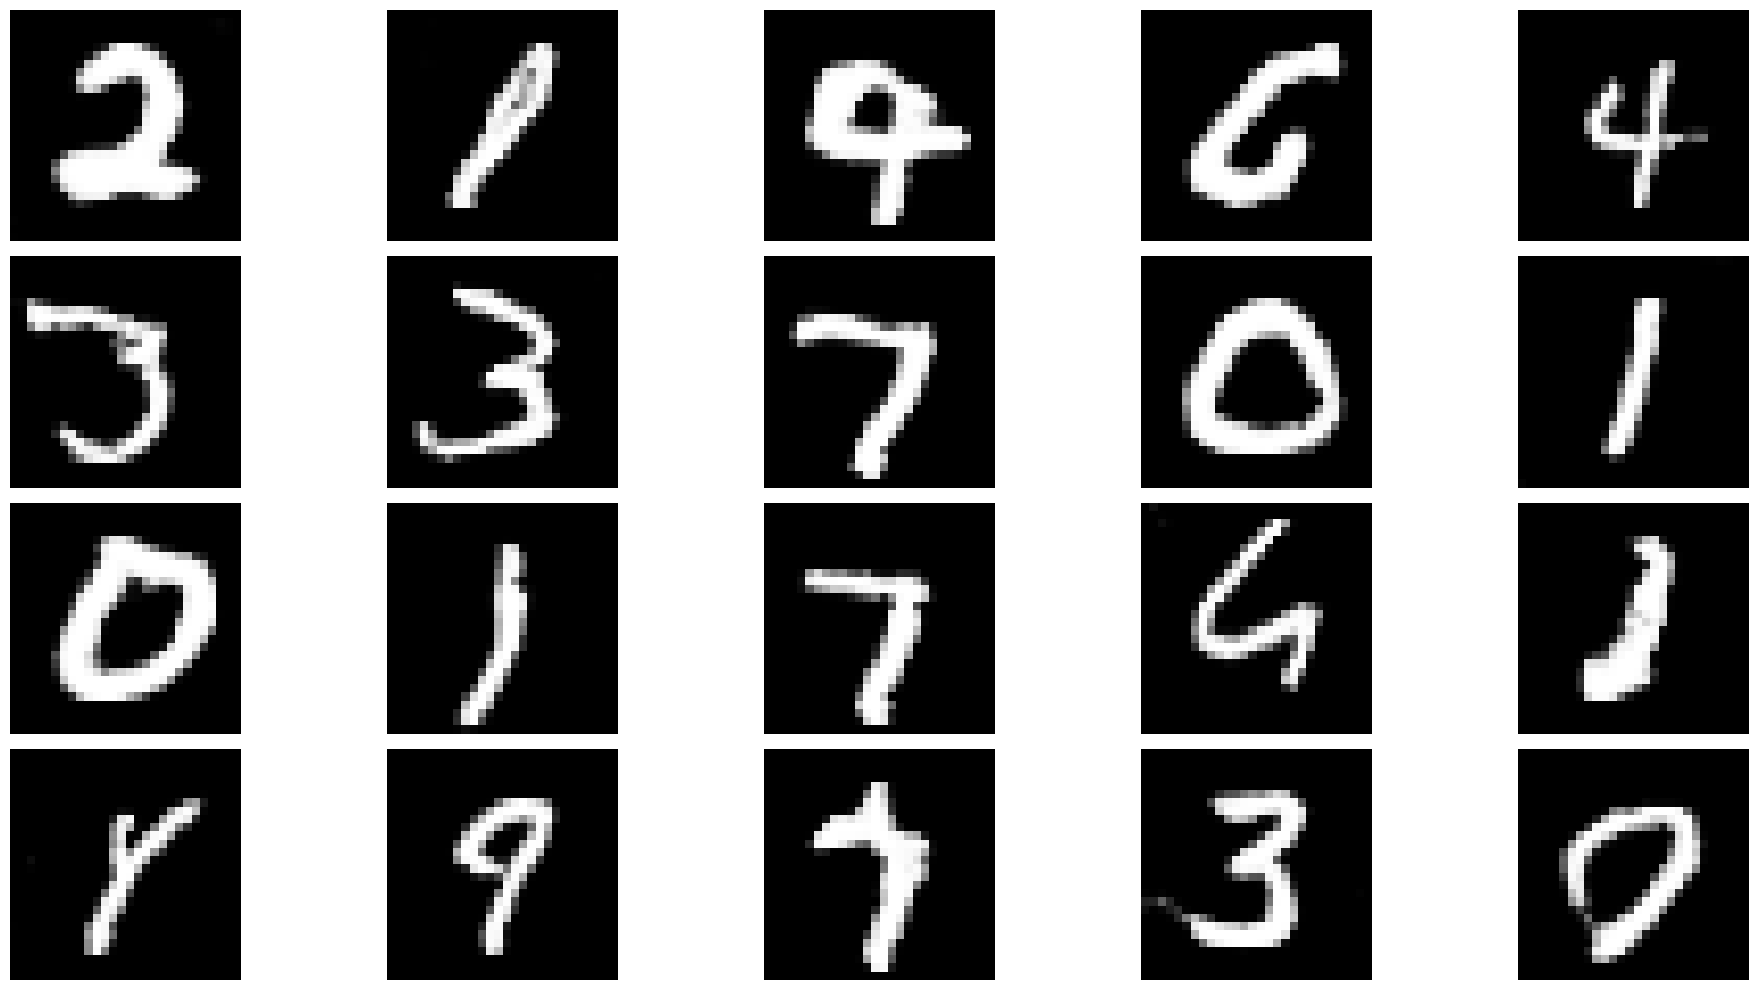

📈 Epoch 50 Summary:
   Train D Loss: 0.6851, Val D Loss: 1.4041
   Train G Loss: 2.0385, Val G Loss: 0.5780

📊 Epoch 51/100
----------------------------------------
Epoch: 51 [0/60000 (0%)]	D_loss: 1.104037	G_loss: 3.701287
Epoch: 51 [6400/60000 (11%)]	D_loss: 0.628057	G_loss: 1.635665
Epoch: 51 [12800/60000 (21%)]	D_loss: 0.535909	G_loss: 2.303869
Epoch: 51 [19200/60000 (32%)]	D_loss: 0.760616	G_loss: 2.554654
Epoch: 51 [25600/60000 (43%)]	D_loss: 0.669682	G_loss: 1.342829
Epoch: 51 [32000/60000 (53%)]	D_loss: 0.833393	G_loss: 2.086190
Epoch: 51 [38400/60000 (64%)]	D_loss: 0.598870	G_loss: 1.787017
Epoch: 51 [44800/60000 (75%)]	D_loss: 0.708039	G_loss: 1.139046
Epoch: 51 [51200/60000 (85%)]	D_loss: 0.568589	G_loss: 1.537596
Epoch: 51 [57600/60000 (96%)]	D_loss: 0.628585	G_loss: 2.171250
====> Epoch: 51 Train D_loss: 0.6982, Train G_loss: 2.0276
====> Epoch: 51 Val D_loss: 1.3617, Val G_loss: 2.5467
📈 Epoch 51 Summary:
   Train D Loss: 0.6982, Val D Loss: 1.3617
   Train G Loss: 2.0276

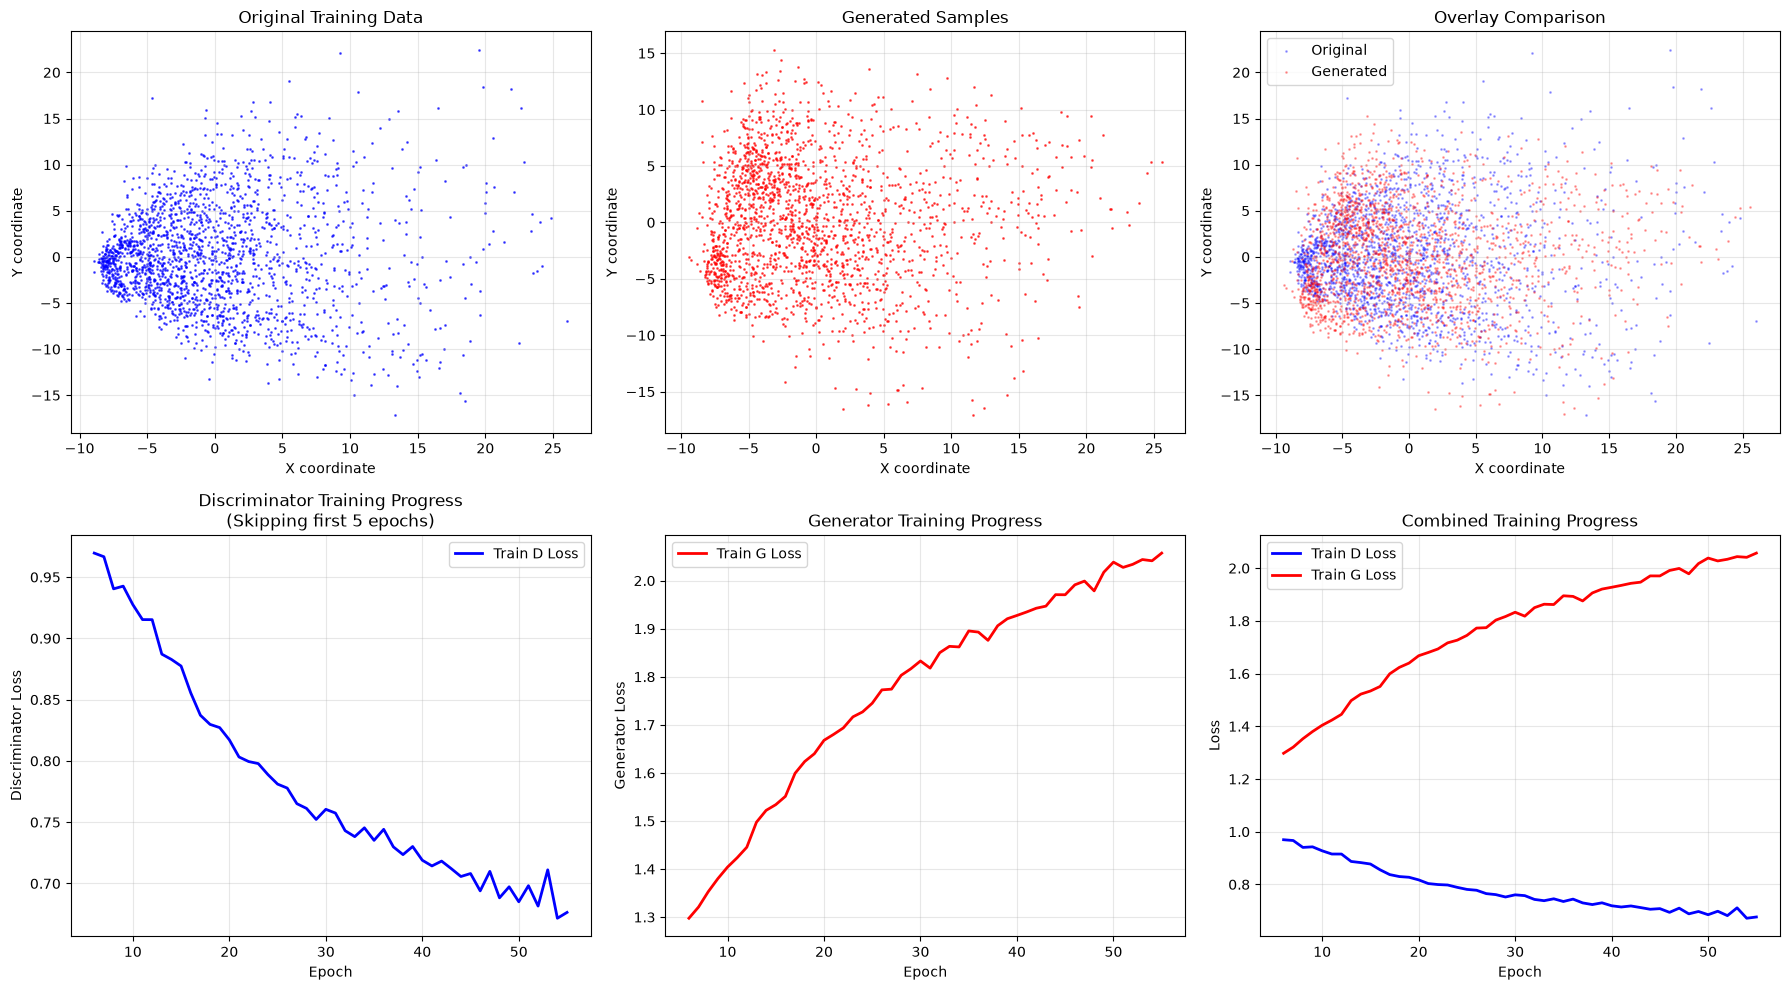

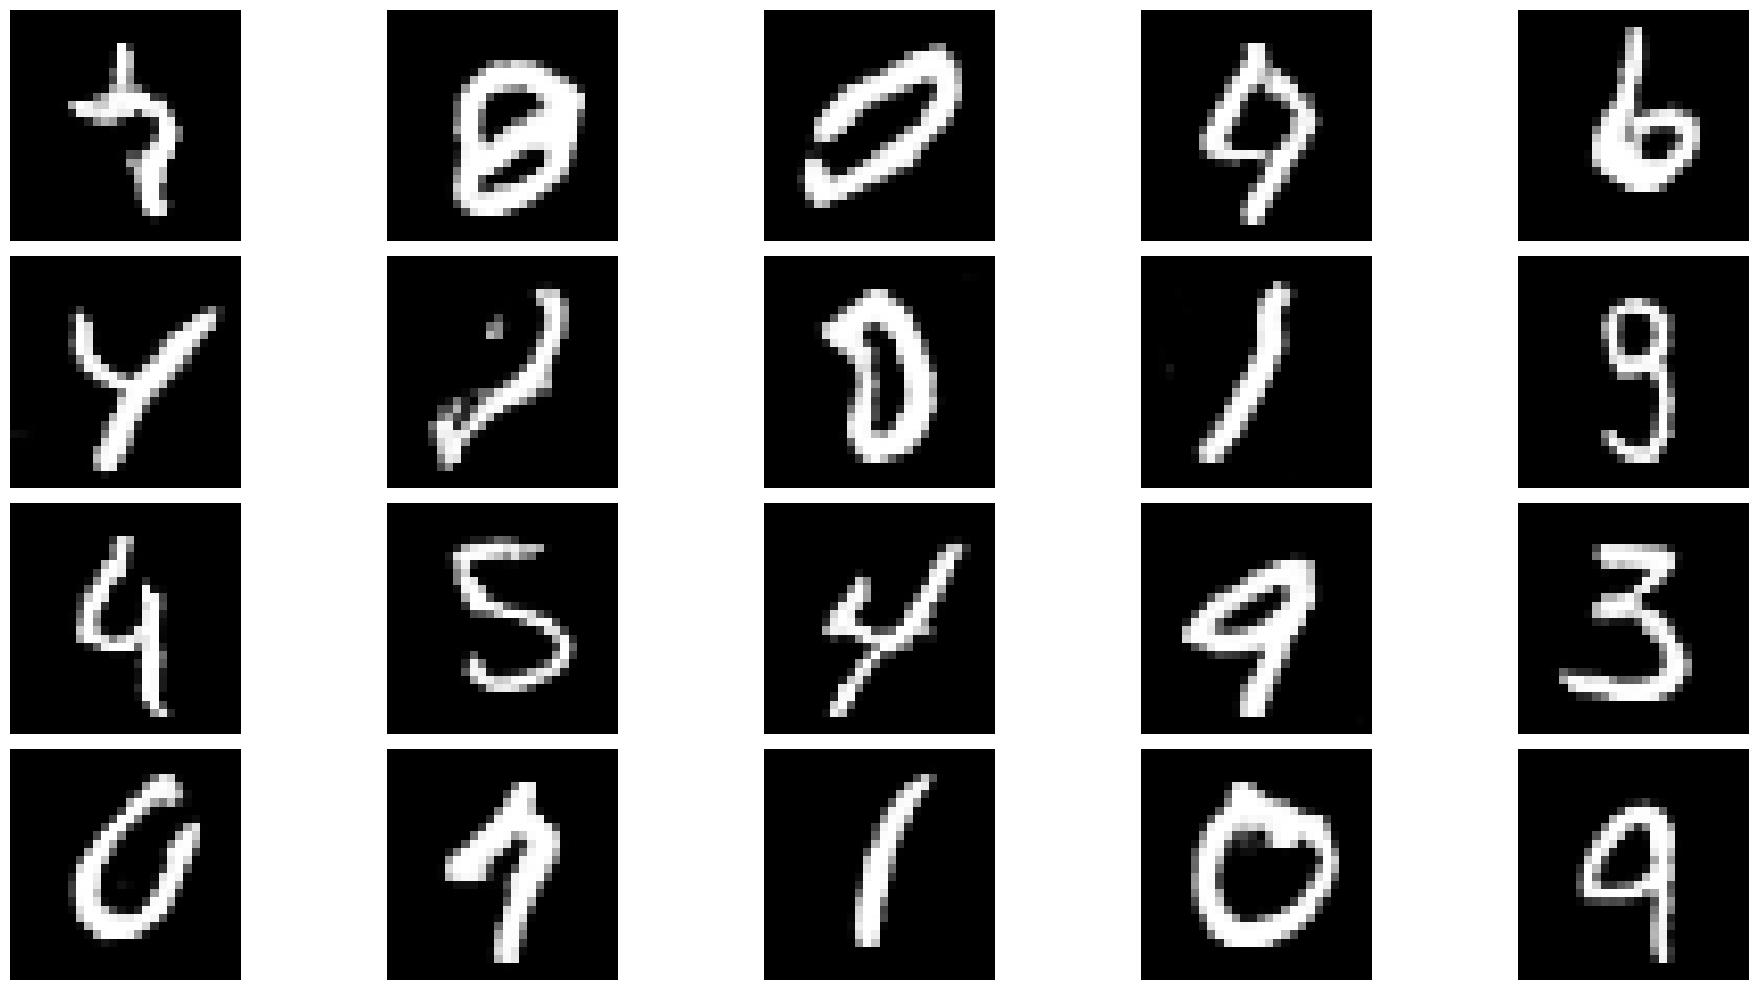

📈 Epoch 55 Summary:
   Train D Loss: 0.6764, Val D Loss: 1.0965
   Train G Loss: 2.0573, Val G Loss: 1.1506

📊 Epoch 56/100
----------------------------------------
Epoch: 56 [0/60000 (0%)]	D_loss: 0.799072	G_loss: 3.297762
Epoch: 56 [6400/60000 (11%)]	D_loss: 0.844691	G_loss: 3.898928
Epoch: 56 [12800/60000 (21%)]	D_loss: 0.714101	G_loss: 1.301746
Epoch: 56 [19200/60000 (32%)]	D_loss: 0.579114	G_loss: 1.686505
Epoch: 56 [25600/60000 (43%)]	D_loss: 0.589017	G_loss: 2.288910
Epoch: 56 [32000/60000 (53%)]	D_loss: 0.644300	G_loss: 1.885056
Epoch: 56 [38400/60000 (64%)]	D_loss: 0.657844	G_loss: 2.308855
Epoch: 56 [44800/60000 (75%)]	D_loss: 0.811689	G_loss: 1.993292
Epoch: 56 [51200/60000 (85%)]	D_loss: 0.559853	G_loss: 2.266913
Epoch: 56 [57600/60000 (96%)]	D_loss: 0.877913	G_loss: 1.726928
====> Epoch: 56 Train D_loss: 0.6872, Train G_loss: 2.0705
====> Epoch: 56 Val D_loss: 0.9943, Val G_loss: 1.5778
📈 Epoch 56 Summary:
   Train D Loss: 0.6872, Val D Loss: 0.9943
   Train G Loss: 2.0705

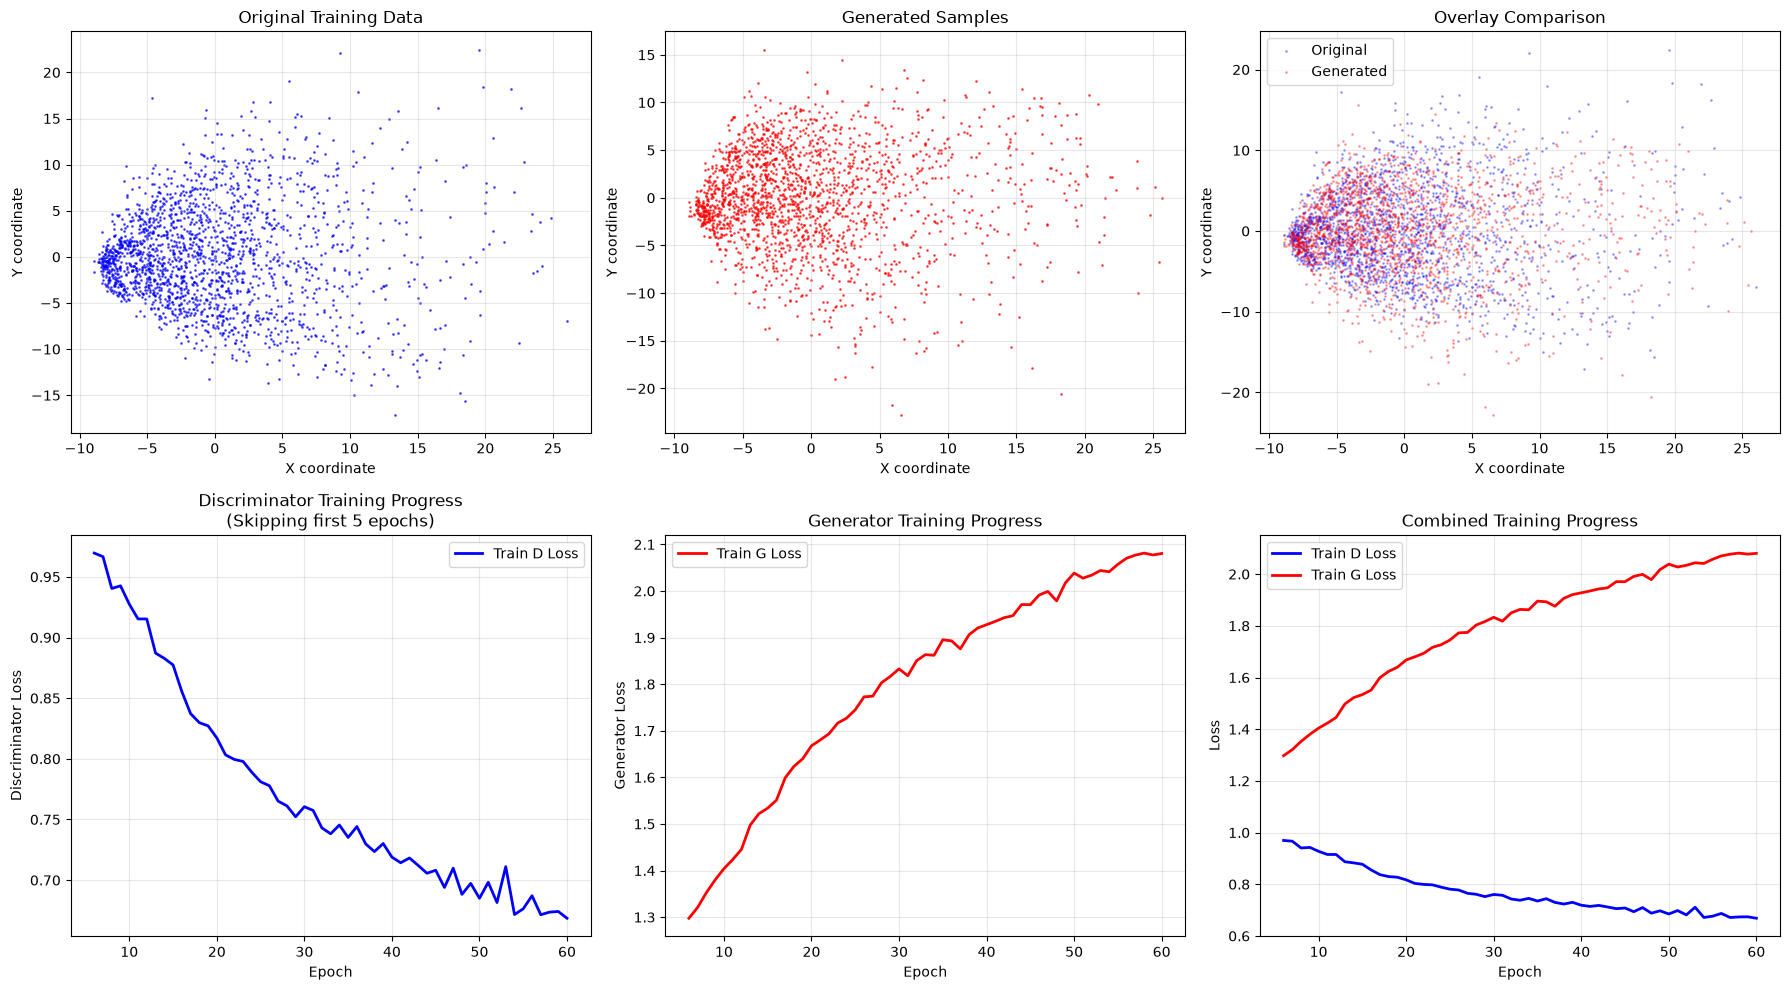

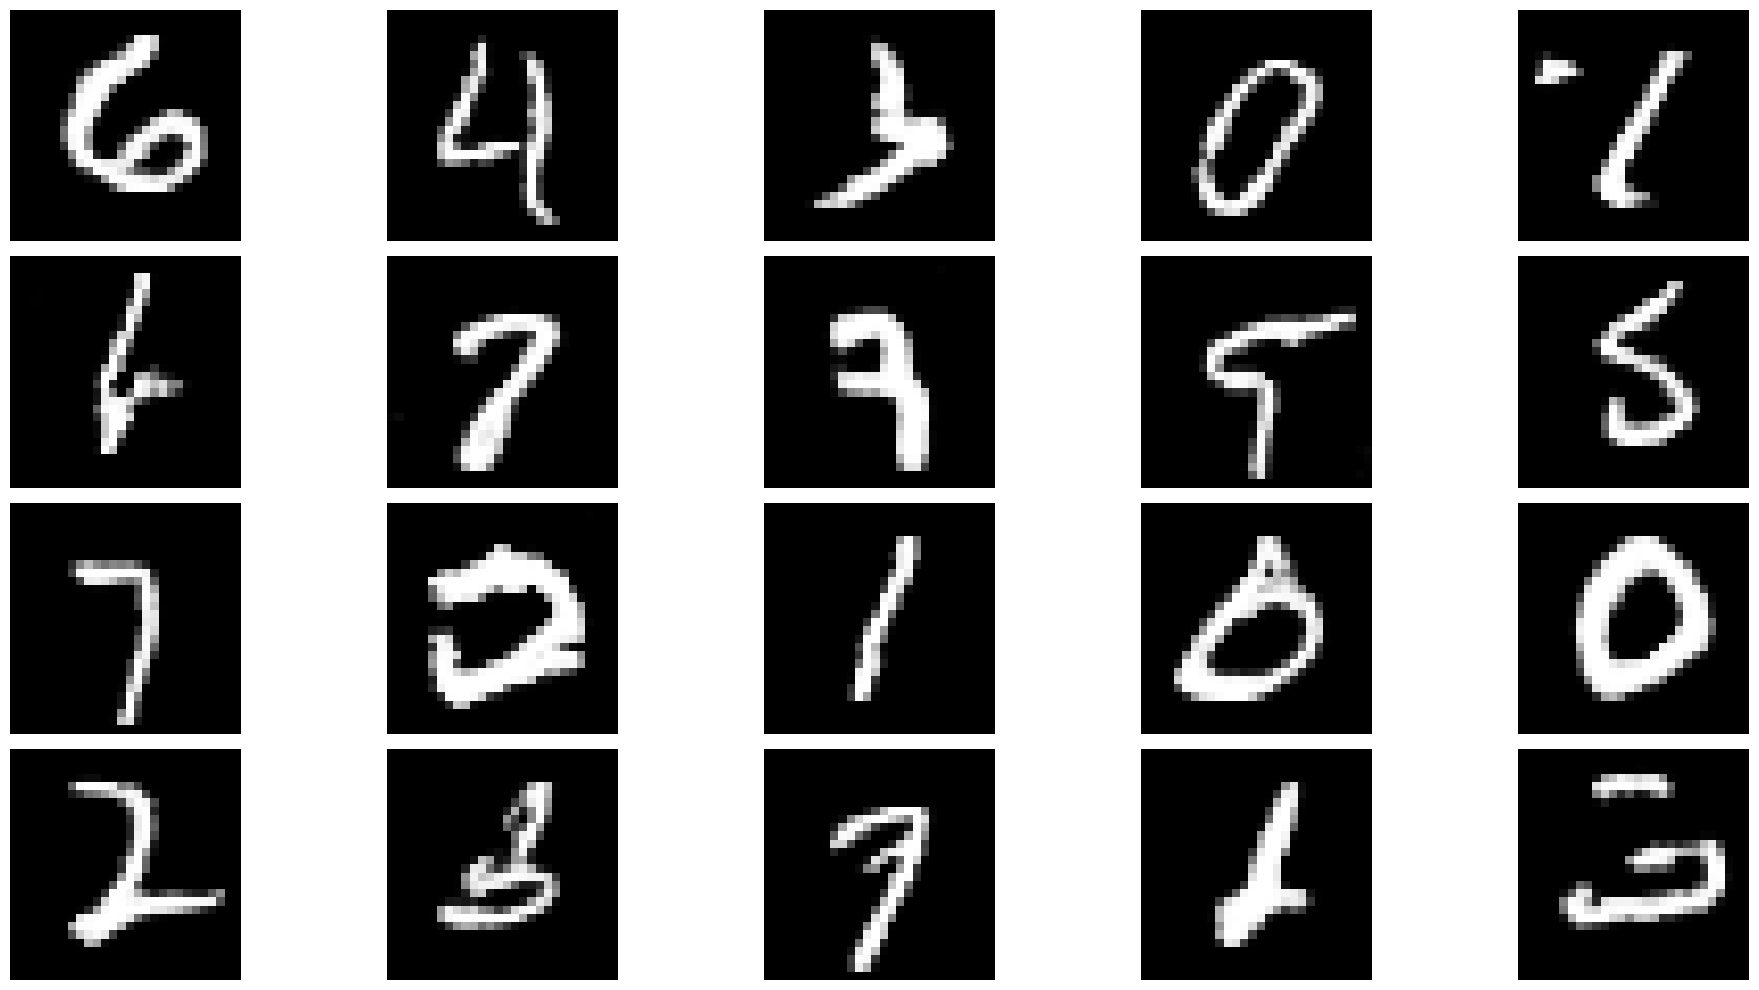

📈 Epoch 60 Summary:
   Train D Loss: 0.6686, Val D Loss: 1.2782
   Train G Loss: 2.0804, Val G Loss: 2.4473

📊 Epoch 61/100
----------------------------------------
Epoch: 61 [0/60000 (0%)]	D_loss: 0.489299	G_loss: 2.336176
Epoch: 61 [6400/60000 (11%)]	D_loss: 0.534924	G_loss: 2.689992
Epoch: 61 [12800/60000 (21%)]	D_loss: 0.571400	G_loss: 1.468071
Epoch: 61 [19200/60000 (32%)]	D_loss: 0.530852	G_loss: 2.090495
Epoch: 61 [25600/60000 (43%)]	D_loss: 0.695153	G_loss: 1.889701
Epoch: 61 [32000/60000 (53%)]	D_loss: 0.641594	G_loss: 2.169550
Epoch: 61 [38400/60000 (64%)]	D_loss: 0.889484	G_loss: 1.374072
Epoch: 61 [44800/60000 (75%)]	D_loss: 0.524798	G_loss: 3.116727
Epoch: 61 [51200/60000 (85%)]	D_loss: 0.582016	G_loss: 1.856987
Epoch: 61 [57600/60000 (96%)]	D_loss: 0.592326	G_loss: 2.923274
====> Epoch: 61 Train D_loss: 0.6608, Train G_loss: 2.0996
====> Epoch: 61 Val D_loss: 1.1104, Val G_loss: 2.0228
📈 Epoch 61 Summary:
   Train D Loss: 0.6608, Val D Loss: 1.1104
   Train G Loss: 2.0996

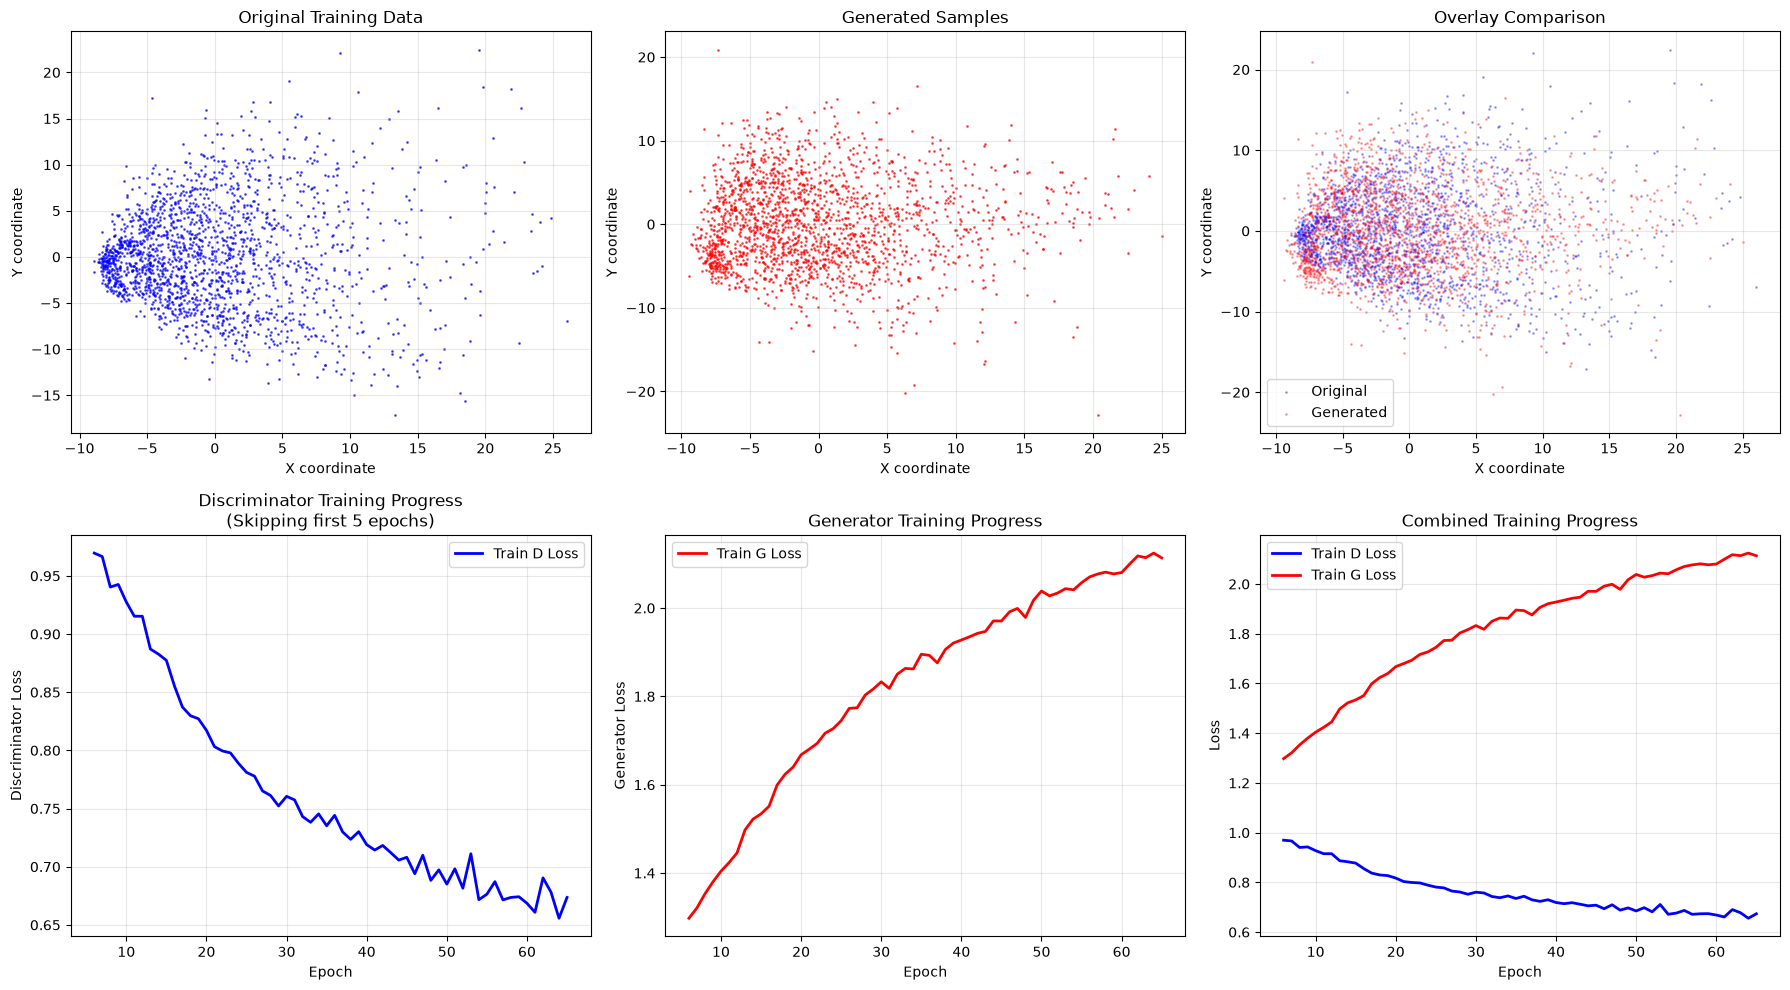

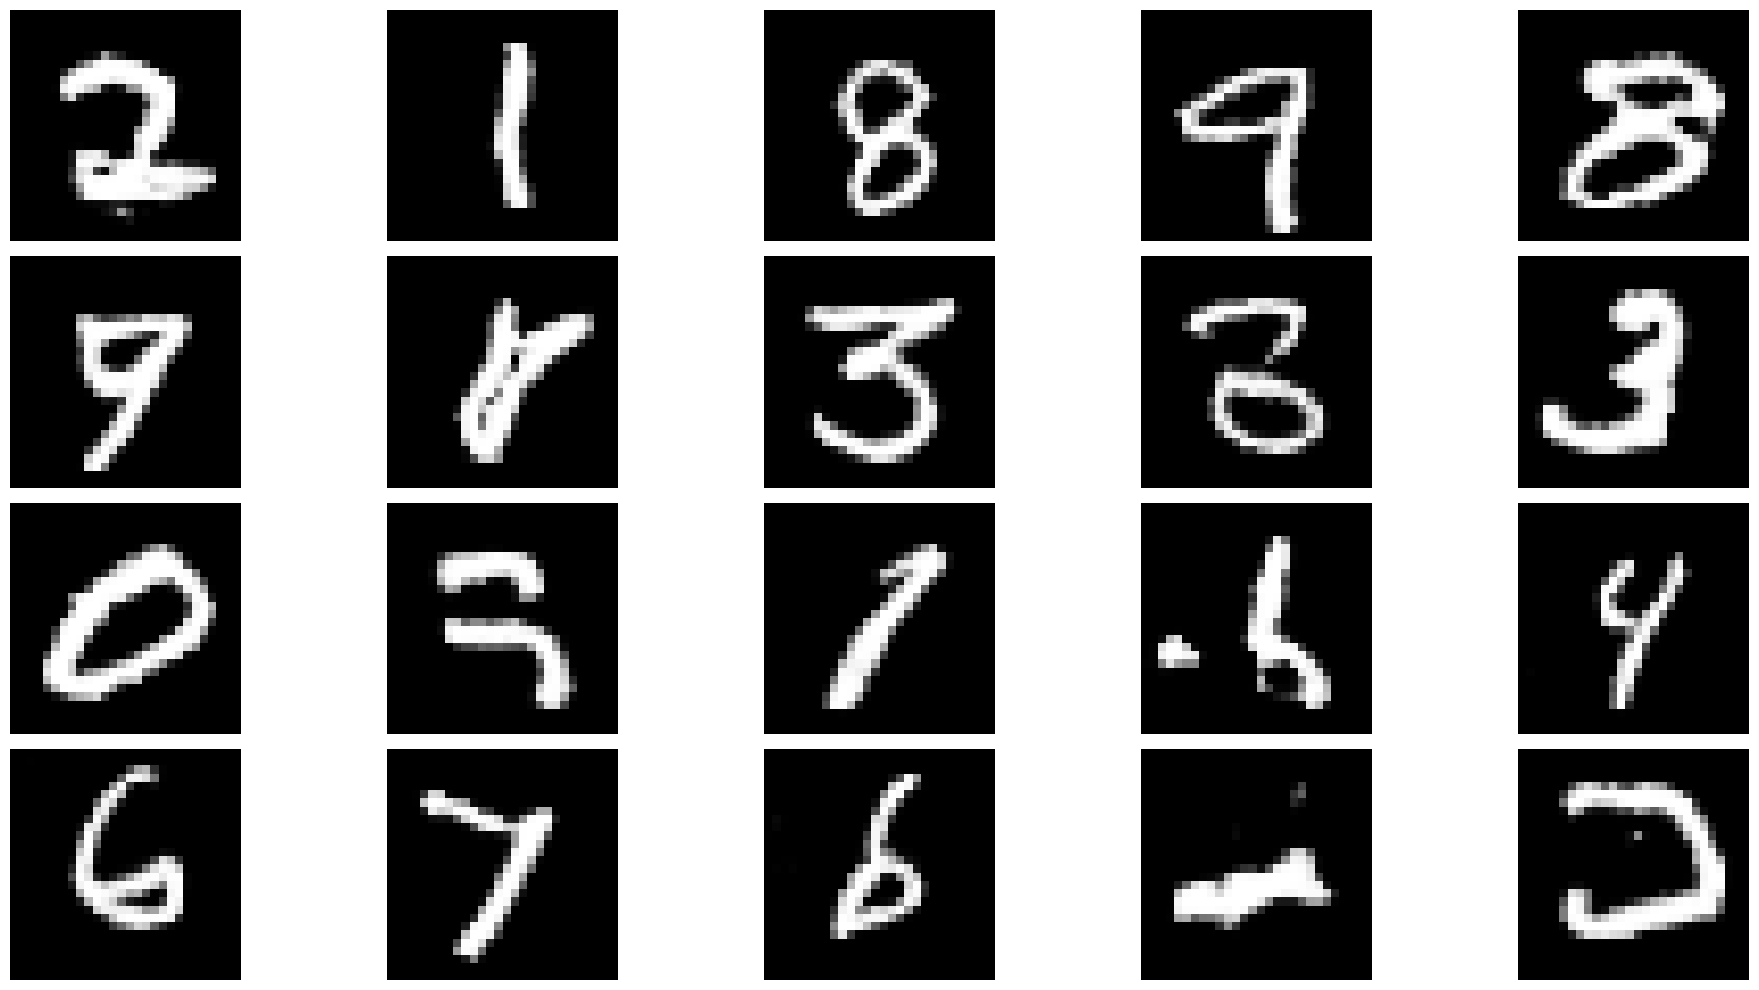

📈 Epoch 65 Summary:
   Train D Loss: 0.6736, Val D Loss: 1.0454
   Train G Loss: 2.1136, Val G Loss: 1.2772

📊 Epoch 66/100
----------------------------------------
Epoch: 66 [0/60000 (0%)]	D_loss: 0.656219	G_loss: 2.343033
Epoch: 66 [6400/60000 (11%)]	D_loss: 0.650605	G_loss: 1.961344
Epoch: 66 [12800/60000 (21%)]	D_loss: 0.608470	G_loss: 1.737740
Epoch: 66 [19200/60000 (32%)]	D_loss: 0.560194	G_loss: 2.525511
Epoch: 66 [25600/60000 (43%)]	D_loss: 0.688323	G_loss: 3.283842
Epoch: 66 [32000/60000 (53%)]	D_loss: 0.491422	G_loss: 1.694549
Epoch: 66 [38400/60000 (64%)]	D_loss: 0.543756	G_loss: 2.662663
Epoch: 66 [44800/60000 (75%)]	D_loss: 0.513058	G_loss: 1.463786
Epoch: 66 [51200/60000 (85%)]	D_loss: 0.539367	G_loss: 1.724286
Epoch: 66 [57600/60000 (96%)]	D_loss: 0.847760	G_loss: 1.391142
====> Epoch: 66 Train D_loss: 0.6484, Train G_loss: 2.1339
====> Epoch: 66 Val D_loss: 1.0946, Val G_loss: 1.8397
📈 Epoch 66 Summary:
   Train D Loss: 0.6484, Val D Loss: 1.0946
   Train G Loss: 2.1339

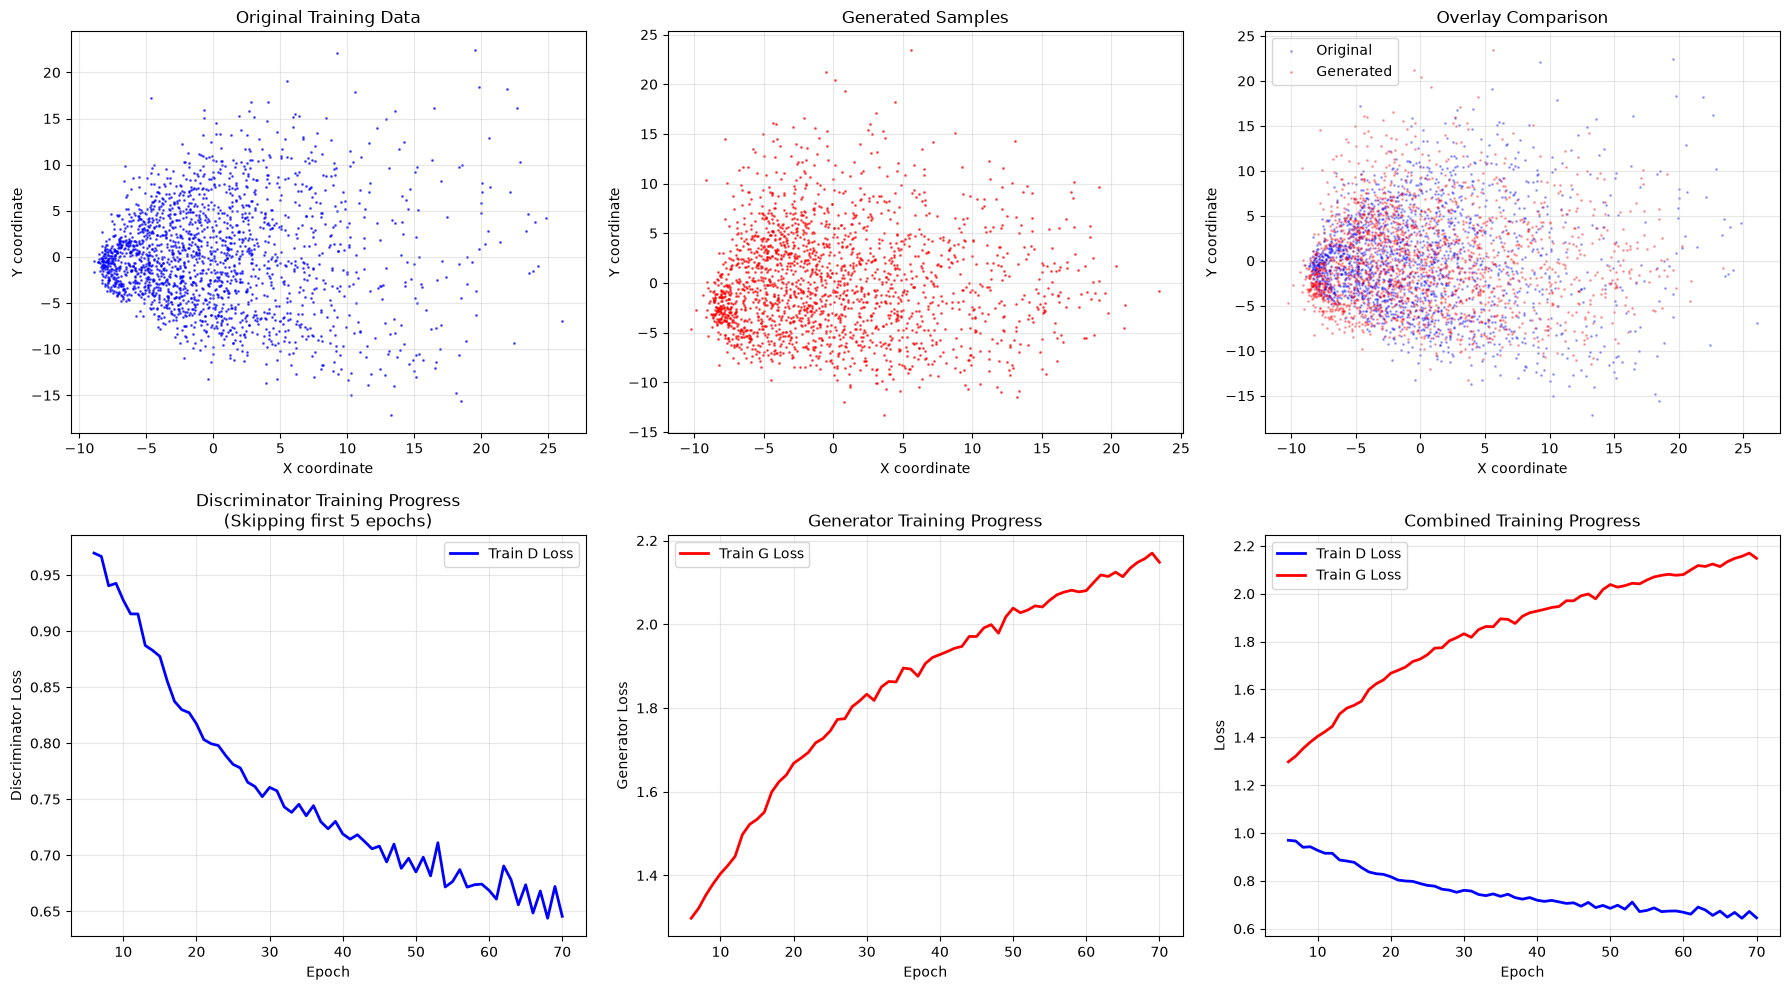

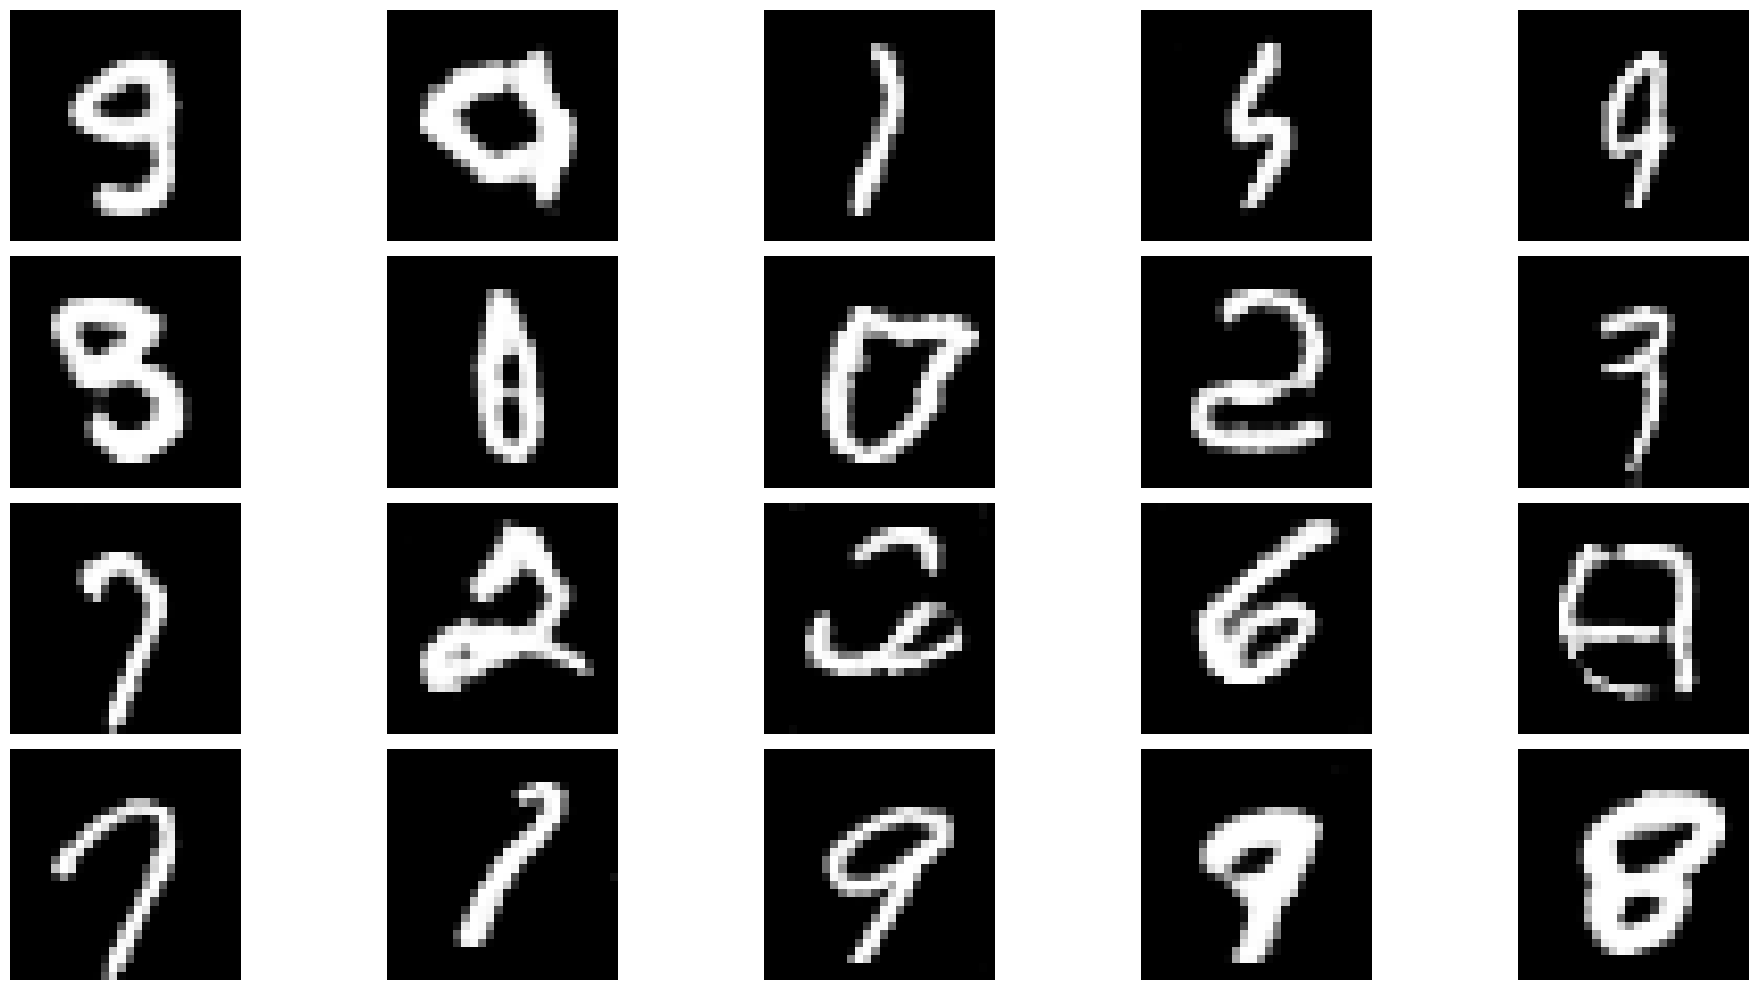

📈 Epoch 70 Summary:
   Train D Loss: 0.6455, Val D Loss: 1.0441
   Train G Loss: 2.1481, Val G Loss: 1.3523

📊 Epoch 71/100
----------------------------------------
Epoch: 71 [0/60000 (0%)]	D_loss: 1.225204	G_loss: 4.532169
Epoch: 71 [6400/60000 (11%)]	D_loss: 0.579631	G_loss: 1.806785
Epoch: 71 [12800/60000 (21%)]	D_loss: 0.583381	G_loss: 2.165114
Epoch: 71 [19200/60000 (32%)]	D_loss: 0.556912	G_loss: 2.405514
Epoch: 71 [25600/60000 (43%)]	D_loss: 0.987690	G_loss: 3.138524
Epoch: 71 [32000/60000 (53%)]	D_loss: 0.635756	G_loss: 1.649465
Epoch: 71 [38400/60000 (64%)]	D_loss: 0.866334	G_loss: 1.456407
Epoch: 71 [44800/60000 (75%)]	D_loss: 0.628675	G_loss: 2.656356
Epoch: 71 [51200/60000 (85%)]	D_loss: 0.620848	G_loss: 1.986763
Epoch: 71 [57600/60000 (96%)]	D_loss: 0.484104	G_loss: 2.433418
====> Epoch: 71 Train D_loss: 0.6559, Train G_loss: 2.1639
====> Epoch: 71 Val D_loss: 1.0488, Val G_loss: 1.5430
📈 Epoch 71 Summary:
   Train D Loss: 0.6559, Val D Loss: 1.0488
   Train G Loss: 2.1639

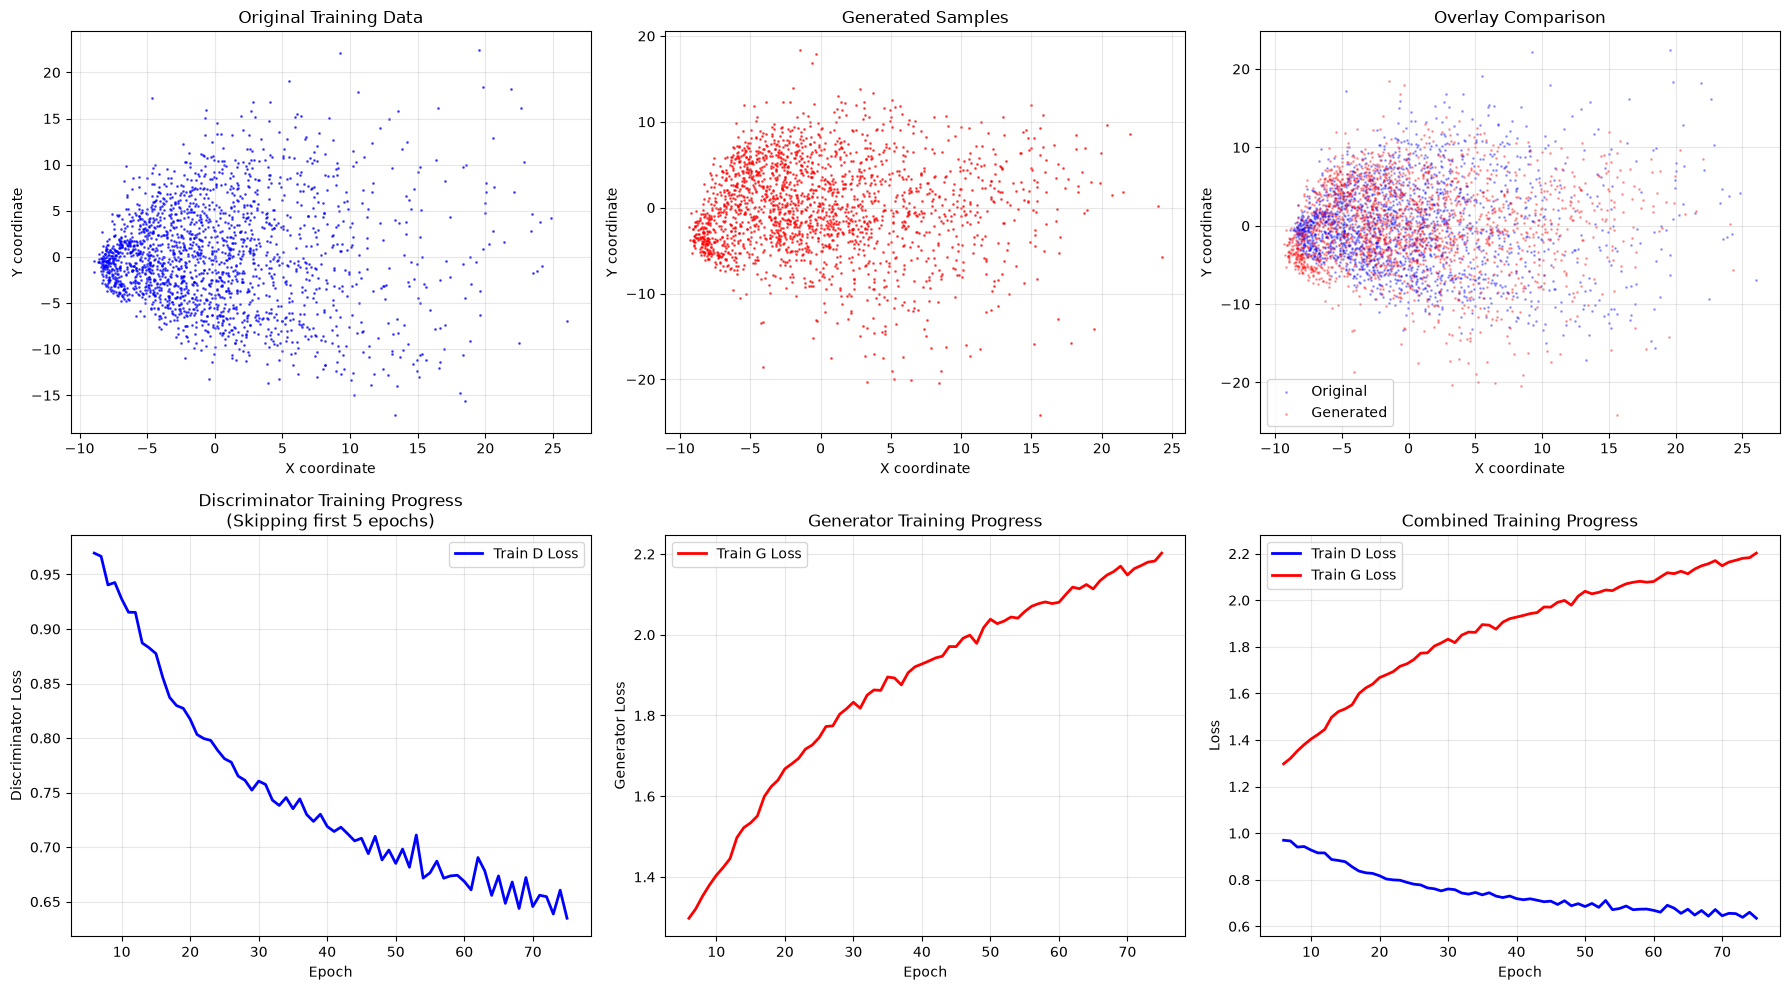

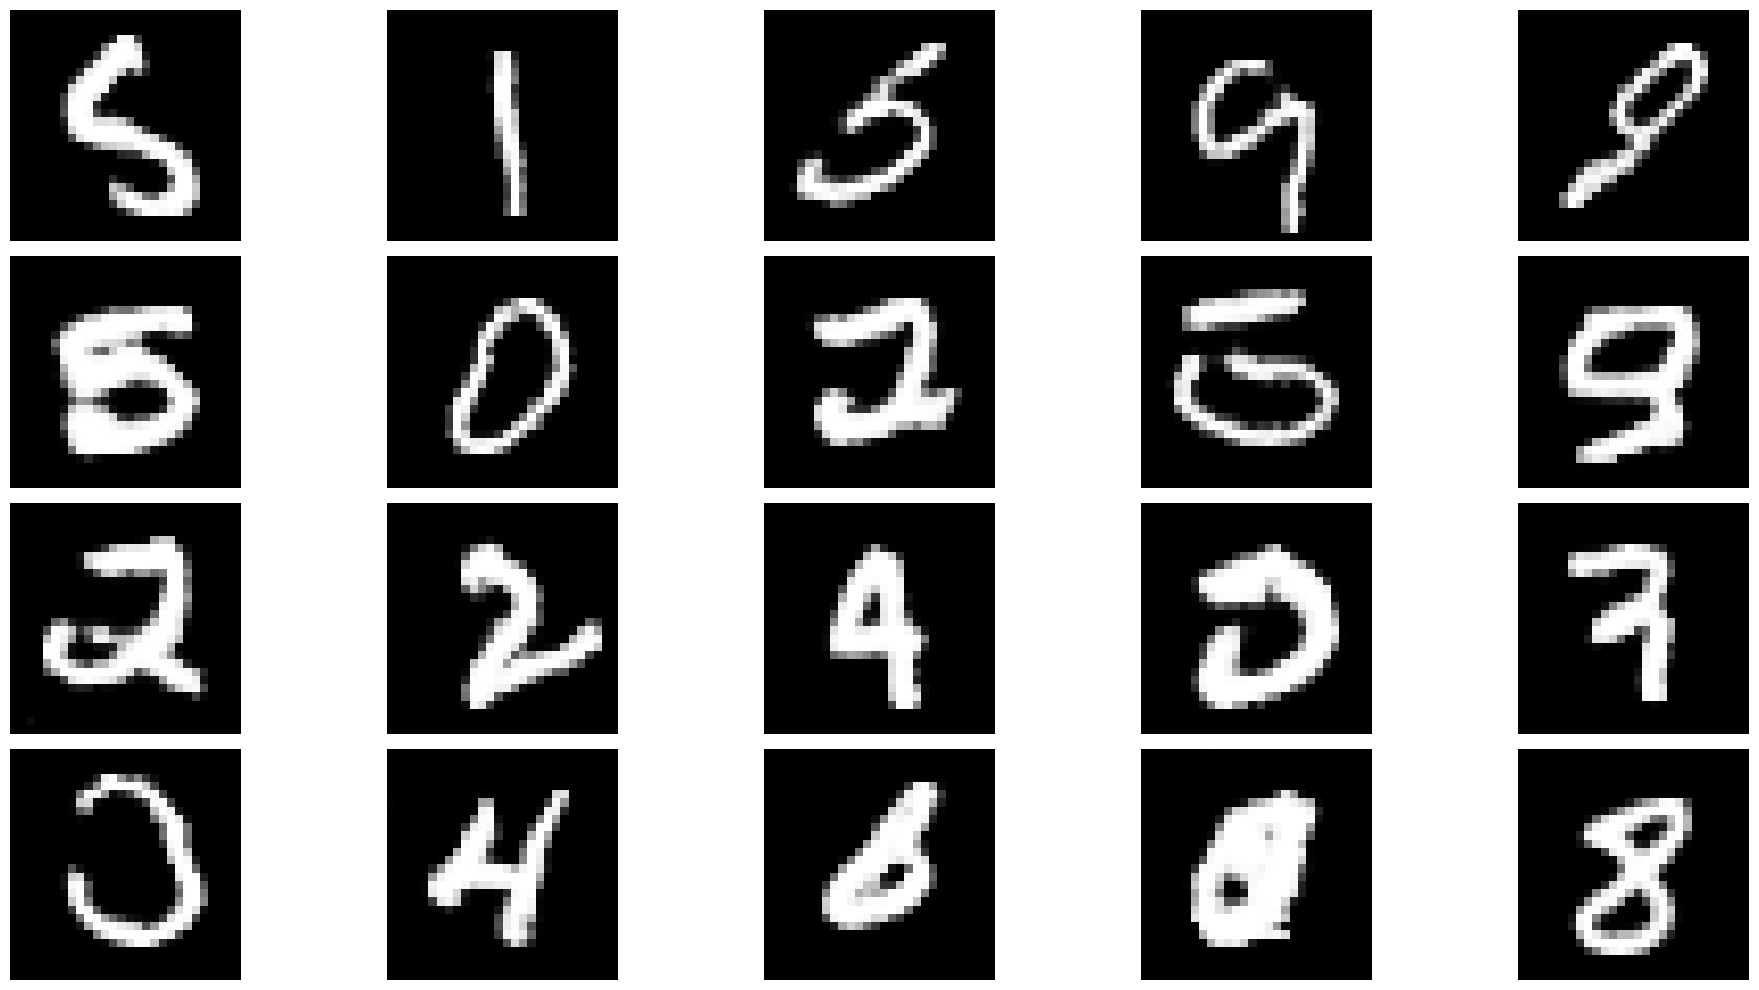

📈 Epoch 75 Summary:
   Train D Loss: 0.6348, Val D Loss: 1.1036
   Train G Loss: 2.2023, Val G Loss: 1.8513

📊 Epoch 76/100
----------------------------------------
Epoch: 76 [0/60000 (0%)]	D_loss: 0.648536	G_loss: 2.750774
Epoch: 76 [6400/60000 (11%)]	D_loss: 0.451731	G_loss: 2.691257
Epoch: 76 [12800/60000 (21%)]	D_loss: 0.510497	G_loss: 2.556316
Epoch: 76 [19200/60000 (32%)]	D_loss: 0.495391	G_loss: 2.369601
Epoch: 76 [25600/60000 (43%)]	D_loss: 0.367506	G_loss: 2.983951
Epoch: 76 [32000/60000 (53%)]	D_loss: 0.517440	G_loss: 2.071856
Epoch: 76 [38400/60000 (64%)]	D_loss: 1.135121	G_loss: 1.353974
Epoch: 76 [44800/60000 (75%)]	D_loss: 0.519603	G_loss: 1.743366
Epoch: 76 [51200/60000 (85%)]	D_loss: 0.591268	G_loss: 2.165792
Epoch: 76 [57600/60000 (96%)]	D_loss: 0.463179	G_loss: 1.841214
====> Epoch: 76 Train D_loss: 0.6441, Train G_loss: 2.1930
====> Epoch: 76 Val D_loss: 1.2067, Val G_loss: 2.3989
📈 Epoch 76 Summary:
   Train D Loss: 0.6441, Val D Loss: 1.2067
   Train G Loss: 2.1930

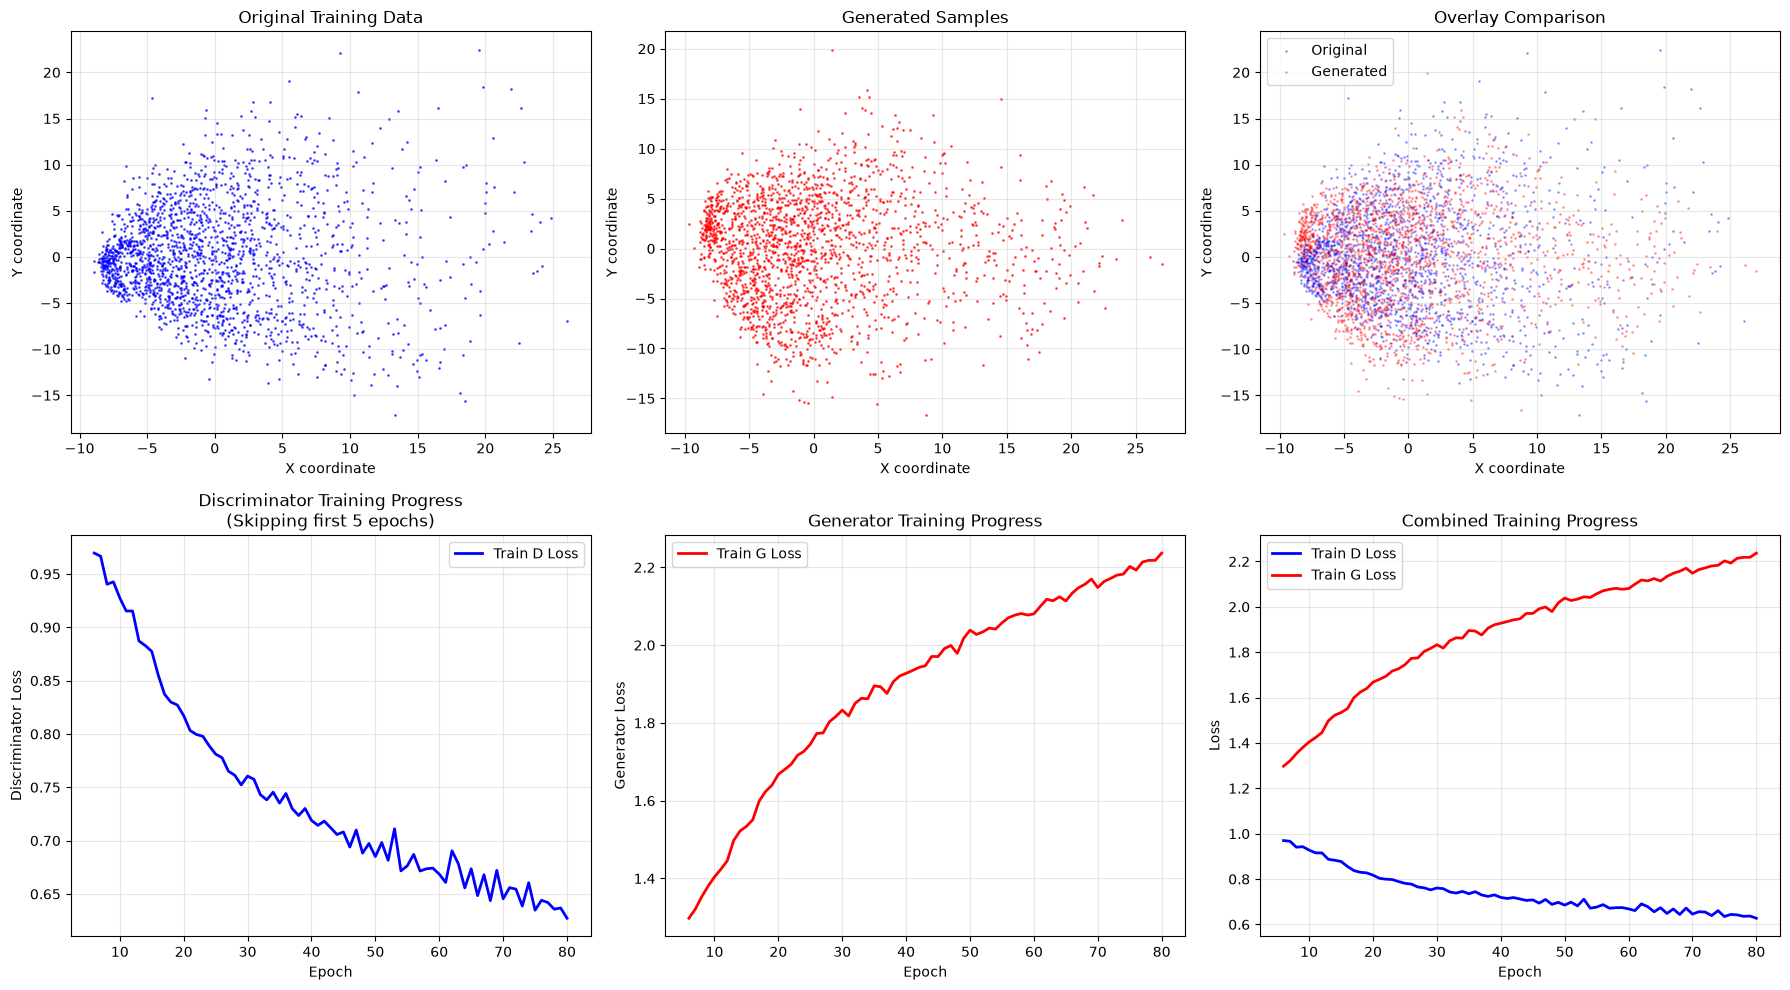

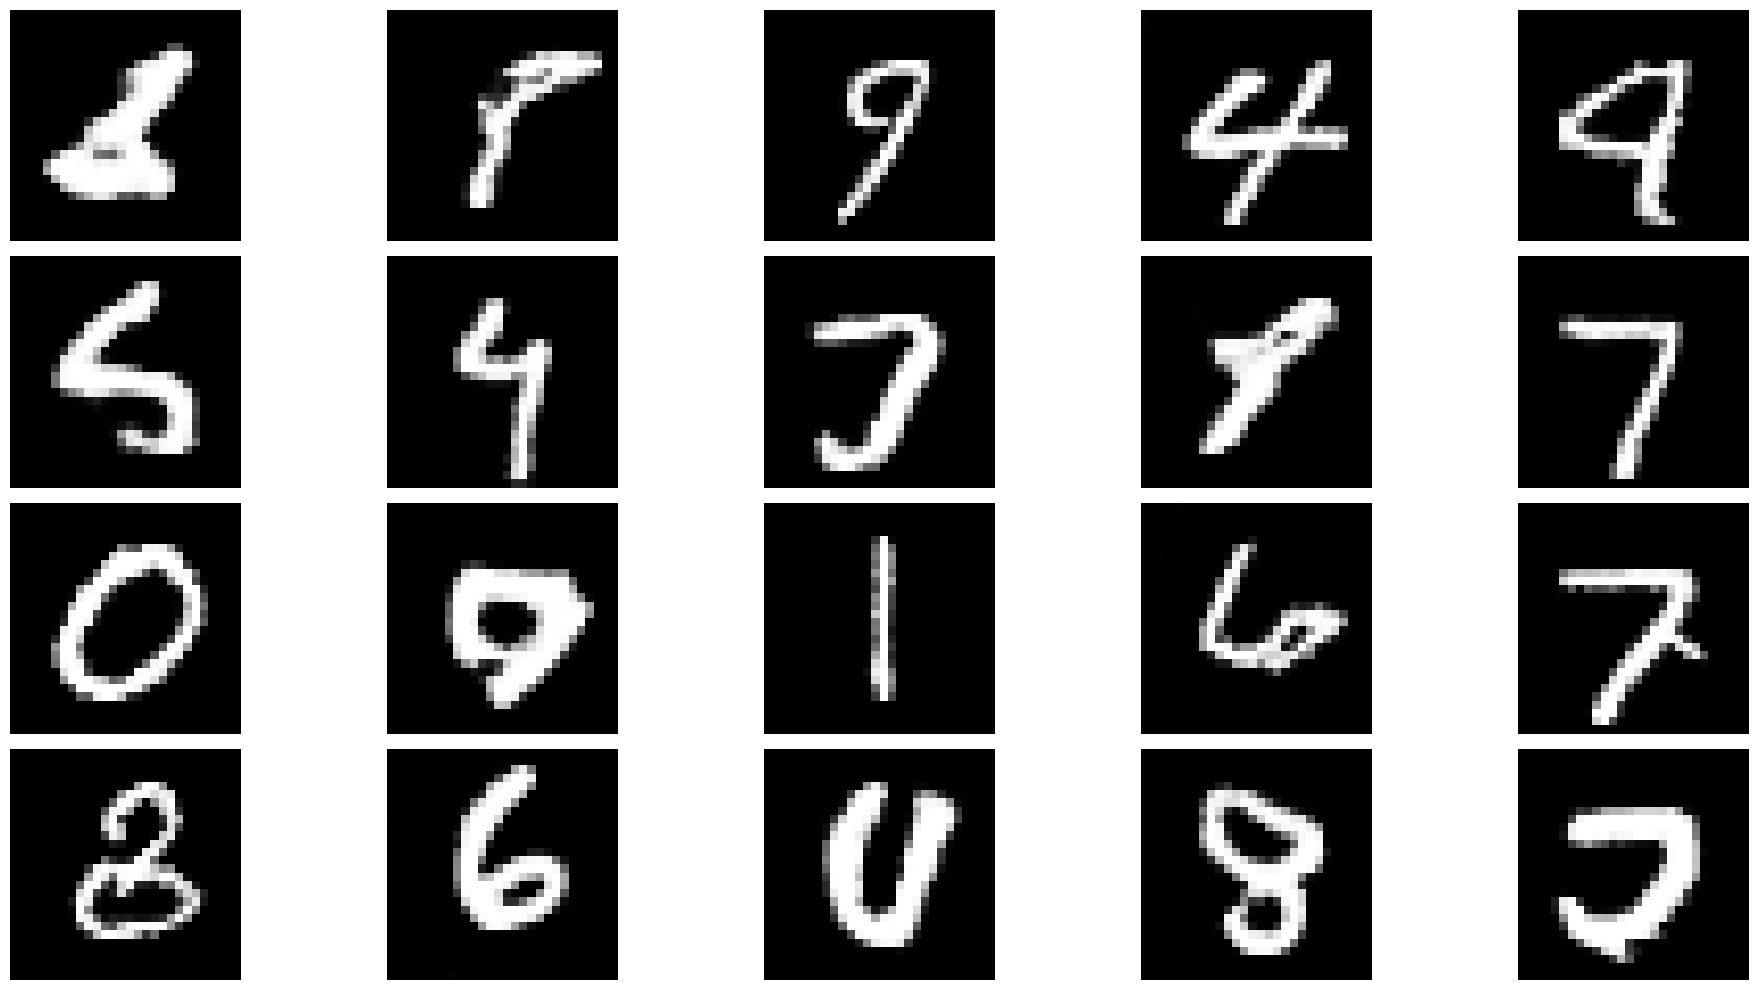

📈 Epoch 80 Summary:
   Train D Loss: 0.6272, Val D Loss: 1.8568
   Train G Loss: 2.2367, Val G Loss: 3.3768

📊 Epoch 81/100
----------------------------------------
Epoch: 81 [0/60000 (0%)]	D_loss: 0.538263	G_loss: 1.911277
Epoch: 81 [6400/60000 (11%)]	D_loss: 1.004441	G_loss: 2.502195
Epoch: 81 [12800/60000 (21%)]	D_loss: 0.551371	G_loss: 1.906256
Epoch: 81 [19200/60000 (32%)]	D_loss: 0.837466	G_loss: 1.523182
Epoch: 81 [25600/60000 (43%)]	D_loss: 0.477584	G_loss: 3.120462
Epoch: 81 [32000/60000 (53%)]	D_loss: 0.818804	G_loss: 2.727448
Epoch: 81 [38400/60000 (64%)]	D_loss: 0.492896	G_loss: 1.888511
Epoch: 81 [44800/60000 (75%)]	D_loss: 0.486295	G_loss: 2.271189
Epoch: 81 [51200/60000 (85%)]	D_loss: 0.625711	G_loss: 2.301544
Epoch: 81 [57600/60000 (96%)]	D_loss: 0.516830	G_loss: 2.899580
====> Epoch: 81 Train D_loss: 0.6283, Train G_loss: 2.2416
====> Epoch: 81 Val D_loss: 1.1094, Val G_loss: 1.0667
📈 Epoch 81 Summary:
   Train D Loss: 0.6283, Val D Loss: 1.1094
   Train G Loss: 2.2416

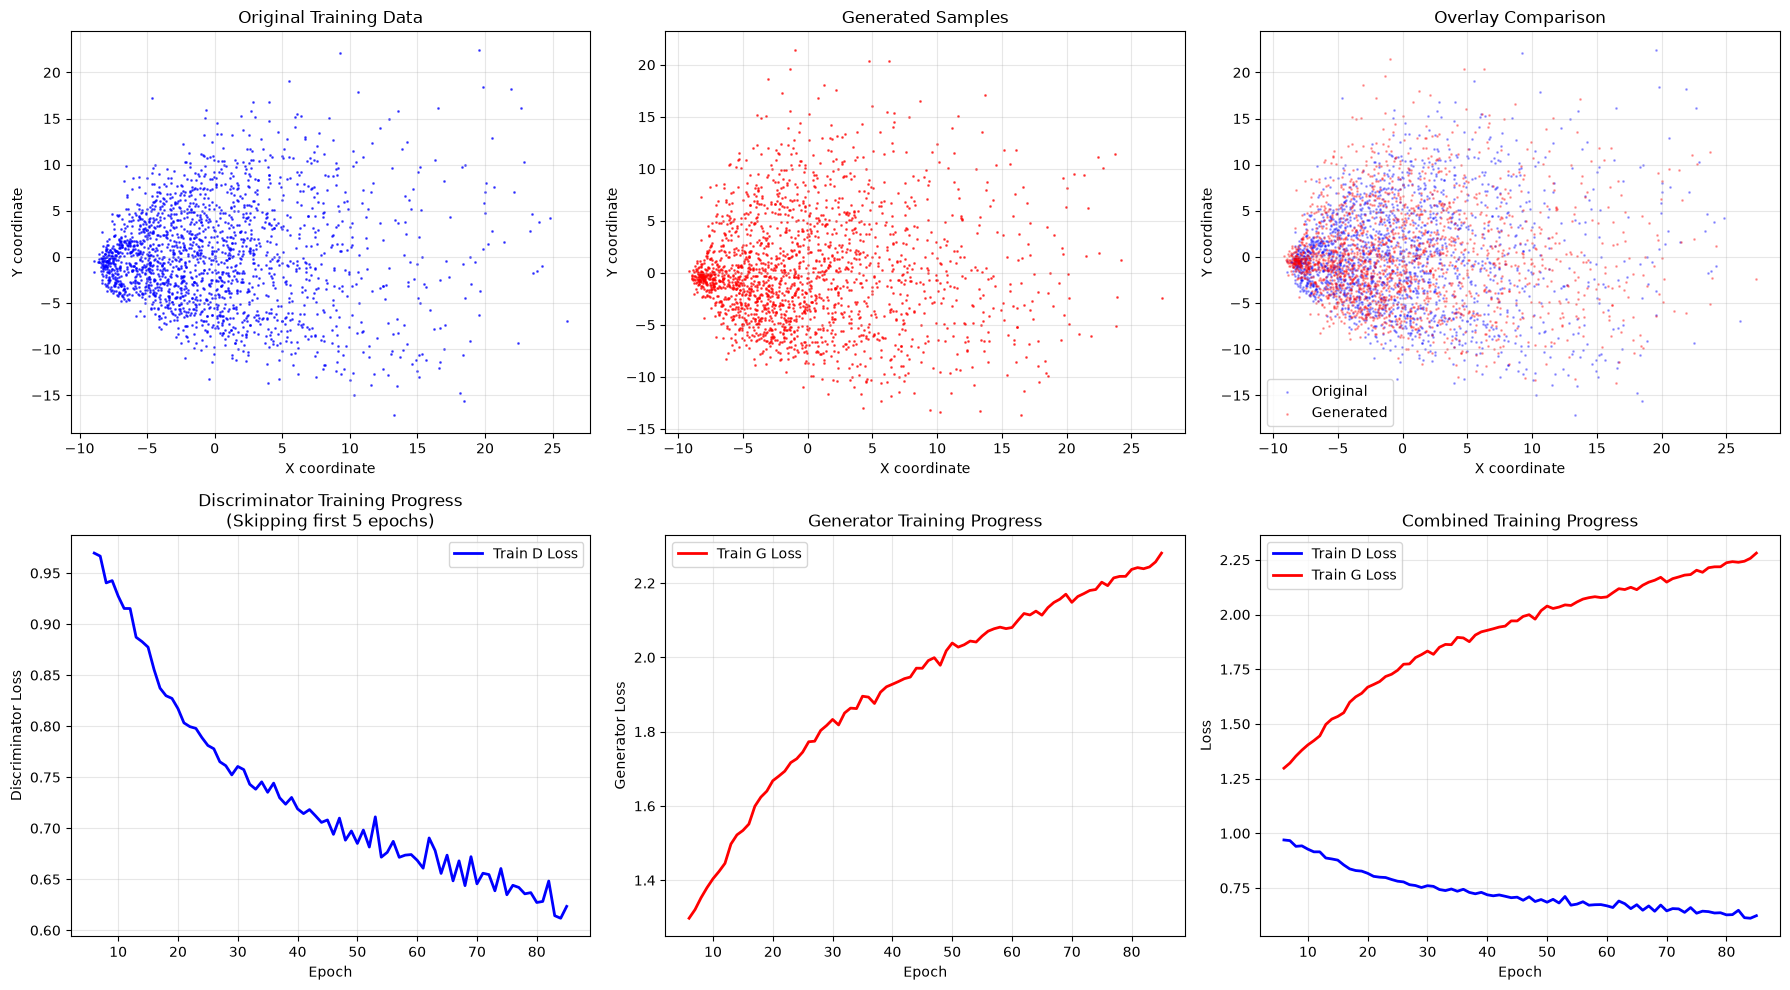

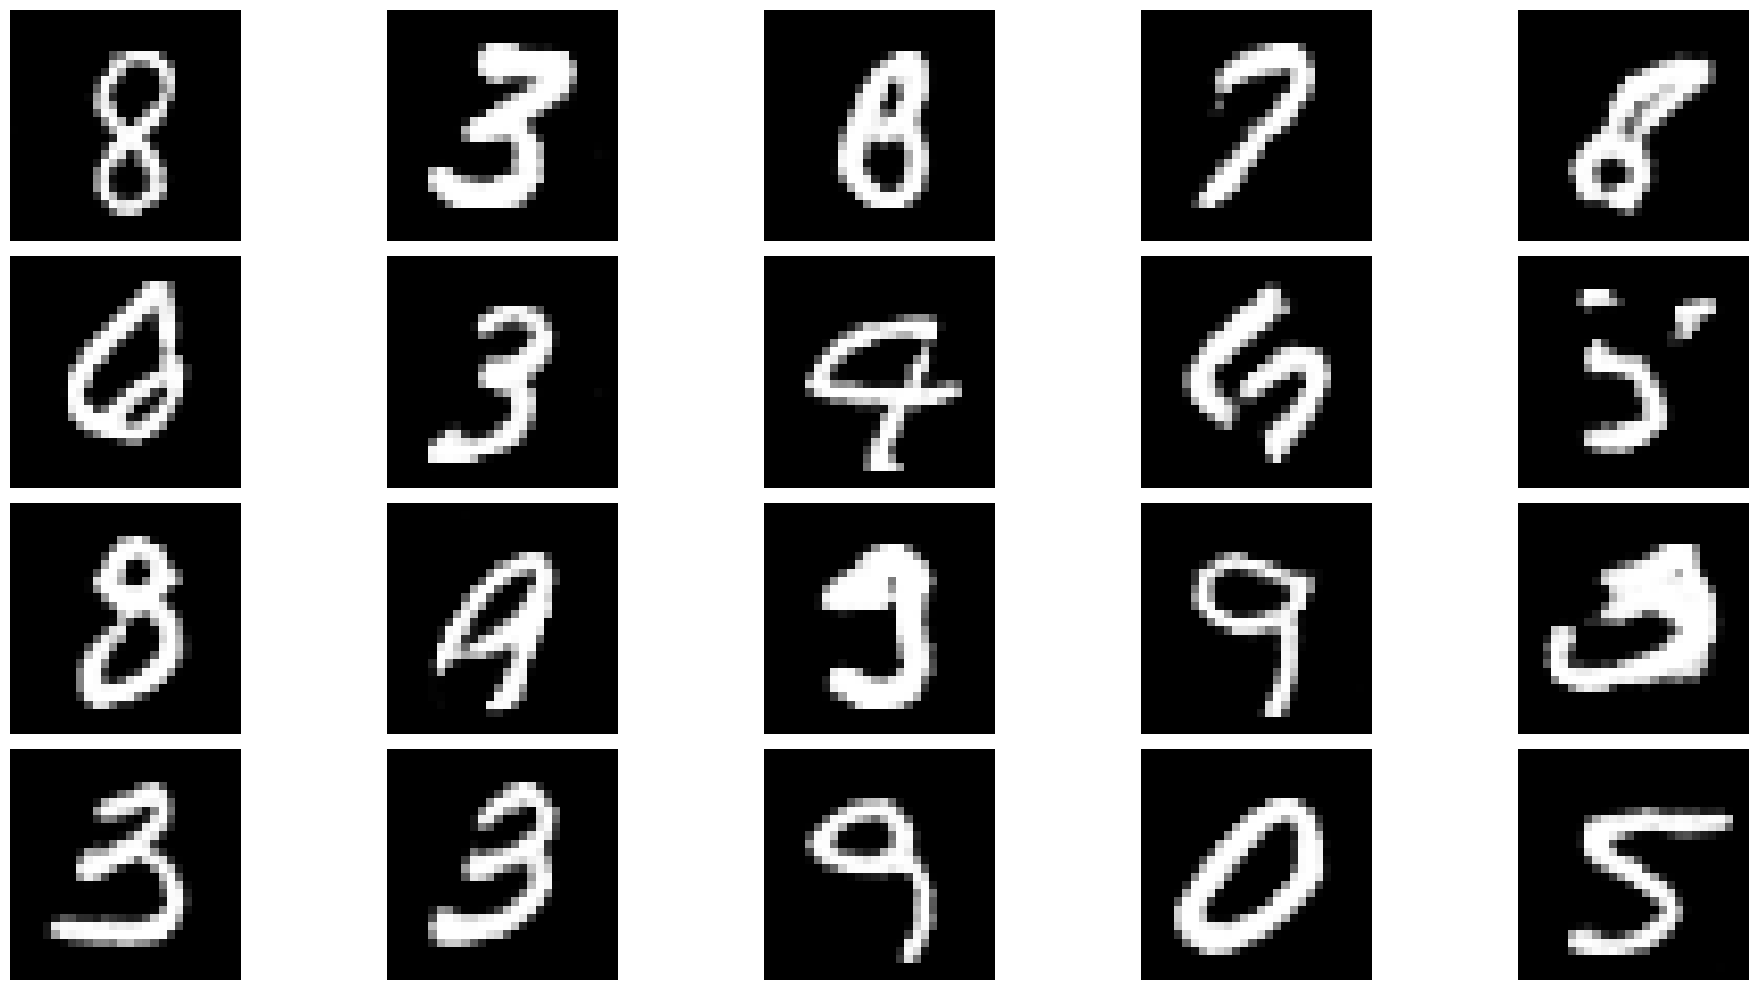

📈 Epoch 85 Summary:
   Train D Loss: 0.6234, Val D Loss: 0.9973
   Train G Loss: 2.2807, Val G Loss: 1.5163

📊 Epoch 86/100
----------------------------------------
Epoch: 86 [0/60000 (0%)]	D_loss: 0.549010	G_loss: 1.855342
Epoch: 86 [6400/60000 (11%)]	D_loss: 0.555592	G_loss: 3.299401
Epoch: 86 [12800/60000 (21%)]	D_loss: 0.707771	G_loss: 2.489491
Epoch: 86 [19200/60000 (32%)]	D_loss: 0.570087	G_loss: 2.998054
Epoch: 86 [25600/60000 (43%)]	D_loss: 0.809673	G_loss: 1.060807
Epoch: 86 [32000/60000 (53%)]	D_loss: 0.531734	G_loss: 2.328876
Epoch: 86 [38400/60000 (64%)]	D_loss: 0.593277	G_loss: 2.154612
Epoch: 86 [44800/60000 (75%)]	D_loss: 0.627674	G_loss: 1.729505
Epoch: 86 [51200/60000 (85%)]	D_loss: 0.720944	G_loss: 1.340125
Epoch: 86 [57600/60000 (96%)]	D_loss: 0.844023	G_loss: 2.634364
====> Epoch: 86 Train D_loss: 0.6108, Train G_loss: 2.2923
====> Epoch: 86 Val D_loss: 1.0435, Val G_loss: 1.3767
📈 Epoch 86 Summary:
   Train D Loss: 0.6108, Val D Loss: 1.0435
   Train G Loss: 2.2923

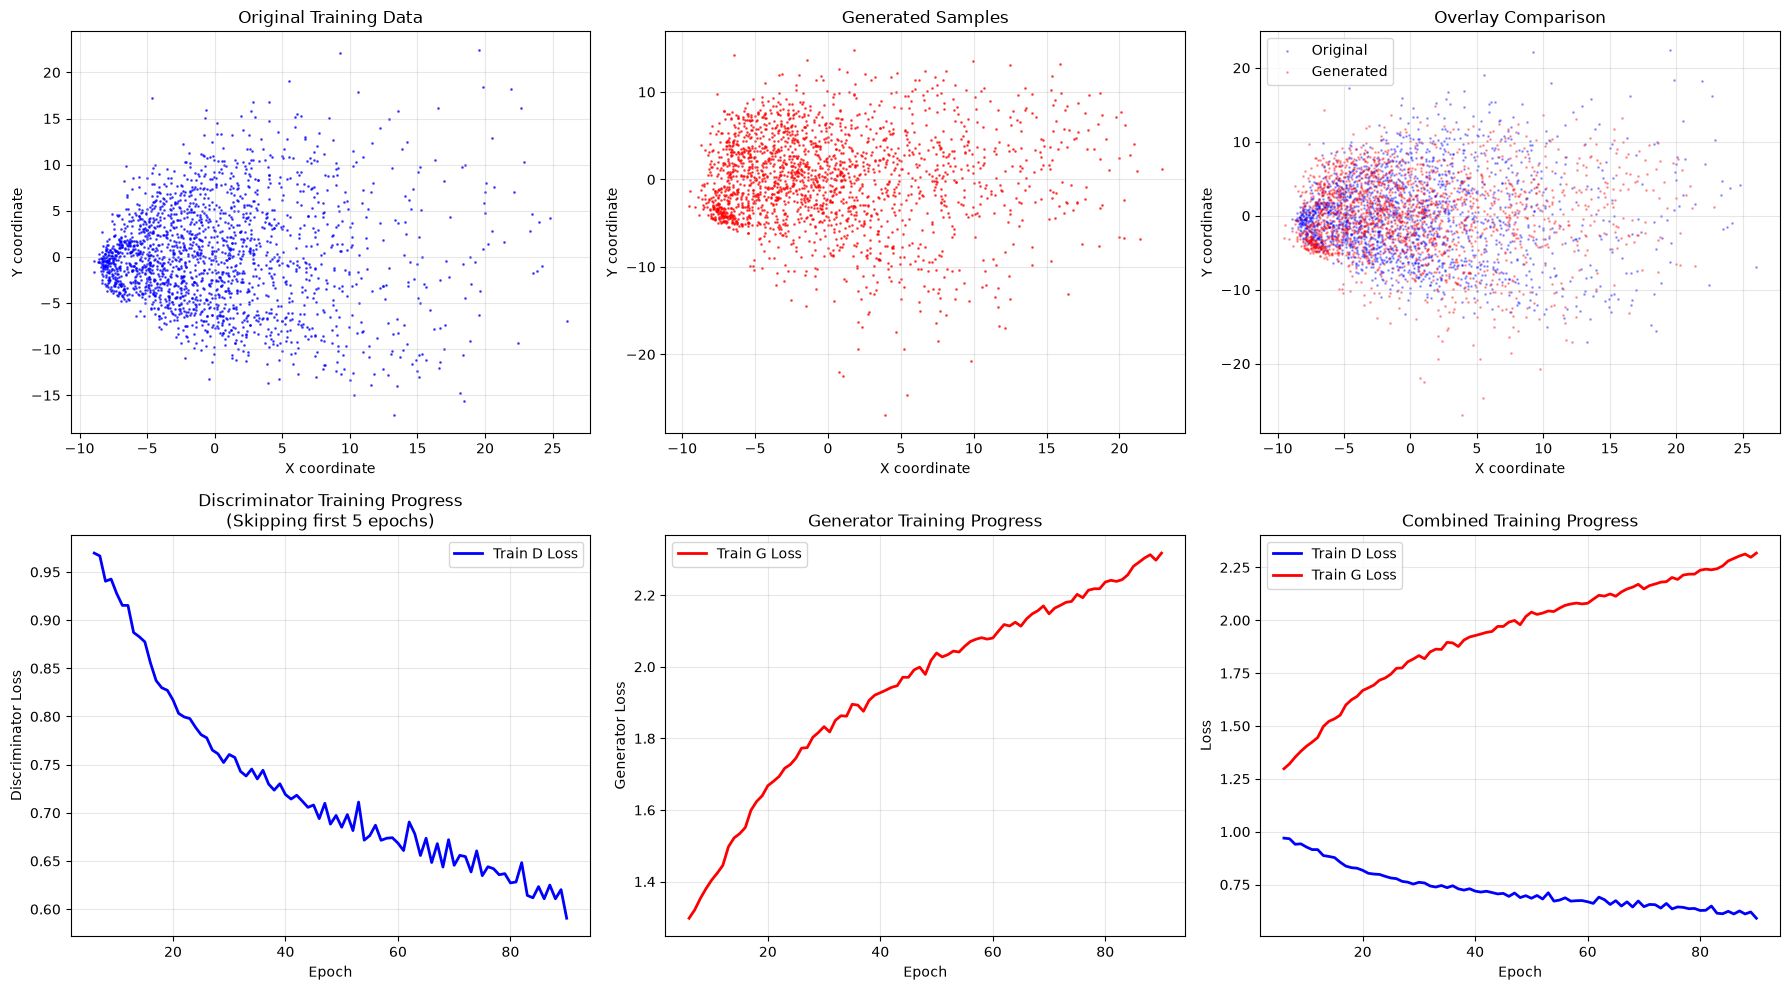

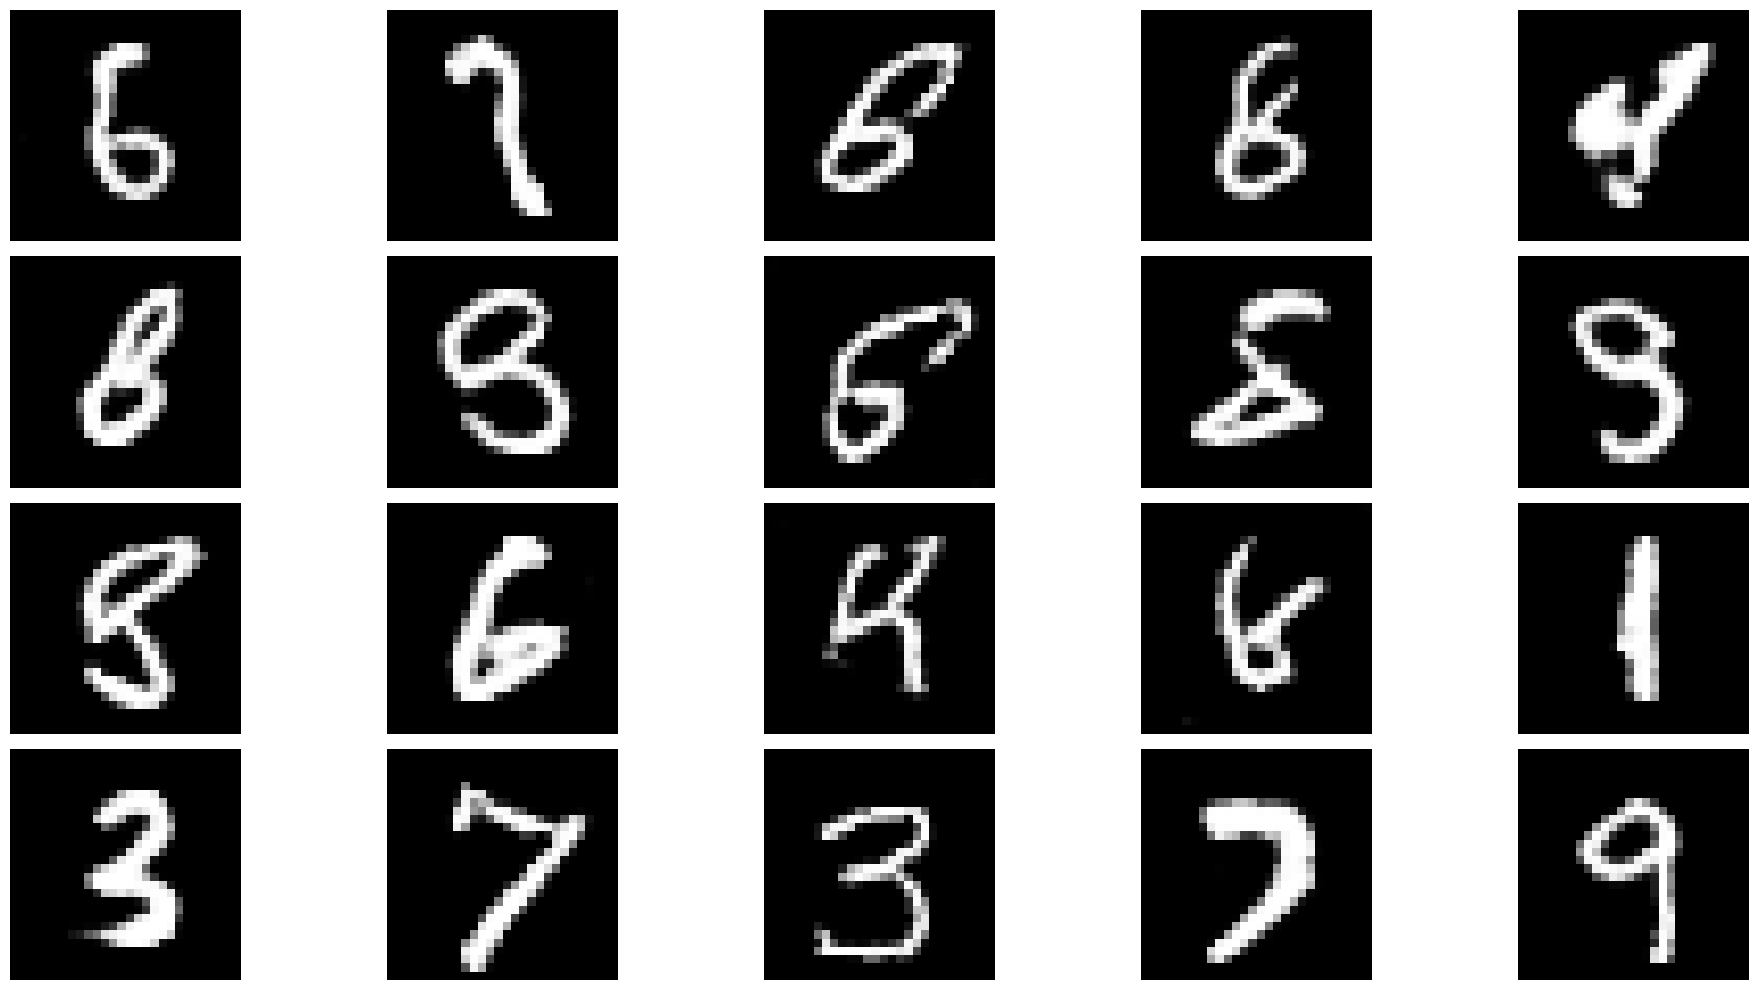

📈 Epoch 90 Summary:
   Train D Loss: 0.5906, Val D Loss: 1.4735
   Train G Loss: 2.3176, Val G Loss: 2.9505

📊 Epoch 91/100
----------------------------------------
Epoch: 91 [0/60000 (0%)]	D_loss: 0.516109	G_loss: 2.217501
Epoch: 91 [6400/60000 (11%)]	D_loss: 0.443024	G_loss: 2.226240
Epoch: 91 [12800/60000 (21%)]	D_loss: 0.626922	G_loss: 1.461334
Epoch: 91 [19200/60000 (32%)]	D_loss: 0.878255	G_loss: 2.863853
Epoch: 91 [25600/60000 (43%)]	D_loss: 0.465262	G_loss: 1.804329
Epoch: 91 [32000/60000 (53%)]	D_loss: 0.720892	G_loss: 2.787934
Epoch: 91 [38400/60000 (64%)]	D_loss: 0.636990	G_loss: 1.387222
Epoch: 91 [44800/60000 (75%)]	D_loss: 0.587057	G_loss: 1.274508
Epoch: 91 [51200/60000 (85%)]	D_loss: 1.198959	G_loss: 0.701765
Epoch: 91 [57600/60000 (96%)]	D_loss: 0.876854	G_loss: 3.129233
====> Epoch: 91 Train D_loss: 0.6123, Train G_loss: 2.3283
====> Epoch: 91 Val D_loss: 1.1754, Val G_loss: 1.6466
📈 Epoch 91 Summary:
   Train D Loss: 0.6123, Val D Loss: 1.1754
   Train G Loss: 2.3283

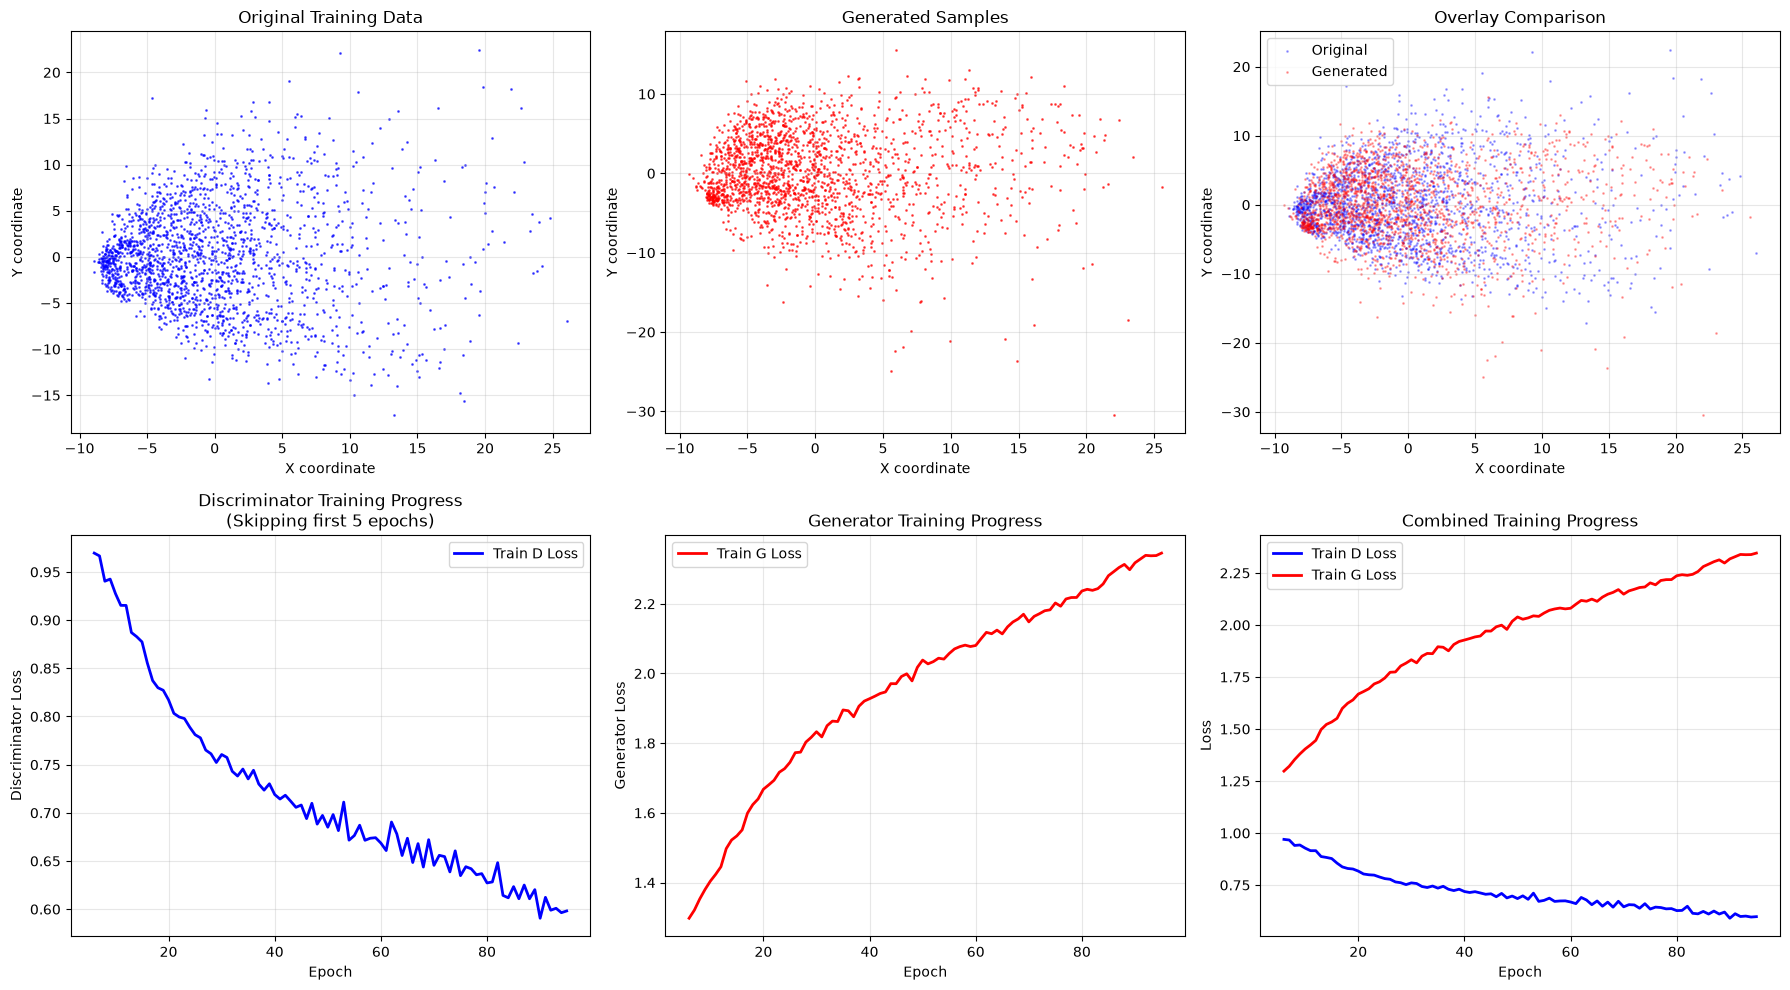

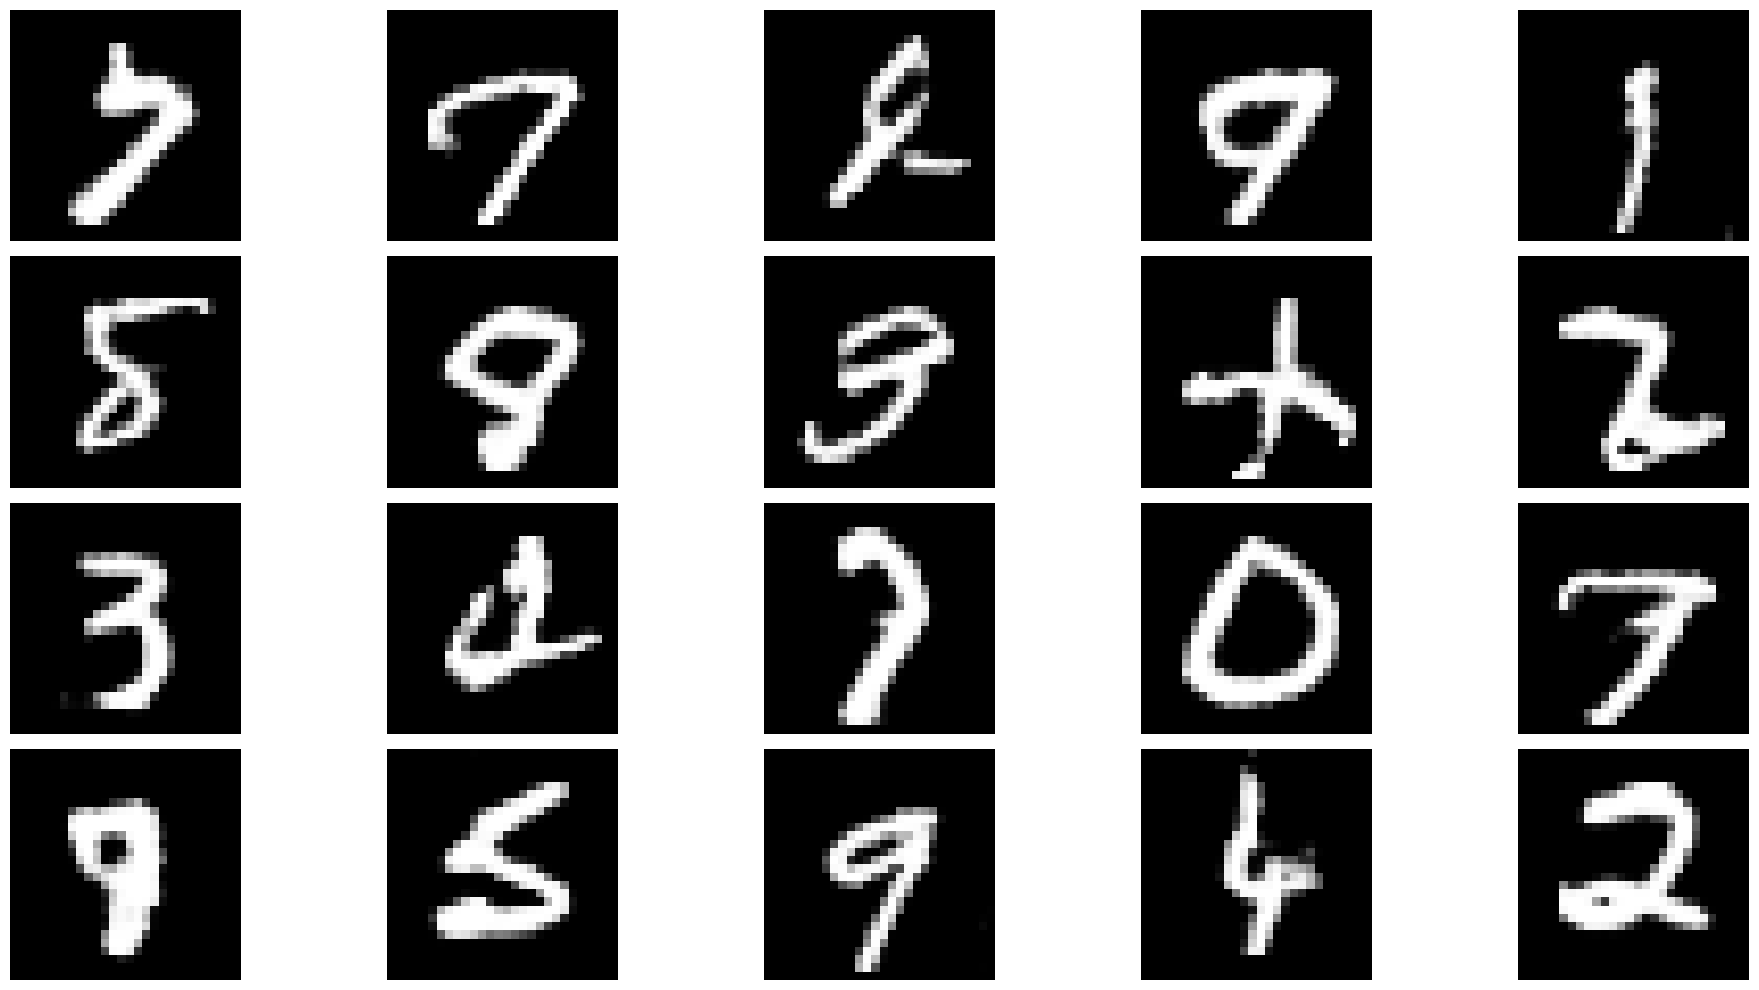

📈 Epoch 95 Summary:
   Train D Loss: 0.5982, Val D Loss: 1.0989
   Train G Loss: 2.3455, Val G Loss: 1.2340

📊 Epoch 96/100
----------------------------------------
Epoch: 96 [0/60000 (0%)]	D_loss: 0.665256	G_loss: 2.631989
Epoch: 96 [6400/60000 (11%)]	D_loss: 0.659726	G_loss: 1.958908
Epoch: 96 [12800/60000 (21%)]	D_loss: 0.758714	G_loss: 2.272740
Epoch: 96 [19200/60000 (32%)]	D_loss: 0.771277	G_loss: 0.677202
Epoch: 96 [25600/60000 (43%)]	D_loss: 0.567541	G_loss: 1.980388
Epoch: 96 [32000/60000 (53%)]	D_loss: 0.626644	G_loss: 2.593529
Epoch: 96 [38400/60000 (64%)]	D_loss: 0.637521	G_loss: 1.983352
Epoch: 96 [44800/60000 (75%)]	D_loss: 0.562742	G_loss: 2.669711
Epoch: 96 [51200/60000 (85%)]	D_loss: 0.569226	G_loss: 1.849028
Epoch: 96 [57600/60000 (96%)]	D_loss: 0.494922	G_loss: 3.195215
====> Epoch: 96 Train D_loss: 0.6466, Train G_loss: 2.3574
====> Epoch: 96 Val D_loss: 1.1917, Val G_loss: 2.2731
📈 Epoch 96 Summary:
   Train D Loss: 0.6466, Val D Loss: 1.1917
   Train G Loss: 2.3574

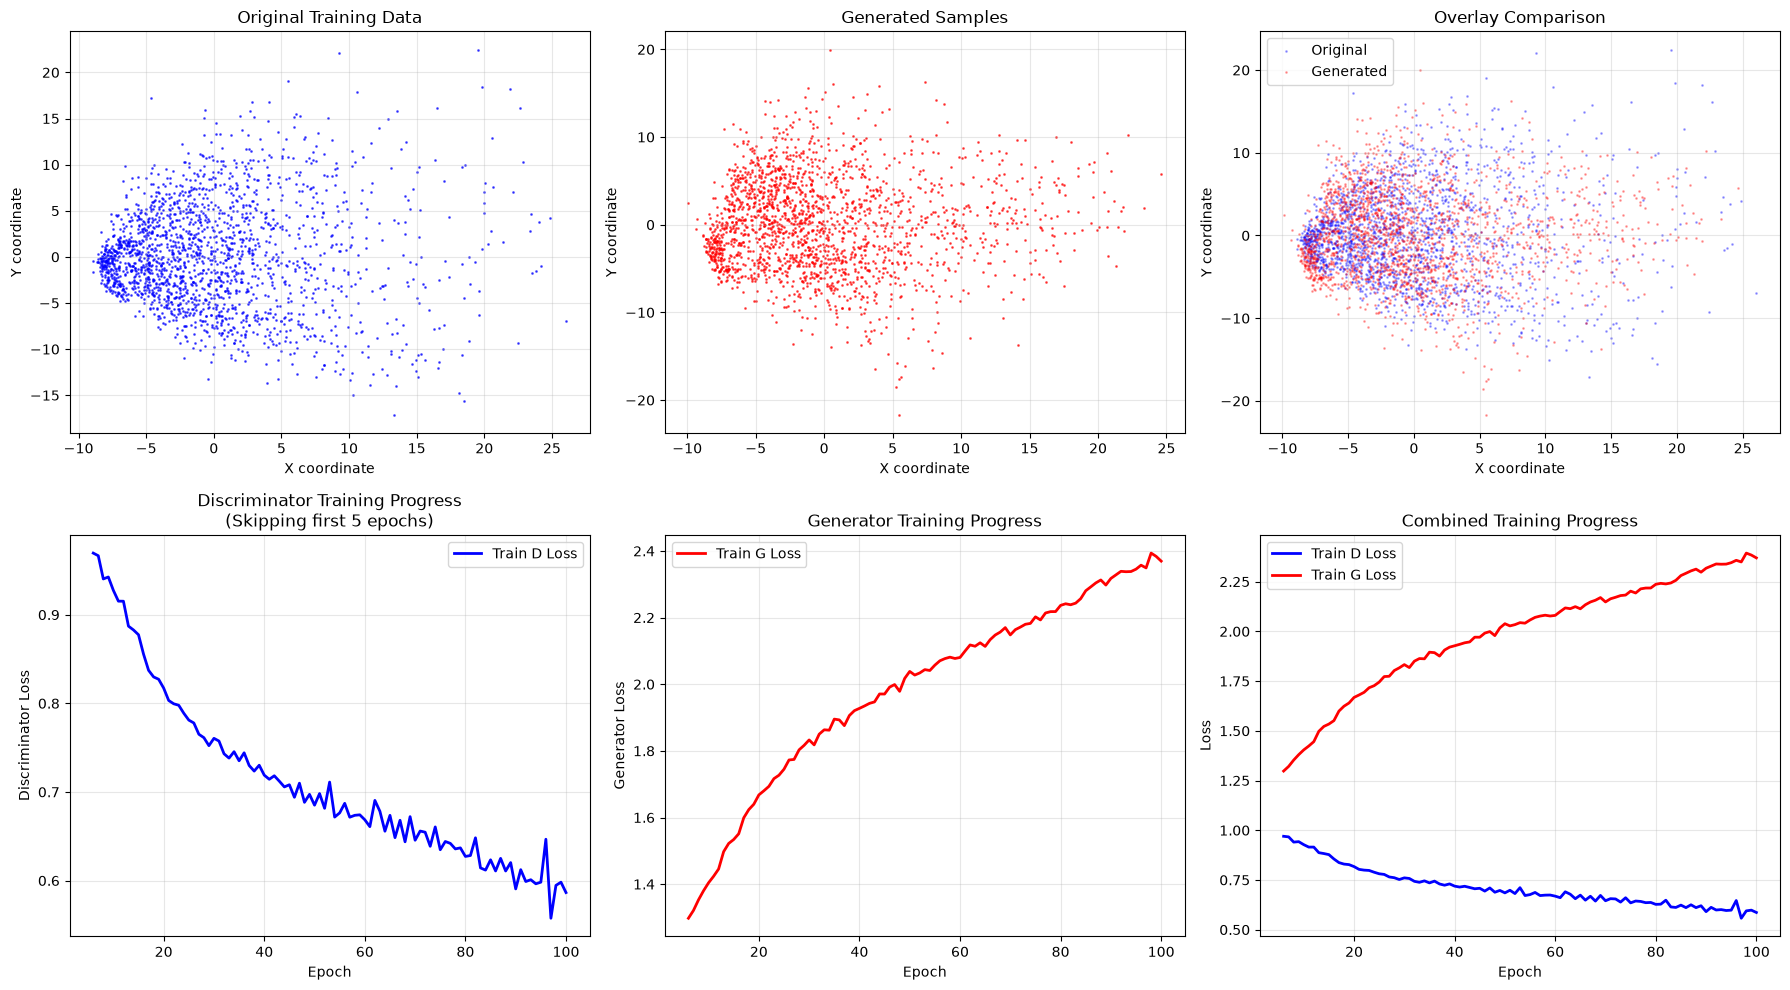

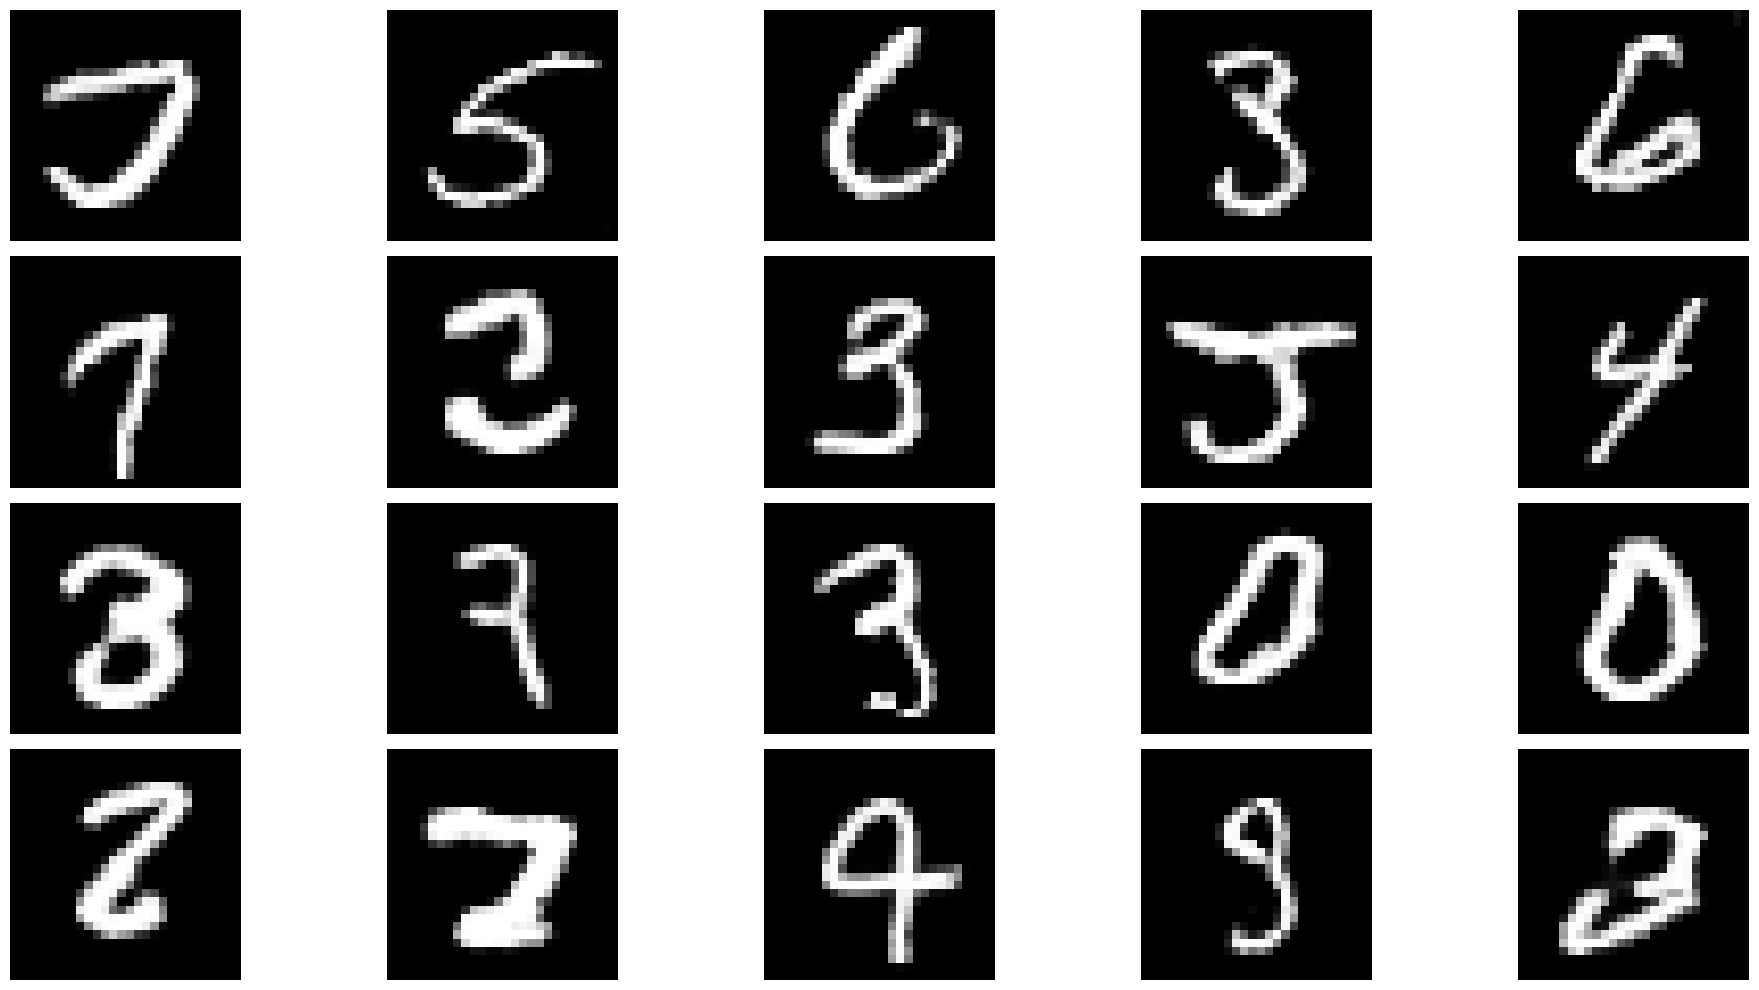

📈 Epoch 100 Summary:
   Train D Loss: 0.5865, Val D Loss: 1.5624
   Train G Loss: 2.3696, Val G Loss: 3.0200

🎉 Training completed!

🎨 Final comprehensive visualization:


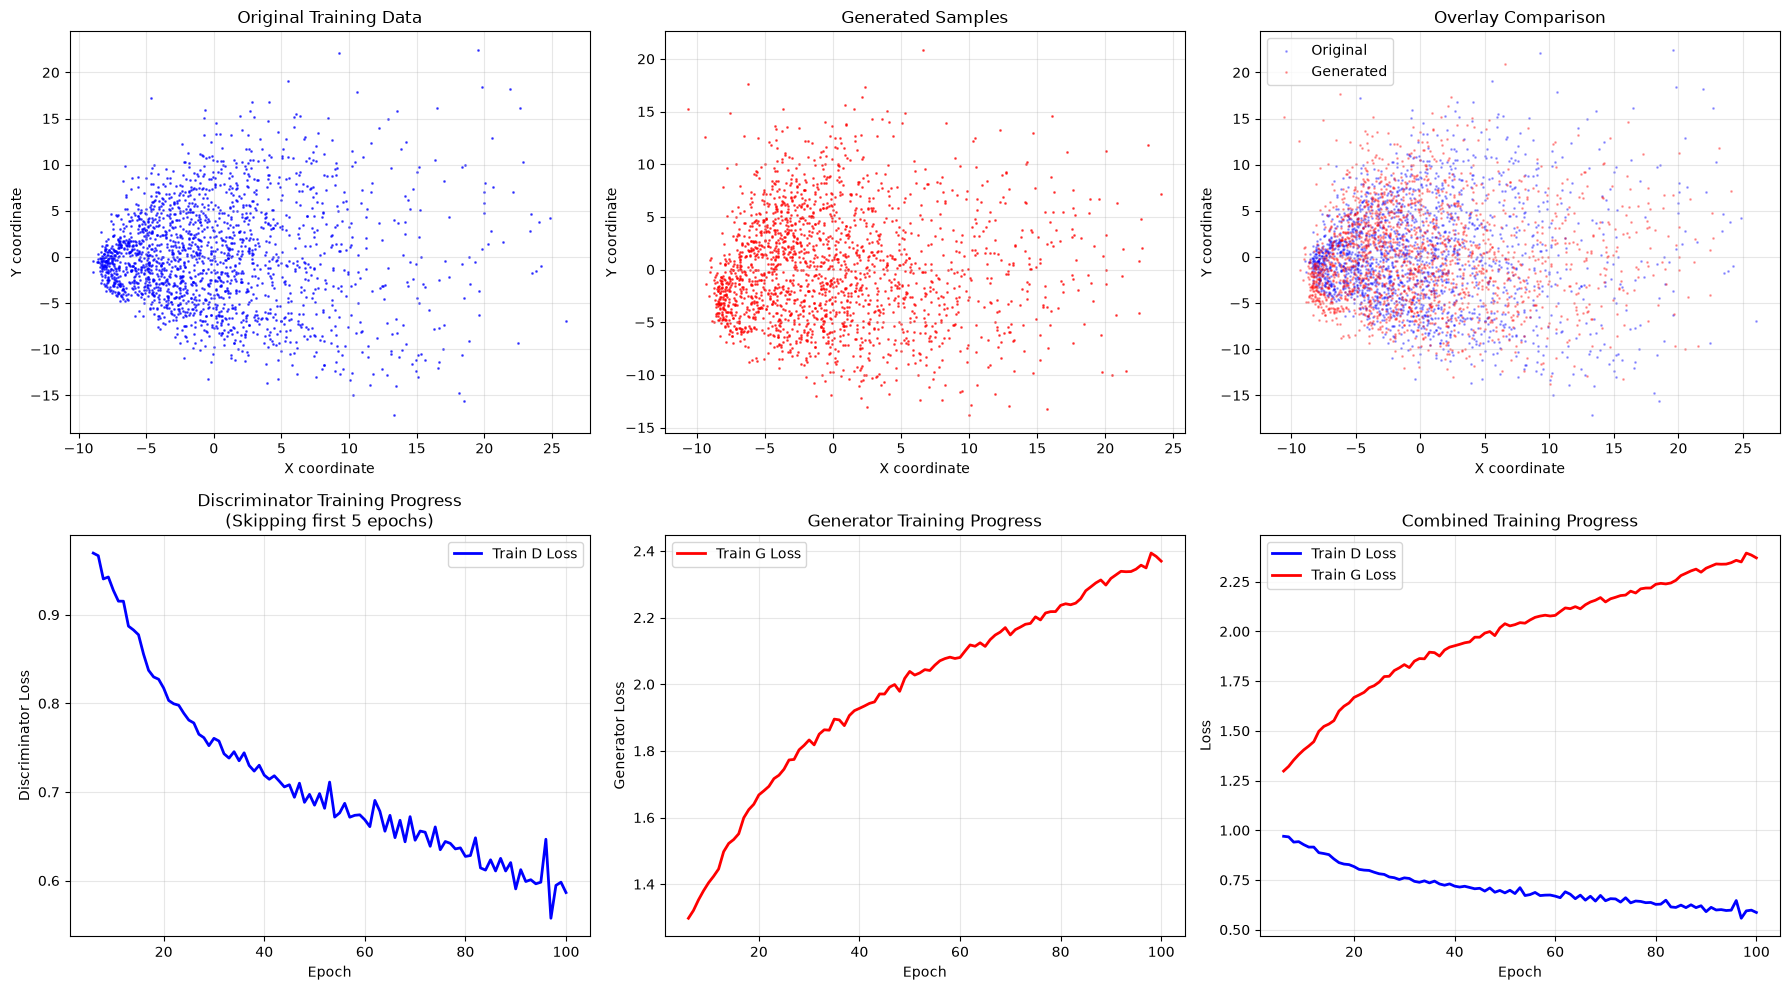

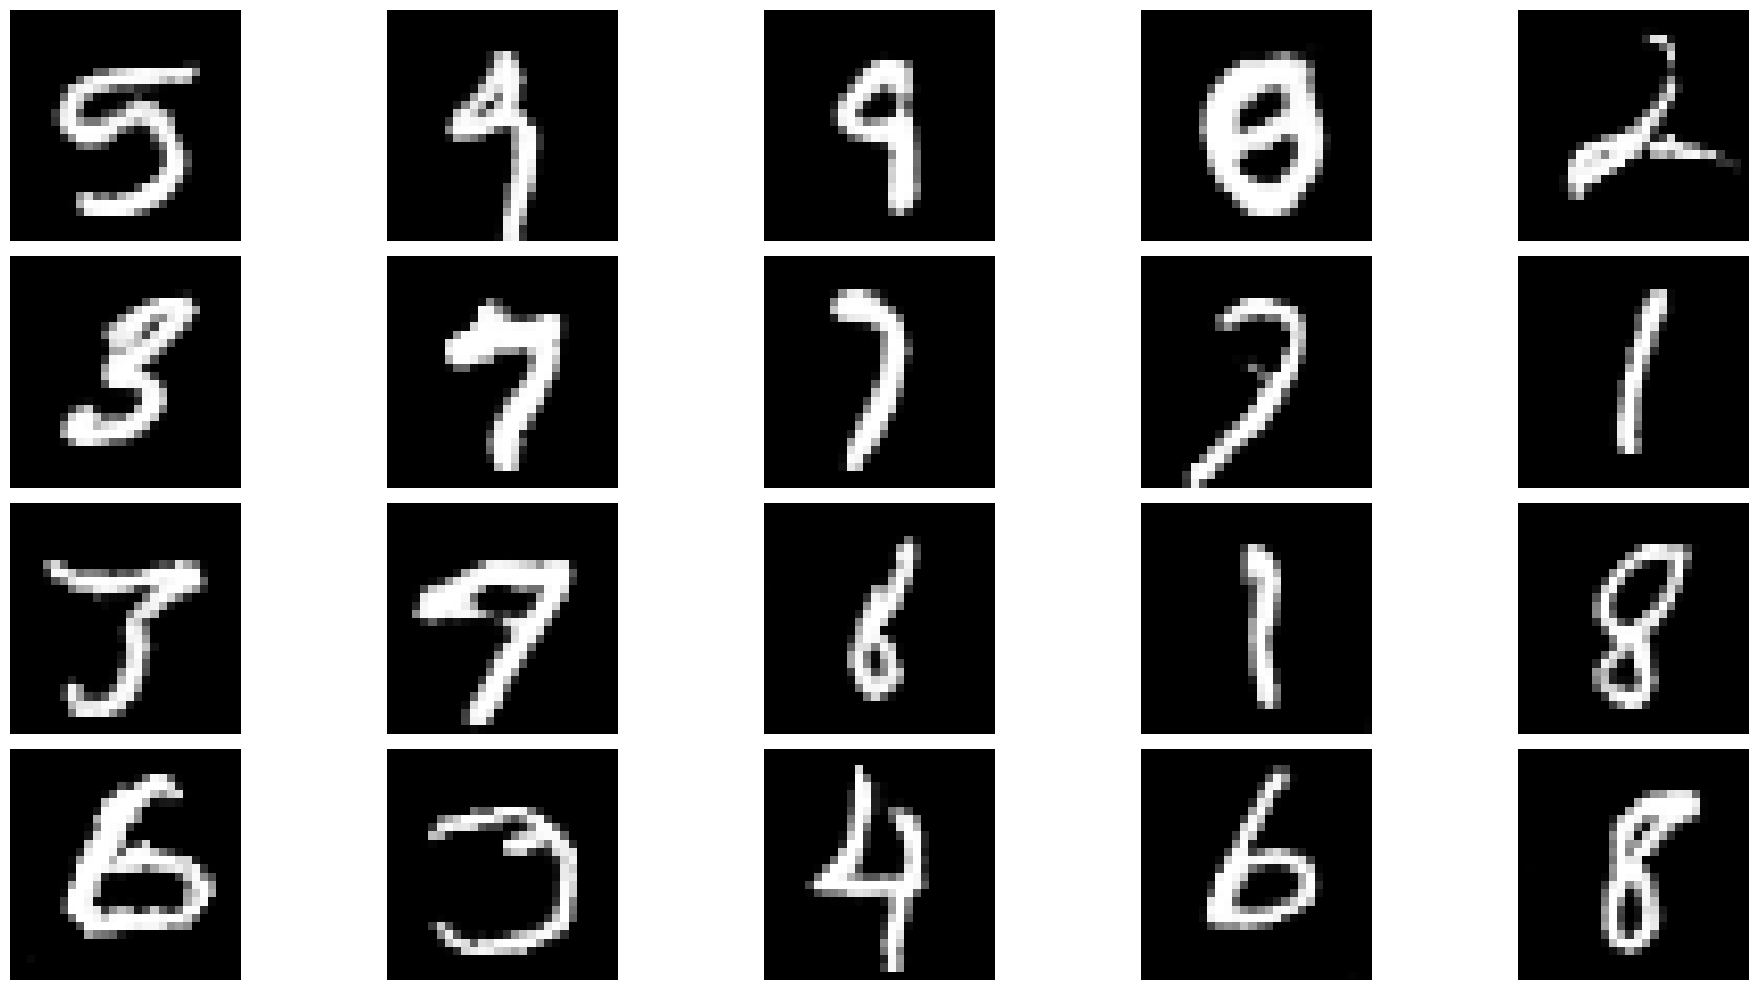

In [14]:
# Training loop
print("🎯 Starting GAN training...")
print("=" * 60)

# Lists to track training progress
train_d_losses = []
train_g_losses = []
val_d_losses = []
val_g_losses = []

# Show initial state (before training)
print("📊 Initial state (before training):")

for epoch in range(1, EPOCHS + 1):
    print(f"\n📊 Epoch {epoch}/{EPOCHS}")
    print("-" * 40)
    
    # Train for one epoch with validation
    train_d_loss, train_g_loss, val_d_loss, val_g_loss = train_epoch_with_validation(epoch)
    
    # Track losses
    train_d_losses.append(train_d_loss)
    train_g_losses.append(train_g_loss)
    val_d_losses.append(val_d_loss)
    val_g_losses.append(val_g_loss)
    
    # Visualize progress every 5 epochs
    if epoch % SAVE_PLT_INTERVAL == 0:
        print(f"\n🎨 Visualizing progress at epoch {epoch}...")
        visualize_training_progress(epoch, train_d_losses, train_g_losses, val_d_losses, val_g_losses)
    
    print(f"📈 Epoch {epoch} Summary:")
    print(f"   Train D Loss: {train_d_loss:.4f}, Val D Loss: {val_d_loss:.4f}")
    print(f"   Train G Loss: {train_g_loss:.4f}, Val G Loss: {val_g_loss:.4f}")

print("\n🎉 Training completed!")
print("=" * 60)

# Save the trained models
# torch.save(generator.state_dict(), 'generator.pth')
# torch.save(discriminator.state_dict(), 'discriminator.pth')
# print("💾 Models saved as 'generator.pth' and 'discriminator.pth'")

# Final comprehensive visualization
print("\n🎨 Final comprehensive visualization:")
visualize_training_progress(EPOCHS, train_d_losses, train_g_losses, val_d_losses, val_g_losses)


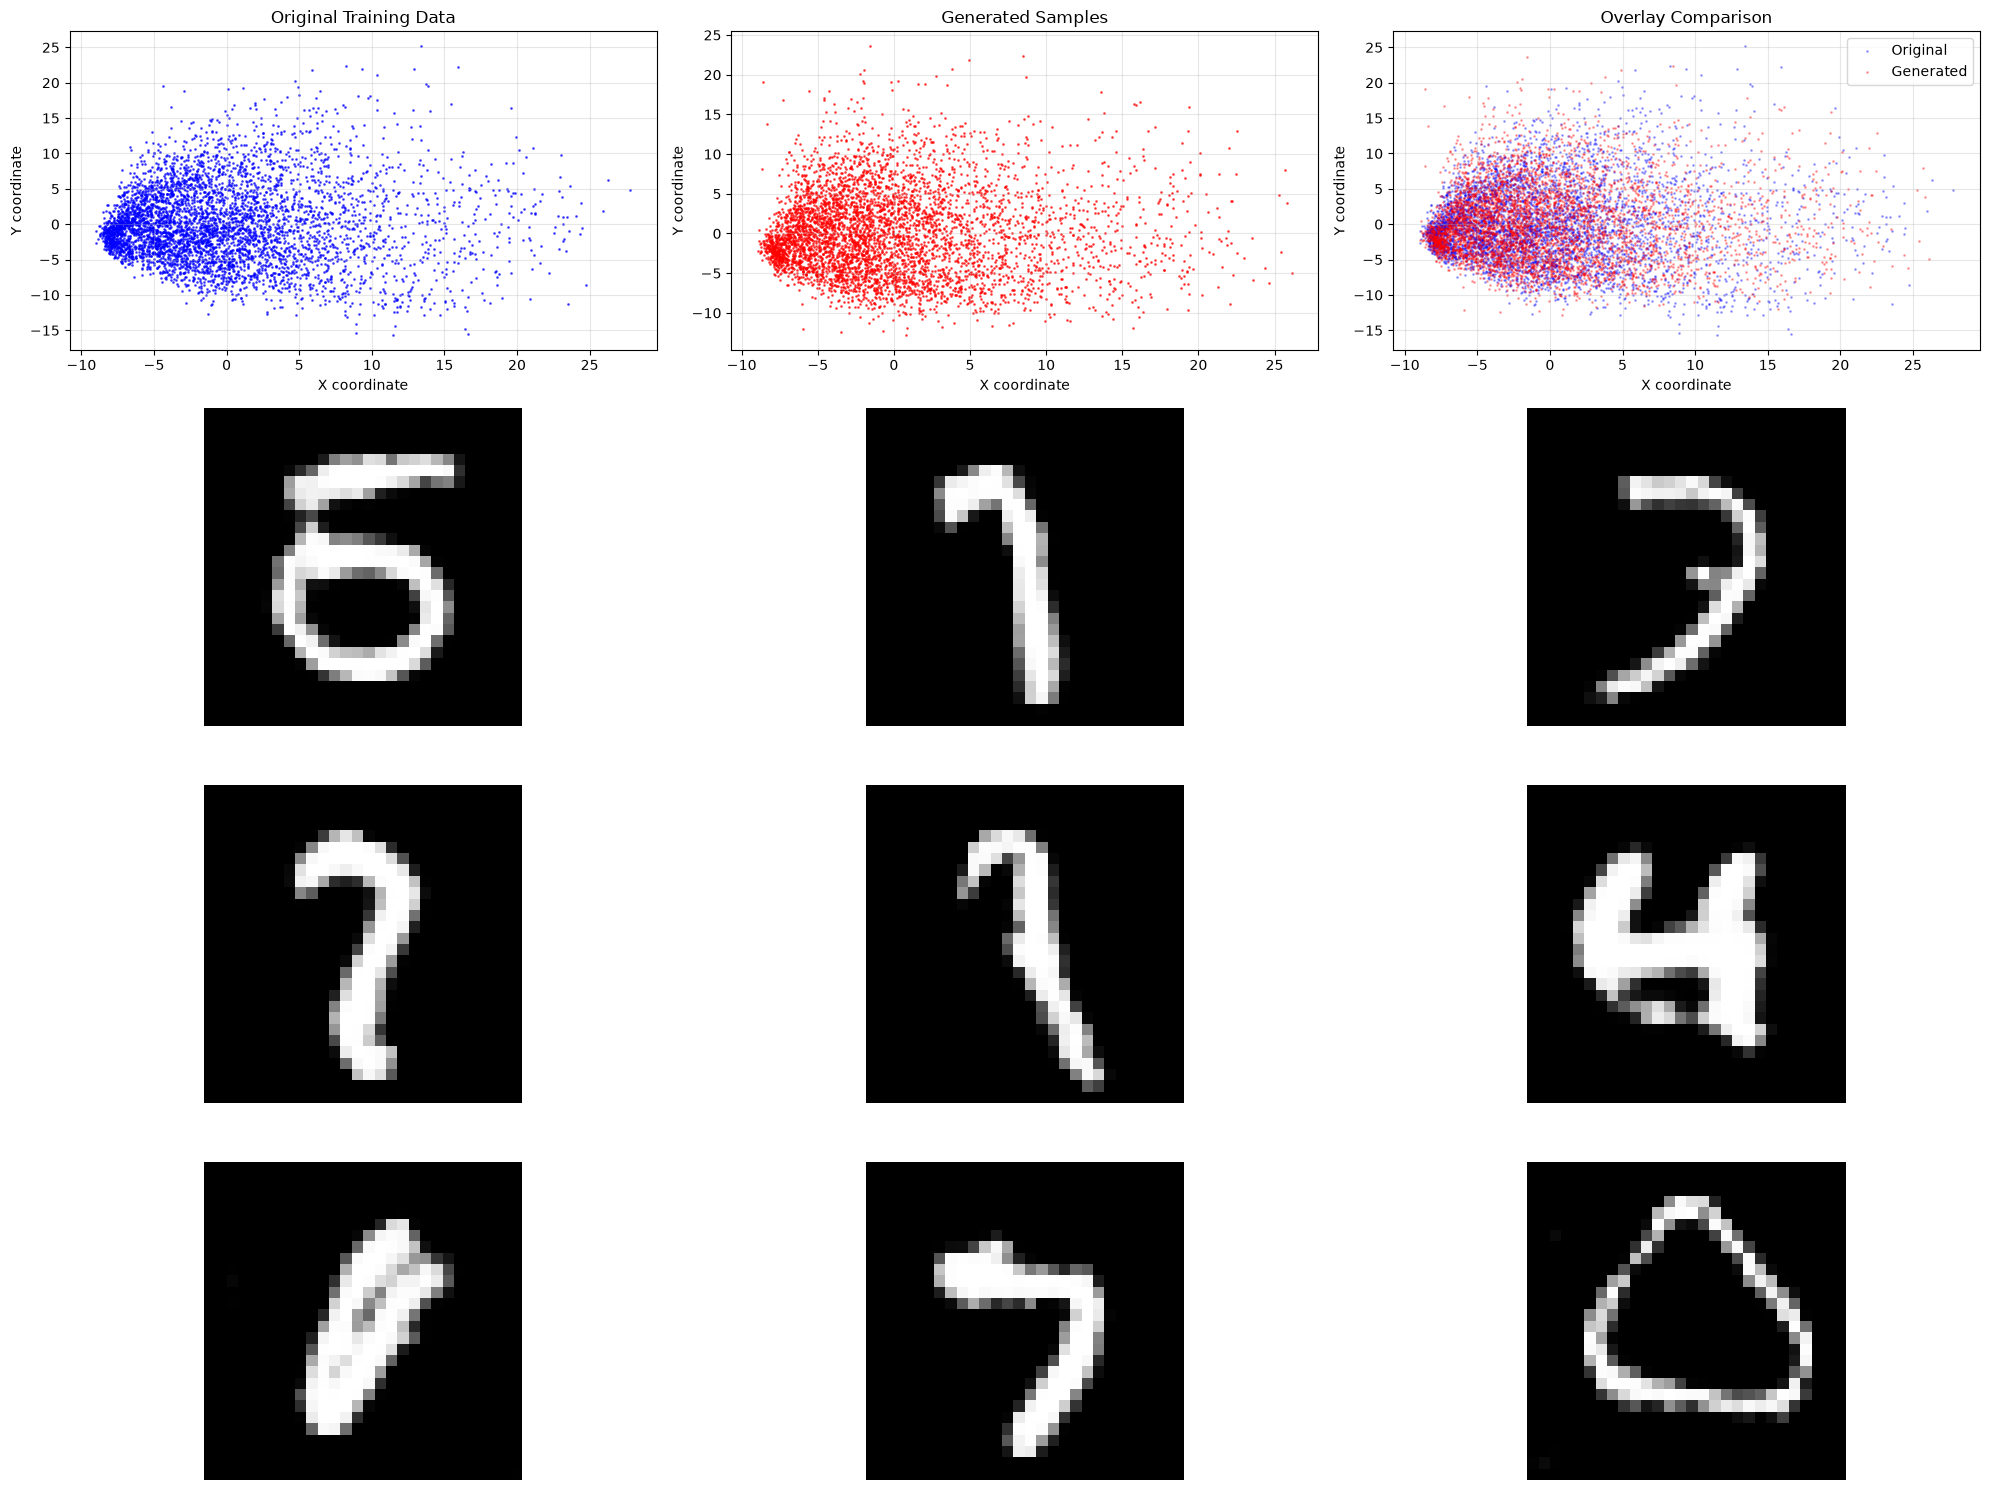

Real data confidence: 0.427
Fake data confidence: 0.114


In [15]:
# Generate a large number of samples
generated_samples = generate_samples(5000)

# Create comprehensive visualization
plt.figure(figsize=(20, 15))

train_data_reshaped = np.reshape(train_data.data[:5000], [5000, INPUT_DIM])
data_transformed = pca_fit(train_data_reshaped).transform(train_data_reshaped)
x_transformed = pca_fit(generated_samples).transform(generated_samples)

# Original training data
plt.subplot(4, 3, 1)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.6)
plt.title('Original Training Data')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Generated samples
plt.subplot(4, 3, 2)
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.6)
plt.title('Generated Samples')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.grid(True, alpha=0.3)

# Overlay comparison
plt.subplot(4, 3, 3)
plt.scatter(data_transformed[:, 0], data_transformed[:, 1], c='blue', s=1, alpha=0.3, label='Original')
plt.scatter(x_transformed[:, 0], x_transformed[:, 1], c='red', s=1, alpha=0.3, label='Generated')
plt.title('Overlay Comparison')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.legend()
plt.grid(True, alpha=0.3)


for i in range(9):
    plt.subplot(4, 3, 3 + i + 1)
    plt.imshow(np.reshape(generated_samples[i], [28, 28]).squeeze(), cmap="gray")
    plt.axis("off")

plt.tight_layout()
plt.show()


generator.eval()
discriminator.eval()
with torch.no_grad():
    # Test on real data
    real_batch = train_data.data[:100].unsqueeze(1).to(device).float() / 255.0
    real_pred = discriminator(real_batch).mean().item()

    # Test on fake data
    noise = torch.randn(100, NOISE_DIM).to(device)
    fake_batch = generator(noise)
    fake_pred = discriminator(fake_batch).mean().item()

print(f'Real data confidence: {real_pred:.3f}')
print(f'Fake data confidence: {fake_pred:.3f}')
